# Cooling profiles along the flow

For each snapshot, start at the highest-density native cell inside
$0\le X\le2r_p$, $-r_p\le Y,Z\le r_p$, with spherical radius
$r=\sqrt{X^2+Y^2+Z^2}\ge0.7r_p$ (outside the $0.6r_p$ smoothing core), and trace through
$s\in[-20,20]R_\odot$. Positive $s$ follows the flow;
consecutive visits to the same cell are collapsed. The matching maps are in
[0.1-timescales.ipynb](0.1-timescales.ipynb).

Plot $|u_\mathrm{orb}|$, $u_\mathrm{rad}$, $u_\mathrm{int}$ and the heating
prescriptions in $\mathrm{erg\,cm^{-3}}$:
$$
\dot{E}_\mathrm{diss}(100\,\mathrm{s}),\qquad
\int_{-20R_\odot}^{20R_\odot}\frac{\dot{E}_\mathrm{diss}}{|\mathbf v|}\,ds.
$$
Also plot $P_\mathrm{gas}$ from RICH and $P_\mathrm{rad}=u_\mathrm{rad}/3$.
`Erad` is specific radiation energy, so $u_\mathrm{rad}=\rho\,\mathtt{Erad}$.
Specific-energy panels use $P/\rho$; slice averages use the same weights as energy.

The orbital term uses the simulation's harmonic core, with
$r_0=0.6r_p$ and $r_s=2r_g=2GM/c^2$:
$$
\Phi(r)=
\begin{cases}
-\dfrac{GM}{r_0-r_s}
+\dfrac{GM(r^2-r_0^2)}{2r_0(r_0-r_s)^2}, & r<r_0,\\[6pt]
-\dfrac{GM}{r-r_s}, & r\geq r_0.
\end{cases}
$$
Inside the core this gives
$\mathbf a=-GM\,\mathbf r/[r_0(r_0-2r_g)^2]$.
The potential and its radial derivative are continuous at $r_0$.
Core cells are included in the energy averages and mass-flux integrals.
The $0.7r_p$ exclusion applies only to the initial maximum-density seed selection;
subsequent streamline tracing and slice calculations retain their existing selections.

The Bernoulli parameter, with signed orbital energy, is
$$
B=\frac{u_\mathrm{orb}+u_\mathrm{int}+u_\mathrm{rad}
+P_\mathrm{gas}+P_\mathrm{rad}}{\rho}.
$$
It is constant along steady streamlines with trapped isotropic radiation and
negligible external heating or nonadvective energy transport. Neither $\rho B$
nor our mass-weighted slice averages must be constant. Dissipation converts
existing energy between forms and is not an additional term in $B$.
The Bernoulli curve shows $B$ in specific-energy panels and $\rho B$ in
energy-density panels, using the same slice weights as the components. Plot
the magnitude on logarithmic axes and the signed change from the first point
on the right.

The second energy panel shows changes from the first upstream point for
energies and pressures (signed $u_\mathrm{orb}$); the heating prescriptions
remain unchanged.
Orbital and Bernoulli curves are solid for negative energy and dashed for positive energy,
with the same colour. This sign is taken before the absolute value or upstream
subtraction, also in the change panels; legend signs refer to that original energy.

Sample the projected time scales at the nearest grid column to each particle's
$(x,y)$ and plot $t_c/t_\mathrm{dyn}$, $t_v/t_\mathrm{dyn}$,
$t_\mathrm{es}/t_\mathrm{dyn}$ and $t_{\mathrm{es,ph}}/t_\mathrm{dyn}$
together, with a reference at unity:
$$
t_c = \frac{\int \rho\varepsilon_\mathrm{th}\,dz}{\int \alpha_p aT^4c\,dz},
\qquad t_\mathrm{dyn}=\sqrt{\frac{R_*^3}{GM_*}}
$$
$$
\Sigma=\int\rho\,dz,\qquad H=\bar z=\frac{\int\rho|z|\,dz}{\Sigma},
\qquad \bar{v_z}=\frac{\int\rho|v_z|\,dz}{\Sigma},\qquad t_v=\frac{H}{\bar{v_z}}
$$
$$
t_\mathrm{es}=\frac{H\tau}{c},\qquad \tau=\frac12\int\alpha_\mathrm{ross}\,dz=\frac{\tau_++\tau_-}{2}
$$

Here $\tau$ is half the full-column optical depth: the mean of the upward
and downward depths from $z=0$, not necessarily the actual upward depth
in an asymmetric column. All other column integrals retain both sides.

Integrate the columns over $z\in[-10r_p,10r_p]$. The thermal emission time
neglects reabsorption; the escape estimate uses $H\tau/c$ without a
light-crossing floor.

The second photon-escape estimate uses full-domain observer rays:
$$
\bar\tau_{\rm mid\to ph}
=\frac12\left[\int_0^{z_{\rm ph,+}}\alpha_{\rm R}\,dz
+\int_{z_{\rm ph,-}}^0\alpha_{\rm R}\,dz\right],\qquad
t_{\mathrm{es,ph}}=\frac{H_{\rm ph}\,\bar\tau_{\rm mid\to ph}}{c}.
$$
The midplane-to-photosphere depths are integrated separately on native-cell
rays; do not subtract $2/3$ from the finite-grid optical depth. Use trapezoids
with steps limited to one quarter of the endpoint cells' $V^{1/3}$, without an
optical-depth step cap for this deep integral. This keeps its cost tied to
spatial sampling rather than the potentially large total optical depth.
Show a gap when the two photospheres do not enclose $z=0$. The product of the
arithmetic-mean height and depth is used, without a light-crossing floor or
additional diffusion prefactor. The original $\tau$, $H$, $N_{95}$ and other
column diagnostics retain their finite projection grid.

The three additional energy figures compare single-cell specific energies,
mass-weighted specific energies in perpendicular slices, and density-weighted
energy densities in those slices. Use the same uniform $s$ grid as the tracer, with $0.05R_\odot$ spacing.
Each circular slice has radius $3r_p$, is normal to the local velocity, and
keeps the same origin-centered hemisphere as its local streamline point
$\mathbf r_c(s)$:
$$
\mathbf r\cdot\mathbf r_c(s)>0.
$$
The dividing plane passes through the origin and is perpendicular to
$\mathbf r_c(s)$; this selection rotates along the path, even across $x=0$.
Use native cell centers for volume averages and quadrature positions for
surface integrals. Cells inside the harmonic gravitational core remain eligible.
Also require
$$
\rho_i>f_\rho\,\rho_\mathrm{seed},\qquad f_\rho=10^{-5},
$$
where `SLICE_DENSITY_FRACTION` sets $f_\rho$ and $\rho_\mathrm{seed}$ is the
selected seed cell density, fixed for all slices in that snapshot. Apply this
cut to every slice numerator and denominator, including mass flux and heating.
For area quadrature, find the nearest native cell first, then reject samples
below the cut; do not fill their area with neighbouring denser cells. The
projected timescale columns and single-cell traces keep their original sampling.
With $u_i=\rho_i\varepsilon_i$:
$$
\langle\varepsilon\rangle_\rho=
\frac{\sum_i u_iV_i}{\sum_i\rho_iV_i}\quad[\mathrm{erg\,g^{-1}}],
\qquad
\langle u\rangle_\rho=
\frac{\sum_i\rho_i u_iV_i}{\sum_i\rho_iV_i}\quad[\mathrm{erg\,cm^{-3}}].
$$
A cell is included when its center is within $V_i^{1/3}$ of the plane and
within the circular aperture. This follows `richio`'s plane-proximity rule
and weights each selected cell once by its full native volume; it does not
calculate exact cell-plane intersections. Average signed orbital energy
before taking its absolute value for the logarithmic panel.

The horizontal $I_\mathrm{diss}$ line integrates local dissipation divided by
speed (and by density for specific energy). For slice profiles, average this
local integrand first, then integrate along $s$ with the trapezoidal rule:
$$
I_\varepsilon=\int\left\langle
\frac{\dot E_\mathrm{diss}}{\rho|\mathbf v|}\right\rangle_\rho ds,
\qquad
I_u=\int\left\langle
\frac{\dot E_\mathrm{diss}}{|\mathbf v|}\right\rangle_\rho ds.
$$
These mass-weighted averages have different units and need not vary together;
they are not conserved energy fluxes.

The first figure shows the four column-based timescales in units of $t_\mathrm{dyn}$;
five energy figures follow. The seventh figure checks the mass flux through the
same perpendicular disks of radius $3r_p$, clipped by $\mathbf r\cdot\mathbf r_c(s)>0$
and the density threshold:
$$
\dot M(s)=\int_{A(s)}\rho\,(\mathbf v\cdot\hat{\mathbf n})\,dA,\qquad
\hat{\mathbf n}=\frac{\mathbf v_\mathrm{path}}{|\mathbf v_\mathrm{path}|}.
$$
Plot the net and forward fluxes. The net includes the signed reverse contribution.
Sample native-cell fields by nearest neighbour on a sinh-spaced plane grid,
refined near the streamline horizontally and near global $z=0$ vertically.
Each sample carries its area from the grid edges, not a cell volume. Check five
slices with twice the resolution in each direction. A steady, source-free stream
tube would have constant net $\dot M$, but these fixed-radius, clipped disks
can include lateral exchange and multiple streams.

The sixth figure uses **net mass-flux-weighted specific energies**, all on the
same area samples, including cells inside the harmonic core:
$$
\langle f\rangle_{\dot M}
=\frac{\int_A\rho v_n f\,dA}{\dot M},\qquad
\langle U/\rho\rangle_{\dot M}=\frac{\int_A Uv_n\,dA}{\dot M}.
$$
Here $U$ is each signed energy density or pressure. The Bernoulli curve
sums these five specific contributions. The dashed heating curve is
$(100\,{\rm s})\int_A qv_n\,dA/\dot M$, where $q=\dot E_{\rm diss}$.
The horizontal heating reference uses one upstream mass flux:
$$
I_{\rm diss}\simeq\frac{1}{\dot M(s_0)}
\int_{s_0}^{s_1}\left[\int_{A(s)}q\,dA\right]ds.
$$
This approximates $dV=dA\,ds$; broad curved/clipped disks can overlap and are
not an exact tube-volume integral. No extra speed division is applied.
Net weights retain signed counterflow; the reverse/forward flux ratio is printed.
The five-plane resolution check also covers every new specific component,
the dissipation rate, and the area-integrated heating.

The eighth figure shows $z(s)$ in $R_\odot$, with a $z=0$ reference.
Compare the traced path with the connected native cell centers; cell-center
offsets need not represent vertical motion of the streamline itself.

Each snapshot's plot group ends with a single-cell optical-depth diagnostic.
At each native streamline cell's nearest projected $(x,y)$ pixel, use the existing full vertical column, without a density cut:
$$
\tau(s)=\frac12\sum_k\alpha_{{\rm R},k}\Delta z_k,\qquad
H(s)=\frac{\sum_k\rho_k|z_k|\Delta z_k}{\sum_k\rho_k\Delta z_k}.
$$
Compute opacity on native cells first, then use `snap.to_3dgrid` to assign
**the nearest native cell center** to each point of a $256\times256\times512$
grid; there is no smooth field interpolation. $X,Y$ are uniformly spaced over
nominal bounds $[-100,100]$ for the $10^5$ run and $[-30,30]$ for $10^4$, in
code-length units. The $Z$ grid has nominal bounds $[-10r_p,10r_p]$ and
$$
z_k=a\sinh(t_k),\qquad
t_k=-T+k\frac{2T}{512},\qquad
T=\operatorname{asinh}(10r_p/a),\quad k=0,\ldots,511.
$$
`central_spacing=0.1` solves for $a$ such that the smallest $\Delta z$ is
0.1 code length ($\simeq0.10065R_\odot$). Spacing grows away from the midplane.
With `endpoint=False`, the positive endpoint is omitted; integrate only between
the 512 returned coordinates, giving 511 intervals. For each retained native
streamline cell, choose the nearest $X,Y$ coordinates among the projected pixels
(`xspace[:-1]`, `yspace[:-1]`). In interval $[z_k,z_{k+1}]$, hold its lower-endpoint
native-cell opacity fixed and add $\alpha_{{\rm R},k}(z_{k+1}-z_k)$. This is a
left-endpoint rectangle sum, not a trapezoidal sum or an exact traversal of the
native cell boundaries. Repeated cell IDs retain all their sampled path lengths;
deduplication applies only to the $N_{95\%,+}$ count.
$H$ is the density-weighted distance from $z=0$, not the streamline's height.

The same logarithmic height axis shows the arithmetic mean photospheric
distance from $z=0$ for observers at $+z$ and $-z$:
$$
\int_{z_{\rm ph,+}}^{z_{\rm box,max}}\alpha_{\rm R}\,dz=\frac23,
\qquad
\int_{z_{\rm box,min}}^{z_{\rm ph,-}}\alpha_{\rm R}\,dz=\frac23,
\qquad
H_{\rm ph}=\frac{|z_{\rm ph,+}|+|z_{\rm ph,-}|}{2}.
$$
`richio.analysis.find_photosphere` intersects an arbitrary directed line with
`snap.box` and marches inward from its entry boundary. The direction argument
is the direction of ray travel: $-\hat z$ for the $+z$ observer and vice versa.
Use the same nearest projected XY columns as H, grouping duplicate XY positions
before tracing. All native cells remain eligible; there is no density cut or
3-D resampling grid for these rays.

At each step, the nearest native cell supplies $\alpha$ and $\ell=V^{1/3}$:
$$
\Delta s=\min(0.25\ell,\,0.1/\alpha,\,s_{\rm remaining}),\qquad
\Delta\tau=\tfrac12(\alpha_0+\alpha_1)\Delta s.
$$
The implementation also checks the trial endpoint and shortens the step if
that cell has a smaller size or higher opacity. At zero opacity only the
cell-size cap applies. Stop at the first $\tau=2/3$ crossing, solving the
quadratic integral of linearly interpolated opacity within the final interval;
this is consistent with trapezoidal quadrature. If the target is not reached
before the opposite box edge, return no photosphere. The simulation boundary
replaces infinity, so opacity outside the simulation is assumed negligible.
This is adaptive nearest-cell sampling, not exact traversal of native faces.

For the cell-count panel, accumulate the **actual upward** optical depth from
$z=0$ toward the upper grid boundary, without a density cut:
$$
\Delta z_{k,+}=\max(z_{k+1},0)-\max(z_k,0),\qquad
\tau_+=\sum_k\alpha_{{\rm R},k}\Delta z_{k,+}.
$$
In increasing $z$, stop at the first interval $j$ with
$\sum_{k\le j}\alpha_{{\rm R},k}\Delta z_{k,+}\ge0.95\tau_+$.
$N_{95\%,+}$ counts distinct native cell IDs with positive contributions up to
and including that interval; repeated samples of the same cell count once.
`TAU_CELL_FRACTION` sets the 0.95 threshold. The plot pairs this count with
$\tau=(\tau_++\tau_-)/2$, as in the first panel, while the stopping threshold
uses $\tau_+$ itself. This is a count of sampled cells, not exact cell-column
intersections; finite vertical sampling can miss thinner cells.
The radiation-energy panel compares the native streamline cell's specific
radiation energy $\epsilon_{\rm rad}=\mathtt{snap.Erad}$ with its matched column's
vertical mass-weighted mean:
$$
\langle\epsilon_{\rm rad}\rangle_{\rho,z}
=\frac{\sum_k\rho_k\epsilon_{{\rm rad},k}\Delta z_k}
{\sum_k\rho_k\Delta z_k}.
$$
Use the same full vertical extent, native nearest-cell assignments, left-endpoint
intervals, and denominator $\Sigma$ as $H$, with no density cut. Here
`radiation_energy_flat` already equals $\rho\epsilon_{\rm rad}$, so the numerator
is its column integral with no additional factor of density. Plot native-cell
fits as solid lines and column-mean fits as dashed lines; their sample markers
are circles and crosses respectively. Branch colors remain blue for $s<0$ and
orange for $s>0$. No additional binning or smoothing is applied.

The radiation-energy panel uses logarithmic axes and fits
$\log_{10}(\epsilon_{\rm rad}/[\mathrm{erg\,g^{-1}}])
=b+p\log_{10}(H/R_\odot)$ by equal-weight least squares separately for
retained native-cell visits at $s<0$ and $s>0$, for both the native and
column-mean energies (four fits). Show $s=0$ separately and
exclude it from both fits. Each line spans its branch's observed $H$ range;
print a compact summary of its exponent, log-space $R^2$, and sample count.
Repeated column matches remain included. These are descriptive fits to
spatially correlated samples. The split uses the sign of $s$ relative to the
seed, not the sign of $dH/ds$.

The fourth panel compares $\rho_\Sigma=\Sigma/H$ and the native streamline-cell
$\rho$ against $H$, where $\Sigma=\sum_k\rho_k\Delta z_k$ comes from the same
full vertical column. Fit both with equal weights per retained cell visit in
log space, retaining repeated column matches. $\Sigma/H$ is a characteristic
density, not necessarily the local or midplane density. With our
$H=\langle|z|\rangle_\rho$, a centered Gaussian gives $\Sigma/H=\pi\rho_0$;
the factor depends on profile shape. Since $H$ appears in the denominator,
$p_{\Sigma/H}=p_\Sigma-1$ by construction for these log-space fits. A slope
near $-1$ can therefore just reflect nearly constant surface density.


The added panels pair native-cell $\epsilon_{\rm rad}$ with native-cell $\rho$,
and column $\langle\epsilon_{\rm rad}\rangle_\rho$ with the same column's
$\Sigma/H$ density proxy. Fit $\epsilon_{\rm rad}\propto\rho^q$ separately on
the negative and positive branches in log--log space, with equal weight per
cell visit (including repeated column matches); exclude the central point
from the fits and mark it separately. Both radiation quantities are specific
energies in $\mathrm{erg\,g^{-1}}$.


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
import sys

sys.path.insert(0, "/home/hey4/rich_tde/dev")

import dev  # isort: skip
import matplotlib.pyplot as plt
import numpy as np
import unyt as u
from scipy.spatial import cKDTree

import richio

plt.style.use(dev.path)
print("Plotting style loaded through:", dev.__file__)

A_RAD = 4 * u.stefan_boltzmann_constant / u.c
NXY, NZ = 256, 512
WORKERS = 8
Z_HALF_WIDTH_RP = 10
DZ_MIDPLANE = 0.1  # RICH code-length units; target spacing next to z=0.
SNAPSHOT_LIMIT = None  # Run all selected snapshots; use 1 for a preview.
PROFILE_RES = 801  # Includes s=0; 0.05 Rsun steps across the full 40 Rsun.
PROFILE_FIGSIZE = (9, 4.6)
TIMESCALE_PROFILE_FIGSIZE = (5.5, 4.2)
HEIGHT_PROFILE_FIGSIZE = (5.5, 3.0)
DIAGNOSTIC_FIGSIZE = (9, 10.8)
TAU_CELL_FRACTION = 0.95  # Fraction of the actual upward tau used for N_cells.
PHOTOSPHERE_TAU = 2 / 3  # Optical depth inward from the simulation boundary.
PHOTOSPHERE_CELL_FRACTION = 0.25  # Step / native volume^(1/3).
PHOTOSPHERE_MAX_DELTA_TAU = 0.1  # Alpha*step cap during the surface search.
PROFILE_HALF_LENGTH = 20 * u.Rsun
SEED_MIN_RADIUS_RP = 0.7  # Seed-cell centers; separate from gravity smoothing.
SLICE_RADIUS_RP = 3
SLICE_DENSITY_FRACTION = 1e-5  # Require rho > this fraction of the seed density.
GRAVITY_CORE_RADIUS_RP = 0.6  # Simulation harmonic-core radius.
MDOT_SLICE_RES = 256
MDOT_TRANSVERSE_SCALE = 1 * u.Rsun
MDOT_VERTICAL_SCALE = 0.05 * u.Rsun
DISSIPATION_INTERVAL = 100 * u.s

Plotting style loaded through: /home/hey4/rich_tde/dev/dev/__init__.py


## Functions, then snapshot loops

Run the setup and definition cells below once, then either mass section independently.
Each loop selects the seed and traces the flow, then calculates and immediately
plots each diagnostic group: columns, single cells, perpendicular slices, and
mass flux. Release each group's results after its last plot. Comment out a
calculation-and-plot block to skip it; add new diagnostics in the same pattern.
No plot creates data needed by a later plot.

Physical definitions, selections, grids, weighting, and integration rules are
documented above and in the calculation functions below.


In [2]:
def trace_streamline(position, velocity, seed_index, arc_length):
    """Trace dx/ds = v/|v| in a frozen 3D snapshot with midpoint steps.

    position and velocity are triples of unitful native-cell arrays. arc_length
    is an increasing, unitful signed distance grid containing zero exactly once;
    positive distances follow the velocity and negative distances go upstream.
    Start at the center of seed_index. Keep one record per consecutive cell
    visit: return native cell centers, original indices, signed arc distances
    at closest approach to those centers, and distance traveled in each cell.
    Later returns to a cell remain separate visits. Values are always native.
    The final two returns are the regular RK2 path, with shape (len(arc_length),
    3), and the nearest native-cell index at each grid point. These preserve the
    stepping grid independently of the retained native-cell positions.

    One local tree serves both branches. If R=max(abs(arc_length)), the path is
    within R of the seed cell, so a cell farther than 2R cannot be its nearest
    neighbor. A cube of half-width 2R safely contains all possible neighbors.
    Values are stripped only for the numerical tree and stepping operations.
    """
    length_unit = position[0].units
    velocity_unit = velocity[0].units
    seed = u.unyt_array([axis[seed_index] for axis in position]).in_units(length_unit)
    radius = np.max(np.abs(arc_length))
    selection = np.ones(len(position[0]), dtype=bool)
    for axis, center in zip(position, seed):
        selection &= np.abs(axis - center) <= 2 * radius
    original_indices = np.flatnonzero(selection)
    points = np.column_stack(
        [axis[selection].to_value(length_unit) for axis in position]
    )
    velocities = np.column_stack(
        [axis[selection].to_value(velocity_unit) for axis in velocity]
    )
    tree = cKDTree(points)

    def direction(point):
        _, index = tree.query(point)
        speed = np.linalg.norm(velocities[index])
        if not np.isfinite(speed) or speed == 0:
            raise ValueError(
                "Cannot trace a streamline through zero or nonfinite speed."
            )
        return velocities[index] / speed

    distance = arc_length.to_value(length_unit)
    center_index = np.flatnonzero(distance == 0).item()
    path = np.empty((len(distance), 3))
    path[center_index] = seed.to_value(length_unit)
    for branch in (
        range(center_index + 1, len(distance)),
        range(center_index - 1, -1, -1),
    ):
        previous = center_index
        for index in branch:
            ds = distance[index] - distance[previous]
            midpoint = path[previous] + 0.5 * ds * direction(path[previous])
            path[index] = path[previous] + ds * direction(midpoint)
            previous = index
    _, nearest = tree.query(path)
    sampled_speeds = np.linalg.norm(velocities[nearest], axis=1)
    if not np.all(np.isfinite(sampled_speeds) & (sampled_speeds > 0)):
        raise ValueError("The sampled streamline contains zero or nonfinite speed.")
    # Collapse repeated samples of the same cell, retaining its actual center.
    changes = np.flatnonzero(nearest[1:] != nearest[:-1]) + 1
    starts = np.r_[0, changes]
    stops = np.r_[changes, len(nearest)]
    cells = nearest[starts]
    closest = []
    for start, stop, cell in zip(starts, stops, cells):
        offset = path[start:stop] - points[cell]
        closest.append(start + np.argmin(np.sum(offset**2, axis=1)))

    # Midpoint crossing estimates preserve the full interval and its integral.
    edges = np.r_[
        distance[0],
        0.5 * (distance[changes - 1] + distance[changes]),
        distance[-1],
    ]
    cell_lengths = u.unyt_array(np.diff(edges), length_unit).in_units(arc_length.units)
    return (
        u.unyt_array(points[cells], length_unit),
        original_indices[cells],
        arc_length[closest],
        cell_lengths,
        u.unyt_array(path, length_unit),
        original_indices[nearest],
    )


def average_perpendicular_slices(
    position, volume, density, fields, path, normals, radius, density_min
):
    """Average native-cell fields in circular planes along a regular path.

    position is a triple of unitful native-cell arrays; fields maps names to
    volumetric fields. path has shape (ns, 3), normals contains unit vectors,
    and radius is the transverse aperture radius. Keep cell centers satisfying
    position dot path[j] > 0: the origin-centered hemisphere of each path point.
    Keep only density > density_min, a fixed snapshot threshold. Cells inside
    the harmonic gravitational core remain eligible.
    A cell belongs to a slice when its center is within V**(1/3) of the plane
    and its perpendicular distance from the path point is <= radius. This is
    richio's approximate plane-proximity rule, using full native-cell volumes,
    not exact cell-plane intersections. Each cell contributes once per slice.

    Return (specific, weighted, counts): dictionaries of length-ns arrays
    sum(field*V)/sum(rho*V) and sum(rho*field*V)/sum(rho*V), and cell counts.
    For energy density fields the outputs are specific energy and density-
    weighted energy density. Signed fields remain signed during averaging.
    """
    cell_size = volume ** (1 / 3)
    selection = density > density_min
    # A selected cell lies within radius + its own size of the path's bounds.
    for axis, lower, upper in zip(
        position, path.min(axis=0) - radius, path.max(axis=0) + radius
    ):
        selection &= (axis >= lower - cell_size) & (axis <= upper + cell_size)
    points = tuple(axis[selection] for axis in position)
    cell_size = cell_size[selection]
    volume = volume[selection]
    density = density[selection]
    fields = {name: field[selection] for name, field in fields.items()}
    mass = density * volume
    specific = {
        name: u.unyt_array(np.empty(len(path)), field.units / density.units)
        for name, field in fields.items()
    }
    weighted = {
        name: u.unyt_array(np.empty(len(path)), field.units)
        for name, field in fields.items()
    }
    counts = np.zeros(len(path), dtype=int)
    for j, (center, normal) in enumerate(zip(path, normals)):
        distance = sum((axis - center[k]) * normal[k] for k, axis in enumerate(points))
        near = np.flatnonzero(np.abs(distance) < cell_size)
        perpendicular_squared = (
            sum((axis[near] - center[k]) ** 2 for k, axis in enumerate(points))
            - distance[near] ** 2
        )
        same_side = sum(axis[near] * center[k] for k, axis in enumerate(points)) > 0
        cells = near[(perpendicular_squared <= radius**2) & same_side]
        counts[j] = len(cells)
        if not len(cells):
            raise ValueError(
                f"No cells above the density cut intersect perpendicular slice {j} "
                "in the local hemisphere."
            )
        total_mass = np.sum(mass[cells])
        for name, field in fields.items():
            volume_integral = field[cells] * volume[cells]
            specific[name][j] = np.sum(volume_integral) / total_mass
            weighted[name][j] = np.sum(density[cells] * volume_integral) / total_mass
    return specific, weighted, counts


def perpendicular_slice_grid(center, normal, radius, res):
    """Area-midpoint quadrature of a disk in the path point's hemisphere.

    The first axis is horizontal; the second resolves global z=0 with sinh
    spacing. Each sample represents a rectangle of area du*dw, retained when
    its midpoint lies inside the disk and points dot center > 0, with both
    vectors measured from the simulation origin. This is surface quadrature,
    not a sum of the volumes of cells near the plane.
    """
    horizontal = np.cross([0, 0, 1], normal)
    horizontal /= np.linalg.norm(horizontal)
    vertical = np.cross(normal, horizontal)
    focus = -center[2] / vertical[2]
    coordinates, widths = [], []
    for origin, scale in [
        (0 * radius, MDOT_TRANSVERSE_SCALE),
        (focus, MDOT_VERTICAL_SCALE),
    ]:
        edges = origin + scale * np.sinh(
            np.linspace(
                np.arcsinh(((-radius - origin) / scale).to_value("dimensionless")),
                np.arcsinh(((radius - origin) / scale).to_value("dimensionless")),
                res + 1,
            )
        )
        coordinates.append(0.5 * (edges[1:] + edges[:-1]))
        widths.append(np.diff(edges))
    transverse, height = np.meshgrid(*coordinates, indexing="ij")
    points = center + transverse[..., None] * horizontal + height[..., None] * vertical
    area = widths[0][:, None] * widths[1][None, :]
    same_side = np.sum(points * center, axis=-1) > 0
    inside = (transverse**2 + height**2 <= radius**2) & same_side
    return points[inside], area[inside]


def perpendicular_flux_profiles(
    tree, density, velocity, fields, path, normals, radius, res, density_min
):
    """Integrate mass and energy transport on common area samples.

    tree coordinates use path.units; density, velocity and fields match its
    cells. fields contains volumetric energies, pressures and the
    volumetric heating rate "dissipation". For each field U return the signed
    net-flux mean sum(U*v_n*dA)/sum(rho*v_n*dA). Heating power per unit path
    length is sum(q*dA), with no speed factor. Reuse this tree for all planes.
    Query the unfiltered native-cell tree, then keep samples with density >
    density_min. Use the same retained areas for all integrals. Cells inside
    the harmonic gravitational core remain eligible.
    """
    forward = u.unyt_array(
        np.empty(len(path)), density.units * velocity.units * path.units**2
    )
    reverse = forward.copy()
    specific = {
        name: u.unyt_array(np.empty(len(path)), field.units / density.units)
        for name, field in fields.items()
    }
    heating_per_length = u.unyt_array(
        np.empty(len(path)), fields["dissipation"].units * path.units**2
    )
    for j, (center, normal) in enumerate(zip(path, normals)):
        points, area = perpendicular_slice_grid(center, normal, radius, res)
        _, nearest = tree.query(points.to_value(path.units), workers=WORKERS)
        keep = density[nearest] > density_min
        nearest, area = nearest[keep], area[keep]
        if not len(nearest):
            raise ValueError(f"No area samples above the density cut in slice {j}.")
        normal_velocity = np.sum(velocity[nearest] * normal, axis=1)
        volume_flux = normal_velocity * area
        mass_flux = density[nearest] * volume_flux
        forward[j] = np.sum(mass_flux[mass_flux > 0])
        reverse[j] = np.sum(mass_flux[mass_flux < 0])
        net = forward[j] + reverse[j]
        for name, field in fields.items():
            specific[name][j] = np.sum(field[nearest] * volume_flux) / net
        heating_per_length[j] = np.sum(fields["dissipation"][nearest] * area)
    return (
        forward.in_units("Msun/yr"),
        reverse.in_units("Msun/yr"),
        specific,
        heating_per_length,
    )

In [3]:
def load_native_fields(snap):
    """Read each native-cell field once; keep physical arrays unitful."""
    return {
        "position": (snap.X, snap.Y, snap.Z),
        "velocity": (snap.vx, snap.vy, snap.vz),
        "density": snap.rho,
        "volume": snap.volume,
        "temperature": snap.T,
        "sie": snap.sie,
        "erad": snap.Erad,
        "dissipation": snap.dissipation,
        "gas_pressure": snap.pressure,
    }


def get_max_density_cell(native, r_p):
    """Return the densest native cell in the ROI with r >= SEED_MIN_RADIUS_RP * rp."""
    x_flat, y_flat, z_flat = native["position"]
    rho_flat = native["density"]
    radius = np.sqrt(x_flat**2 + y_flat**2 + z_flat**2)
    # Densest native cell in the ROI outside the seed-exclusion radius.
    seed_radius = r_p * richio.units.lscale
    seed_indices = np.flatnonzero(
        (x_flat >= 0 * seed_radius)
        & (x_flat <= 2 * seed_radius)
        & (np.abs(y_flat) <= seed_radius)
        & (np.abs(z_flat) <= seed_radius)
        & (radius >= SEED_MIN_RADIUS_RP * seed_radius)
    )
    seed_cell = seed_indices[np.argmax(rho_flat[seed_indices])]
    seed_density = rho_flat[seed_cell]
    seed_position = u.unyt_array([axis[seed_cell] for axis in native["position"]])
    print(
        "Streamline seed cell:",
        seed_cell,
        "at",
        seed_position.in_units("Rsun"),
        "; density =",
        seed_density.in_units("g/cm**3"),
        "; r_seed / r_p =",
        (radius[seed_cell] / seed_radius).in_units("dimensionless"),
        "; positive s follows the 3D velocity",
    )
    return seed_cell


def get_streamline(native, seed_cell):
    """Return native-cell visits and the regular midpoint path, with positive s along flow."""
    arc_length = np.linspace(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH, PROFILE_RES)
    (
        stream_positions,
        stream_indices,
        stream_s,
        stream_lengths,
        grid_positions,
        grid_indices,
    ) = trace_streamline(
        native["position"],
        native["velocity"],
        seed_cell,
        arc_length,
    )
    print(
        "Native particle visits:",
        len(stream_indices),
        "from",
        PROFILE_RES,
        "tracing samples",
    )
    return {
        "positions": stream_positions,
        "indices": stream_indices,
        "s": stream_s,
        "lengths": stream_lengths,
        "grid_positions": grid_positions,
        "grid_indices": grid_indices,
        "arc_length": arc_length,
    }


def compute_energy_fields(native, MBH, r_p):
    """Compute native volumetric energies and heating; retain the simulation harmonic core."""
    # Calculate volumetric energy fields on the native particles first.
    x_flat, y_flat, z_flat = native["position"]
    rho_flat = native["density"]
    vx_flat, vy_flat, vz_flat = native["velocity"]
    radius = np.sqrt(x_flat**2 + y_flat**2 + z_flat**2)

    # PW potential with the simulation's harmonic acceleration inside r0.
    # r_s = 2 r_g; potential and force match continuously at r0.
    r_s = 2 * u.G * MBH / u.c**2
    r0 = GRAVITY_CORE_RADIUS_RP * r_p * richio.units.lscale
    potential = -u.G * MBH / (np.maximum(radius, r0) - r_s)
    inner = radius < r0
    potential[inner] += (
        u.G * MBH * (radius[inner] ** 2 - r0**2) / (2 * r0 * (r0 - r_s) ** 2)
    )
    orbital_energy_flat = rho_flat * (
        0.5 * (vx_flat**2 + vy_flat**2 + vz_flat**2) + potential
    )
    dissipation_flat = native["dissipation"]
    internal_energy_flat = rho_flat * native["sie"]
    radiation_energy_flat = rho_flat * native["erad"]
    gas_pressure_flat = native["gas_pressure"]
    radiation_pressure_flat = radiation_energy_flat / 3
    speed_flat = np.sqrt(vx_flat**2 + vy_flat**2 + vz_flat**2)
    volume_fields = {
        "orbital": orbital_energy_flat,
        "radiation": radiation_energy_flat,
        "internal": internal_energy_flat,
        "gas_pressure": gas_pressure_flat,
        "radiation_pressure": radiation_pressure_flat,
        "dissipation": dissipation_flat,
        "dissipation_per_length": dissipation_flat / speed_flat,
    }
    return volume_fields

In [4]:
def compute_column_profiles(snap, native, streamline, r_p, XY, tree):
    """Project on the 256 x 256 x 512 grid, then sample nearest XY columns.

    The z grid uses sinh spacing over +/- 10 rp, central spacing 0.1 code
    length, and left-endpoint sums. Optical depths average both sides. N95
    counts distinct positive-opacity cells through the upward 95% crossing.
    Photospheres use separate full-box adaptive rays after releasing the grid.
    """
    z_half_width = Z_HALF_WIDTH_RP * r_p
    stream_positions, stream_indices = streamline["positions"], streamline["indices"]
    rho_flat = native["density"]
    radiation_energy_flat = rho_flat * native["erad"]
    alpha_ross_flat = richio.opacity.rosseland_alpha(
        native["temperature"], native["density"]
    )
    alpha_planck_flat = richio.opacity.planck_alpha(
        native["temperature"], native["density"]
    )

    box = [-XY, -XY, -z_half_width, XY, XY, z_half_width]
    i, xspace, yspace, zspace = snap.to_3dgrid(
        res=(NXY, NXY, NZ),
        box_size=box,
        workers=WORKERS,
        endpoint=False,
        spacing=("linear", "linear", "sinh"),
        central_spacing=(None, None, DZ_MIDPLANE),
    )

    xspace = xspace.in_units("Rsun")
    yspace = yspace.in_units("Rsun")

    s = np.s_[:-1, :-1, :-1]
    rho = native["density"][i][s]
    T = native["temperature"][i][s]
    vz = native["velocity"][2][i][s]
    sie = native["sie"][i][s]
    alpha_ross = alpha_ross_flat[i][s]
    alpha_planck = alpha_planck_flat[i][s]

    dz = zspace[1:] - zspace[:-1]
    z = np.abs(zspace[:-1])

    surface_density = np.sum(rho * dz, axis=-1)
    zbar = np.sum(rho * z * dz, axis=-1) / surface_density
    vzbar = np.sum(rho * np.abs(vz) * dz, axis=-1) / surface_density
    t_vertical = zbar / vzbar

    t_cool = np.sum(rho * sie * dz, axis=-1) / np.sum(
        alpha_planck * A_RAD * T**4 * u.c * dz, axis=-1
    )

    tau_full = np.sum(alpha_ross * dz, axis=-1)
    tau = 0.5 * tau_full  # Mean of the upper and lower optical depths.
    t_escape = zbar * tau / u.c
    stream_xy = stream_positions[:, :2].in_units("Rsun")
    # Sample the existing projected columns nearest each native particle's XY.
    # Column samples are at xspace[:-1], yspace[:-1].
    pixel_x = np.abs(stream_xy[:, 0, None] - xspace[None, :-1]).argmin(axis=1)
    pixel_y = np.abs(stream_xy[:, 1, None] - yspace[None, :-1]).argmin(axis=1)
    pixel_offset = np.sqrt(
        (stream_xy[:, 0] - xspace[pixel_x]) ** 2
        + (stream_xy[:, 1] - yspace[pixel_y]) ** 2
    )
    print(
        "Projected time scales along the flow: nearest grid columns; max XY offset =",
        pixel_offset.max(),
    )
    column_indices = i[pixel_x, pixel_y, :-1]
    column_tau = tau[pixel_x, pixel_y].in_units("dimensionless")
    # Single-cell column diagnostic, reusing this snapshot's projected fields.
    column_height = zbar[pixel_x, pixel_y].in_units("Rsun")
    column_surface_density = surface_density[pixel_x, pixel_y].in_units("g/cm**2")
    column_density_proxy = (column_surface_density / column_height).in_units("g/cm**3")
    cell_density = rho_flat[stream_indices].in_units("g/cm**3")
    # Clip intervals at z=0; retain the existing left-endpoint opacity.
    dz_upper = np.diff(np.maximum(zspace, 0 * zspace.units))
    upper = dz_upper > 0 * dz_upper.units
    upper_indices = column_indices[:, upper]
    upper_dtau = (alpha_ross_flat[upper_indices] * dz_upper[upper]).in_units(
        "dimensionless"
    )
    upper_cumulative_tau = np.cumsum(upper_dtau, axis=1)
    column_tau_upper = upper_cumulative_tau[:, -1]
    crossing_bin = np.argmax(
        upper_cumulative_tau >= TAU_CELL_FRACTION * column_tau_upper[:, None], axis=1
    )
    column_cell_count95 = []
    for ids, contributions, stop in zip(upper_indices, upper_dtau, crossing_bin):
        # Include the crossing cell; repeated IDs count once, zero opacity never.
        contributing_ids = ids[: stop + 1][contributions[: stop + 1] > 0]
        column_cell_count95.append(np.unique(contributing_ids).size)
    column_cell_count95 = np.array(column_cell_count95)
    cell_erad = native["erad"][stream_indices].in_units("erg/g")
    # radiation_energy_flat = rho * Erad on native cells; use the full H column.
    column_erad = (
        np.sum(radiation_energy_flat[column_indices] * dz, axis=1)
        / column_surface_density
    ).in_units("erg/g")
    columns = {
        "cooling_time": t_cool[pixel_x, pixel_y],
        "vertical_time": t_vertical[pixel_x, pixel_y],
        "escape_time": t_escape[pixel_x, pixel_y],
        "tau": column_tau,
        "height": column_height,
        "surface_density": column_surface_density,
        "density_proxy": column_density_proxy,
        "cell_density": cell_density,
        "cell_erad": cell_erad,
        "column_erad": column_erad,
        "cell_count95": column_cell_count95,
    }
    # Release the projection cubes before following the independent photosphere rays.
    del (
        i,
        rho,
        T,
        vz,
        sie,
        alpha_ross,
        alpha_planck,
        alpha_planck_flat,
        radiation_energy_flat,
    )
    column_xy = np.column_stack([xspace[pixel_x], yspace[pixel_y]])
    columns.update(
        compute_photosphere_profiles(native, alpha_ross_flat, column_xy, snap.box, tree)
    )
    return columns


def compute_photosphere_profiles(native, alpha, column_xy, box, tree):
    """Trace full-box observer rays at the same XY positions as the H columns.

    The photosphere search uses native-nearest alpha, adaptive steps and
    trapezoids, starting at the true snapshot boundary. The independent deep
    midplane-to-photosphere integral uses quarter-cell steps without the 0.1
    optical-depth cap; its cost then follows spatial resolution, not total tau.
    """
    # NumPy unique drops unyt units; restore them explicitly after grouping XY pairs.
    xy, inverse = np.unique(column_xy.to_value("Rsun"), axis=0, return_inverse=True)
    midplane = u.unyt_array(np.zeros((len(xy), 3)), "Rsun")
    midplane[:, :2] = u.unyt_array(xy, "Rsun")
    points = np.concatenate([midplane, midplane])
    # Directions are inward ray travel: observer +z -> -z, observer -z -> +z.
    directions = np.repeat([[0, 0, -1], [0, 0, 1]], len(xy), axis=0)
    coordinates = u.unyt_array(tree.data, "Rsun")  # Shares the existing tree's array.
    rays = richio.analysis.find_photosphere(
        coordinates,
        alpha,
        native["volume"],
        box,
        points,
        directions,
        target_tau=PHOTOSPHERE_TAU,
        cell_fraction=PHOTOSPHERE_CELL_FRACTION,
        max_delta_tau=PHOTOSPHERE_MAX_DELTA_TAU,
        tree=tree,
    )
    z_plus, z_minus = np.split(rays["position"][:, 2], 2)
    encloses_midplane = (z_plus >= 0 * u.Rsun) & (z_minus <= 0 * u.Rsun)
    selected = np.tile(encloses_midplane, 2)
    tau_to_ph = u.unyt_array(np.full(len(points), np.nan), "dimensionless")
    if np.any(selected):
        interior = richio.analysis.integrate_optical_depth(
            coordinates,
            alpha,
            native["volume"],
            points[selected],
            rays["position"][selected],
            cell_fraction=PHOTOSPHERE_CELL_FRACTION,
            max_delta_tau=None,
            tree=tree,
        )
        tau_to_ph[selected] = interior["tau"]
    tau_plus, tau_minus = np.split(tau_to_ph, 2)
    mean_tau = 0.5 * (tau_plus + tau_minus)
    mean_height = 0.5 * (np.abs(z_plus) + np.abs(z_minus))
    print(
        "Photospheres: full snapshot z bounds =",
        box[[2, 5]].in_units("Rsun"),
        ";",
        len(xy),
        "unique XY columns; found",
        rays["found"].sum(),
        "of",
        len(points),
        "observer surfaces; search steps per ray =",
        (rays["steps"].min(), rays["steps"].max()),
    )
    print(
        "Mean photosphere height range =",
        (mean_height.min(), mean_height.max()),
        "; mean midplane-to-photosphere tau range =",
        (mean_tau.min(), mean_tau.max()),
        "; native-nearest trapezoids, no density cut",
    )
    return {
        "photosphere_z": {"+z": z_plus[inverse], "-z": z_minus[inverse]},
        "photosphere_height": mean_height[inverse],
        "photosphere_tau_midplane": mean_tau[inverse],
        "escape_time_photosphere": (mean_height * mean_tau / u.c)[inverse].in_units(
            "s"
        ),
    }

In [5]:
def compute_single_cell_profiles(native, streamline, energy_fields):
    """Sample native energies and integrate q/|v| using each cell visit's path length."""
    stream_indices, stream_lengths = streamline["indices"], streamline["lengths"]
    rho_flat = native["density"]
    single_density = {
        name: field[stream_indices] for name, field in energy_fields.items()
    }
    single_specific = {
        name: field[stream_indices] / rho_flat[stream_indices]
        for name, field in energy_fields.items()
    }
    density_integral = np.sum(single_density["dissipation_per_length"] * stream_lengths)
    specific_integral = np.sum(
        single_specific["dissipation_per_length"] * stream_lengths
    )
    return {
        "density": single_density,
        "specific": single_specific,
        "density_integral": density_integral.in_units("erg/cm**3"),
        "specific_integral": specific_integral,
    }


def compute_slice_profiles(native, streamline, energy_fields, r_p, seed_cell):
    """Average native volumes in radius-3rp perpendicular planes.

    Keep rho above the seed-density cut and position dot plane center > 0.
    Integrate mean q/|v| by trapezoids in s.
    """
    x_flat, y_flat, z_flat = native["position"]
    vx_flat, vy_flat, vz_flat = native["velocity"]
    rho_flat = native["density"]
    speed_flat = np.sqrt(vx_flat**2 + vy_flat**2 + vz_flat**2)
    grid_positions, grid_indices = (
        streamline["grid_positions"],
        streamline["grid_indices"],
    )
    arc_length = streamline["arc_length"]
    slice_density_min = SLICE_DENSITY_FRACTION * rho_flat[seed_cell]
    volume_fields = energy_fields
    # Average complete native-cell contributions in planes normal to the flow.
    slice_radius = SLICE_RADIUS_RP * r_p * richio.units.lscale
    grid_velocity = u.unyt_array(
        [vx_flat[grid_indices], vy_flat[grid_indices], vz_flat[grid_indices]]
    ).T
    grid_normals = grid_velocity / speed_flat[grid_indices, None]
    slice_specific, slice_density, slice_counts = average_perpendicular_slices(
        (x_flat, y_flat, z_flat),
        native["volume"],
        rho_flat,
        volume_fields,
        grid_positions,
        grid_normals,
        slice_radius,
        slice_density_min,
    )
    print(
        "Perpendicular slices: radius =",
        slice_radius.in_units("Rsun"),
        "; rho >",
        slice_density_min.in_units("g/cm**3"),
        f"({SLICE_DENSITY_FRACTION:g} times seed density);",
        "r dot r_c(s) > 0; harmonic core included; native cells per slice =",
        slice_counts.min(),
        "to",
        slice_counts.max(),
    )
    # Average the local dissipation / speed before integrating along s.
    slice_specific_integral = np.sum(
        0.5
        * (
            slice_specific["dissipation_per_length"][1:]
            + slice_specific["dissipation_per_length"][:-1]
        )
        * np.diff(arc_length)
    )
    slice_density_integral = np.sum(
        0.5
        * (
            slice_density["dissipation_per_length"][1:]
            + slice_density["dissipation_per_length"][:-1]
        )
        * np.diff(arc_length)
    )
    return {
        "specific": slice_specific,
        "density": slice_density,
        "specific_integral": slice_specific_integral,
        "density_integral": slice_density_integral,
        "counts": slice_counts,
    }

In [6]:
def compute_mass_flux_profiles(native, streamline, energy_fields, r_p, seed_cell):
    """Integrate signed fluxes on 256 x 256 area-midpoint grids per plane.

    Use nearest native cells, the same aperture/density cuts, and trapezoids
    along s for heating / upstream net Mdot. Check five planes at 512 x 512.
    """
    x_flat, y_flat, z_flat = native["position"]
    vx_flat, vy_flat, vz_flat = native["velocity"]
    rho_flat = native["density"]
    speed_flat = np.sqrt(vx_flat**2 + vy_flat**2 + vz_flat**2)
    grid_positions, grid_indices = (
        streamline["grid_positions"],
        streamline["grid_indices"],
    )
    arc_length = streamline["arc_length"]
    slice_density_min = SLICE_DENSITY_FRACTION * rho_flat[seed_cell]
    volume_fields = energy_fields
    slice_radius = SLICE_RADIUS_RP * r_p * richio.units.lscale
    grid_velocity = u.unyt_array(
        [vx_flat[grid_indices], vy_flat[grid_indices], vz_flat[grid_indices]]
    ).T
    grid_normals = grid_velocity / speed_flat[grid_indices, None]
    # Surface mass flux through the same apertures, with each cell's signed v.n.
    # A native seed at the path midpoint bounds all possible nearest neighbors:
    # every query is <= reach from it, hence its nearest cell is <= 2*reach away.
    flux_center = grid_positions[len(grid_positions) // 2]
    reach = slice_radius + np.max(
        np.sqrt(np.sum((grid_positions - flux_center) ** 2, axis=1))
    )
    flux_selection = np.ones(len(x_flat), dtype=bool)
    for axis, center in zip((x_flat, y_flat, z_flat), flux_center):
        flux_selection &= np.abs(axis - center) <= 2 * reach
    flux_tree = cKDTree(
        np.column_stack(
            [
                axis[flux_selection].to_value(grid_positions.units)
                for axis in (x_flat, y_flat, z_flat)
            ]
        )
    )
    flux_density = rho_flat[flux_selection]
    flux_velocity = u.unyt_array(
        [axis[flux_selection] for axis in (vx_flat, vy_flat, vz_flat)]
    ).T
    flux_fields = {
        name: field[flux_selection]
        for name, field in volume_fields.items()
        if name != "dissipation_per_length"
    }
    mdot_forward, mdot_reverse, flux_specific, flux_heating_per_length = (
        perpendicular_flux_profiles(
            flux_tree,
            flux_density,
            flux_velocity,
            flux_fields,
            grid_positions,
            grid_normals,
            slice_radius,
            MDOT_SLICE_RES,
            slice_density_min,
        )
    )
    mdot_net = mdot_forward + mdot_reverse

    # Five representative planes: double both transverse grid resolutions.
    flux_check_indices = np.linspace(0, PROFILE_RES - 1, 5, dtype=int)
    forward_refined, reverse_refined, specific_refined, heating_refined = (
        perpendicular_flux_profiles(
            flux_tree,
            flux_density,
            flux_velocity,
            flux_fields,
            grid_positions[flux_check_indices],
            grid_normals[flux_check_indices],
            slice_radius,
            2 * MDOT_SLICE_RES,
            slice_density_min,
        )
    )
    flux_check_error = (
        np.abs(forward_refined - mdot_forward[flux_check_indices])
        + np.abs(reverse_refined - mdot_reverse[flux_check_indices])
    ) / (forward_refined - reverse_refined)
    print(
        "Mass-flux quadrature:",
        MDOT_SLICE_RES,
        "pixels per plane axis;",
        "max change on doubling resolution at five slices =",
        f"{100 * np.max(flux_check_error).to_value('dimensionless'):.2f}%",
        "(relative to forward + |reverse|).",
    )
    print(
        "Net mass flux: upstream =",
        mdot_net[0],
        "; downstream =",
        mdot_net[-1],
        "; range =",
        mdot_net.min(),
        "to",
        mdot_net.max(),
    )

    # Approximate swept volume by dV = dA ds and use one reference mass flux.
    # Broad curved/clipped disks do not define an exact closed stream tube.
    flux_heating_integral = (
        np.sum(
            0.5
            * (flux_heating_per_length[1:] + flux_heating_per_length[:-1])
            * np.diff(arc_length)
        )
        / mdot_net[0]
    ).in_units("erg/g")
    profile_check_error = max(
        np.max(np.abs(refined - flux_specific[name][flux_check_indices]))
        / np.max(np.abs(refined))
        for name, refined in specific_refined.items()
    )
    heating_check_error = np.max(
        np.abs(heating_refined - flux_heating_per_length[flux_check_indices])
    ) / np.max(np.abs(heating_refined))
    print(
        "Mass-flux specific-energy / heating-rate convergence:",
        f"{100 * profile_check_error.to_value('dimensionless'):.2f}%;",
        "area-integrated heating convergence:",
        f"{100 * heating_check_error.to_value('dimensionless'):.2f}%.",
    )
    print(
        "Heating reference: integral(q dA ds) / upstream net Mdot;",
        "upstream net Mdot =",
        mdot_net[0],
        "; max |reverse| / forward =",
        f"{100 * np.max(-mdot_reverse / mdot_forward).to_value('dimensionless'):.2f}%.",
    )
    return {
        "specific": flux_specific,
        "heating_integral": flux_heating_integral,
        "net": mdot_net,
        "forward": mdot_forward,
        "reverse": mdot_reverse,
        "heating_per_length": flux_heating_per_length,
        "quadrature_error": flux_check_error,
        "profile_error": profile_check_error,
        "heating_error": heating_check_error,
    }

## Plot functions

Each call makes one figure and returns its figure and axes.


In [7]:
def plot_timescales(streamline, columns, t_dyn):
    """Plot three column timescales and the photosphere escape time in stellar dynamical-time units."""
    stream_s = streamline["s"]
    stream_marker = "o" if len(stream_s) == 1 else None
    fig, timescale_ax = plt.subplots(
        figsize=TIMESCALE_PROFILE_FIGSIZE, constrained_layout=True
    )
    for field, label in [
        (columns["cooling_time"] / t_dyn, r"$t_c$"),
        (columns["vertical_time"] / t_dyn, r"$t_v$"),
        (columns["escape_time"] / t_dyn, r"$t_\mathrm{es}$"),
        (columns["escape_time_photosphere"] / t_dyn, r"$t_{\mathrm{es,ph}}$"),
    ]:
        # Keep repeated pixel matches so the profile retains the particle ordering.
        timescale_ax.semilogy(
            stream_s,
            field,
            nonpositive="mask",
            label=label,
            marker=stream_marker,
            markersize=3,
        )
    timescale_ax.axhline(
        1,
        color=plt.rcParams["axes.prop_cycle"].by_key()["color"][3],
        linestyle="--",
    )
    timescale_ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    timescale_ax.set_xlabel(r"$s\ [R_\odot]$")
    timescale_ax.set_ylabel(r"$t/t_\mathrm{dyn}$")
    timescale_ax.legend(ncols=2)
    plt.show()
    plt.close(fig)
    return fig, timescale_ax

In [8]:
def plot_single_cell_energy_density(streamline, single):
    """Plot native energy densities, signed changes, Bernoulli density, and heating."""
    stream_s = streamline["s"]
    stream_marker = "o" if len(stream_s) == 1 else None
    energy_fields = single["density"]
    orbital_energy = energy_fields["orbital"]
    radiation_energy = energy_fields["radiation"]
    internal_energy = energy_fields["internal"]
    gas_pressure = energy_fields["gas_pressure"]
    radiation_pressure = energy_fields["radiation_pressure"]
    dissipation = energy_fields["dissipation"]
    integrated_dissipation = single["density_integral"]
    fig, (ax, delta_ax) = plt.subplots(
        1, 2, figsize=PROFILE_FIGSIZE, sharex=True, constrained_layout=True
    )
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for field, label, linestyle, color_index in [
        (orbital_energy, r"$|u_\mathrm{orb}|$", "-", 0),
        (radiation_energy, r"$u_\mathrm{rad}$", "-", 1),
        (
            dissipation * DISSIPATION_INTERVAL,
            r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
            "--",
            2,
        ),
        (internal_energy, r"$u_\mathrm{int}$", "-", 3),
        (gas_pressure, r"$P_\mathrm{gas}$", "-", 4),
        (radiation_pressure, r"$P_\mathrm{rad}$", "-", 6),
    ]:
        if field is None:
            print("Radiation profile unavailable (not stored in this run)")
            continue
        energy_profile = field.in_units("erg/cm**3")
        for sign in (-1, 1) if color_index == 0 else (0,):
            plotted = energy_profile.copy()
            sign_label = ""
            if sign:
                plotted[(energy_profile > 0) != (sign > 0)] = np.nan
                plotted = np.abs(plotted)
                linestyle = "--" if sign > 0 else "-"
                sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
            ax.semilogy(
                stream_s,
                plotted,
                nonpositive="mask",
                linestyle=linestyle,
                color=profile_colors[color_index],
                label=label + sign_label,
                marker=stream_marker,
                markersize=3,
            )
    print(
        f"Integral of dissipation / speed over the {2 * PROFILE_HALF_LENGTH} streamline:",
        integrated_dissipation,
    )
    ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    ax.set_xlabel(r"$s\ [R_\odot]$")
    ax.set_ylabel(r"Energy density $[\mathrm{erg\,cm^{-3}}]$")
    # Changes from the first retained upstream particle; orbital energy is signed.
    for field, label, color_index in [
        (orbital_energy, r"$\Delta u_\mathrm{orb}$", 0),
        (radiation_energy, r"$\Delta u_\mathrm{rad}$", 1),
        (internal_energy, r"$\Delta u_\mathrm{int}$", 3),
        (gas_pressure, r"$\Delta P_\mathrm{gas}$", 4),
        (radiation_pressure, r"$\Delta P_\mathrm{rad}$", 6),
    ]:
        if field is None:
            continue
        energy_profile = field.in_units("erg/cm**3")
        for sign in (-1, 1) if color_index == 0 else (0,):
            change = energy_profile - energy_profile[0]
            linestyle, sign_label = "-", ""
            if sign:
                change[(energy_profile > 0) != (sign > 0)] = np.nan
                linestyle = "--" if sign > 0 else "-"
                sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
            delta_ax.plot(
                stream_s,
                change,
                color=profile_colors[color_index],
                linestyle=linestyle,
                label=label + sign_label,
                marker=stream_marker,
                markersize=3,
            )
    # The heating prescription already represents an energy-density change.
    heating_profile = (dissipation * DISSIPATION_INTERVAL).in_units("erg/cm**3")
    delta_ax.plot(
        stream_s,
        heating_profile,
        linestyle="--",
        color=profile_colors[2],
        label=r"$\dot{E}_\mathrm{diss}\times100\,\mathrm{s}$",
        marker=stream_marker,
        markersize=3,
    )
    # Sum signed energy and pressure terms; dissipation is already a conversion.
    bernoulli_density = (
        orbital_energy
        + internal_energy
        + radiation_energy
        + gas_pressure
        + radiation_pressure
    ).in_units("erg/cm**3")
    for sign in (-1, 1):
        opposite_sign = (bernoulli_density > 0) != (sign > 0)
        magnitude = np.abs(bernoulli_density)
        change = bernoulli_density - bernoulli_density[0]
        magnitude[opposite_sign] = np.nan
        change[opposite_sign] = np.nan
        linestyle = "--" if sign > 0 else "-"
        sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
        ax.semilogy(
            stream_s,
            magnitude,
            color=profile_colors[7],
            linestyle=linestyle,
            nonpositive="mask",
            label=r"$|\rho B|$" + sign_label,
        )
        delta_ax.plot(
            stream_s,
            change,
            color=profile_colors[7],
            linestyle=linestyle,
            label=r"$\Delta(\rho B)$" + sign_label,
        )
    for profile_ax in (ax, delta_ax):
        profile_ax.axhline(
            integrated_dissipation,
            color=profile_colors[5],
            linestyle=":",
            label=r"$\int (\dot{E}_\mathrm{diss}/|\mathbf{v}|)\,ds$",
        )
        profile_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
    delta_limit = max(abs(limit) for limit in delta_ax.get_ylim())
    delta_ax.set_ylim(-delta_limit, delta_limit)
    delta_ax.set_xlabel(r"$s\ [R_\odot]$")
    delta_ax.set_ylabel(r"Energy density change $[\mathrm{erg\,cm^{-3}}]$")
    plt.show()
    plt.close(fig)
    return fig, (ax, delta_ax)

In [9]:
def plot_energy_profile(
    s_plot, profiles, heating_integral, energy_unit, description, mass_flux=False
):
    """Plot energies and their changes from the first point; heating already is a change."""
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    energy = {
        name: profiles[name].in_units(energy_unit)
        for name in (
            "orbital",
            "radiation",
            "internal",
            "gas_pressure",
            "radiation_pressure",
        )
    }
    heating = (profiles["dissipation"] * DISSIPATION_INTERVAL).in_units(energy_unit)
    heating_integral = heating_integral.in_units(energy_unit)
    print(description, "; integrated heating =", heating_integral)
    if energy_unit == "erg/g":
        symbol = r"\varepsilon"
        heating_symbol = r"\dot{E}_\mathrm{diss}/\rho"
        ylabel = "Specific energy"
        unit_label = r"\mathrm{erg\,g^{-1}}"
    else:
        symbol = "u"
        heating_symbol = r"\dot{E}_\mathrm{diss}"
        ylabel = "Energy density"
        unit_label = r"\mathrm{erg\,cm^{-3}}"
    if mass_flux:
        ylabel = "Mass-flux mean\nspecific energy"
    marker = "o" if len(s_plot) == 1 else None
    fig, (energy_ax, change_ax) = plt.subplots(
        1, 2, figsize=PROFILE_FIGSIZE, sharex=True, constrained_layout=True
    )
    for name, subscript, color_index in [
        ("orbital", "orb", 0),
        ("radiation", "rad", 1),
        ("internal", "int", 3),
        ("gas_pressure", "gas", 4),
        ("radiation_pressure", "rad", 6),
    ]:
        values = energy[name]
        label = rf"{symbol}_\mathrm{{{subscript}}}"
        if name.endswith("_pressure"):
            label = rf"P_\mathrm{{{subscript}}}"
            if energy_unit == "erg/g":
                label = rf"({label}/\rho)"
        # Style by the signed orbital energy, including in the change panel.
        for sign in (-1, 1) if name == "orbital" else (0,):
            plotted = np.abs(values) if name == "orbital" else values.copy()
            change = values - values[0]
            linestyle, sign_label = "-", ""
            if sign:
                opposite_sign = (values > 0) != (sign > 0)
                plotted[opposite_sign] = np.nan
                change[opposite_sign] = np.nan
                linestyle = "--" if sign > 0 else "-"
                sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
            energy_ax.semilogy(
                s_plot,
                plotted,
                nonpositive="mask",
                color=profile_colors[color_index],
                linestyle=linestyle,
                label=(rf"$|{label}|$" if name == "orbital" else rf"${label}$")
                + sign_label,
                marker=marker,
                markersize=3,
            )
            change_ax.plot(
                s_plot,
                change,
                color=profile_colors[color_index],
                linestyle=linestyle,
                label=rf"$\Delta {label}$" + sign_label,
                marker=marker,
                markersize=3,
            )
    for profile_ax in (energy_ax, change_ax):
        profile_ax.plot(
            s_plot,
            heating,
            color=profile_colors[2],
            linestyle="--",
            label=rf"$({heating_symbol})\times100\,\mathrm{{s}}$",
            marker=marker,
            markersize=3,
        )
    # Linear slice weights let us sum the signed averaged components.
    bernoulli = (
        energy["orbital"]
        + energy["internal"]
        + energy["radiation"]
        + energy["gas_pressure"]
        + energy["radiation_pressure"]
    )
    bernoulli_label = "B" if energy_unit == "erg/g" else r"\rho B"
    for sign in (-1, 1):
        opposite_sign = (bernoulli > 0) != (sign > 0)
        magnitude = np.abs(bernoulli)
        change = bernoulli - bernoulli[0]
        magnitude[opposite_sign] = np.nan
        change[opposite_sign] = np.nan
        linestyle = "--" if sign > 0 else "-"
        sign_label = r" ($+$)" if sign > 0 else r" ($-$)"
        energy_ax.semilogy(
            s_plot,
            magnitude,
            color=profile_colors[7],
            linestyle=linestyle,
            nonpositive="mask",
            label=rf"$|{bernoulli_label}|$" + sign_label,
        )
        change_ax.plot(
            s_plot,
            change,
            color=profile_colors[7],
            linestyle=linestyle,
            label=rf"$\Delta({bernoulli_label})$" + sign_label,
        )
    for profile_ax in (energy_ax, change_ax):
        profile_ax.axhline(
            heating_integral,
            color=profile_colors[5],
            linestyle=":",
            label=r"$I_\mathrm{diss}$",
        )
        profile_ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
        profile_ax.set_xlabel(r"$s\ [R_\odot]$")
        profile_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2)
    energy_ax.set_ylabel(rf"{ylabel} $[{unit_label}]$")
    change_ax.set_ylabel(rf"{ylabel} change $[{unit_label}]$")
    change_limit = max(abs(limit) for limit in change_ax.get_ylim())
    change_ax.set_ylim(-change_limit, change_limit)
    plt.show()
    plt.close(fig)
    return fig, (energy_ax, change_ax)


def plot_single_cell_specific_energy(streamline, single):
    """Native-cell energies per gram; no perpendicular averaging."""
    return plot_energy_profile(
        streamline["s"],
        single["specific"],
        single["specific_integral"],
        "erg/g",
        "Single-cell specific energy",
    )


def plot_slice_specific_energy(streamline, slices):
    """Perpendicular sum(U dV) / sum(rho dV), including signed orbital energy."""
    return plot_energy_profile(
        streamline["arc_length"],
        slices["specific"],
        slices["specific_integral"],
        "erg/g",
        "Slice-averaged specific energy",
    )


def plot_slice_energy_density(streamline, slices):
    """Perpendicular sum(rho U dV) / sum(rho dV)."""
    return plot_energy_profile(
        streamline["arc_length"],
        slices["density"],
        slices["density_integral"],
        "erg/cm**3",
        "Slice-averaged energy density",
    )


def plot_flux_specific_energy(streamline, flux):
    """Perpendicular sum(U v_n dA) / net Mdot, with the signed normal speed."""
    return plot_energy_profile(
        streamline["arc_length"],
        flux["specific"],
        flux["heating_integral"],
        "erg/g",
        "Net mass-flux-weighted specific energy",
        mass_flux=True,
    )

In [10]:
def plot_mass_flux(streamline, flux):
    """Compare signed net mass transport with the forward component."""
    arc_length = streamline["arc_length"]
    mdot_net, mdot_forward = flux["net"], flux["forward"]
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, mdot_ax = plt.subplots(
        figsize=TIMESCALE_PROFILE_FIGSIZE, constrained_layout=True
    )
    mdot_ax.plot(arc_length, mdot_net, color=profile_colors[7], label="Net")
    mdot_ax.plot(arc_length, mdot_forward, linestyle="--", label="Forward")
    mdot_ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    mdot_ax.set_xlabel(r"$s\ [R_\odot]$")
    mdot_ax.set_ylabel(r"$\dot M\ [M_\odot\,\mathrm{yr}^{-1}]$")
    mdot_ax.legend()
    plt.show()
    plt.close(fig)
    return fig, mdot_ax


def plot_streamline_height(streamline):
    """Compare the numerical path height and the retained native-cell centers."""
    arc_length, stream_s = streamline["arc_length"], streamline["s"]
    grid_positions, stream_positions = (
        streamline["grid_positions"],
        streamline["positions"],
    )
    profile_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    # Height above the midplane: traced path and the native cell centers.
    path_z = grid_positions[:, 2].in_units("Rsun")
    cell_z = stream_positions[:, 2].in_units("Rsun")
    print("Streamline height: z range =", path_z.min(), "to", path_z.max())
    fig, height_ax = plt.subplots(
        figsize=HEIGHT_PROFILE_FIGSIZE, constrained_layout=True
    )
    height_ax.plot(arc_length, path_z, label="Streamline")
    height_ax.plot(stream_s, cell_z, linestyle="--", label="Cell centers")
    height_ax.axhline(0, color=profile_colors[3], linestyle=":")
    height_ax.set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    height_ax.set_xlabel(r"$s\ [R_\odot]$")
    height_ax.set_ylabel(r"$z\ [R_\odot]$")
    height_ax.legend(ncols=2)
    plt.show()
    plt.close(fig)
    return fig, height_ax

In [11]:
def plot_column_diagnostics(streamline, columns, run, snapshot_number):
    """Plot tau/H, tau/N95 and radiation-H, density-H, radiation-density fits.

    Power-law fits use equal weights per native-cell visit in log10 space;
    radiation branches use strict s<0 and s>0, excluding the seed.
    """
    stream_s = streamline["s"]
    column_tau = columns["tau"]
    column_height = columns["height"]
    column_density_proxy = columns["density_proxy"]
    cell_density = columns["cell_density"]
    cell_erad, column_erad = columns["cell_erad"], columns["column_erad"]
    photosphere_height = columns["photosphere_height"]
    column_cell_count95 = columns["cell_count95"]
    print(f"Single-cell column diagnostic: {run}, snapshot {snapshot_number}")
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, axes = plt.subplots(3, 2, figsize=DIAGNOSTIC_FIGSIZE, constrained_layout=True)
    axes = axes.ravel()
    height_ax = axes[0].twinx()
    axes[0].semilogy(stream_s, column_tau, color=colors[0])
    height_ax.plot(
        stream_s, column_height, color=colors[1], linestyle="--", label=r"$H$"
    )
    height_ax.plot(stream_s, photosphere_height, color=colors[2], label=r"$H_{\rm ph}$")
    height_ax.set_yscale("log")
    height_ax.legend(loc="upper right", ncols=2)
    axes[0].set_xlim(-PROFILE_HALF_LENGTH, PROFILE_HALF_LENGTH)
    axes[0].set_xlabel(r"$s\ [R_\odot]$")
    axes[0].set_ylabel(r"$\tau$")
    height_ax.set_ylabel(r"$H,\ H_{\rm ph}\ [R_\odot]$")

    axes[1].scatter(column_cell_count95, column_tau, s=12, color=colors[0])
    axes[1].set_yscale("log")
    axes[1].set_xlabel(rf"$N_{{{100 * TAU_CELL_FRACTION:g}\%,+}}$ (midplane upward)")
    axes[1].set_ylabel(r"$\tau$")

    # Equal weights per native-cell visit; separate strict s branches for both energies.
    log_height = np.log10(column_height.to_value("Rsun"))
    fit_height = column_height[[column_height.argmin(), column_height.argmax()]]
    seed_mask = stream_s == 0 * u.Rsun
    for radiation_profile, sample_label, linestyle, marker in [
        (cell_erad, "cell", "-", "o"),
        (column_erad, "column", "--", "x"),
    ]:
        log_erad = np.log10(radiation_profile.to_value("erg/g"))
        for branch_label, branch_mask, color in [
            ("s<0", stream_s < 0 * u.Rsun, colors[0]),
            ("s>0", stream_s > 0 * u.Rsun, colors[1]),
        ]:
            branch_height = column_height[branch_mask]
            branch_log_height = log_height[branch_mask]
            branch_log_erad = log_erad[branch_mask]
            branch_power, branch_log_norm = np.polyfit(
                branch_log_height, branch_log_erad, 1
            )
            branch_normalization = u.unyt_quantity(10**branch_log_norm, "erg/g")
            branch_prediction = branch_log_norm + branch_power * branch_log_height
            branch_r2 = 1 - np.sum((branch_log_erad - branch_prediction) ** 2) / np.sum(
                (branch_log_erad - branch_log_erad.mean()) ** 2
            )
            branch_fit_height = branch_height[
                [branch_height.argmin(), branch_height.argmax()]
            ]
            branch_fit_erad = (
                branch_normalization
                * (branch_fit_height / (1 * u.Rsun)) ** branch_power
            )
            axes[2].scatter(
                branch_height,
                radiation_profile[branch_mask],
                s=12,
                color=color,
                marker=marker,
            )
            axes[2].plot(
                branch_fit_height,
                branch_fit_erad,
                color=color,
                linestyle=linestyle,
                label=rf"${branch_label}$, {sample_label}: $H^{{{branch_power:.2f}}}$",
            )
            print(
                f"  {sample_label}, {branch_label}: p={branch_power:.3f}, "
                f"R^2={branch_r2:.3f}, N={branch_mask.sum()}"
            )
        axes[2].scatter(
            column_height[seed_mask],
            radiation_profile[seed_mask],
            marker=marker,
            s=24,
            color=colors[3],
            label=r"$s=0$" if sample_label == "cell" else None,
        )
    axes[2].set_xscale("log")
    axes[2].set_yscale("log")
    axes[2].legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.02),
        ncols=2,
        fontsize=10,
        columnspacing=1,
        handlelength=1.8,
        borderaxespad=0,
    )
    axes[2].set_xlabel(r"$H\ [R_\odot]$")
    axes[2].set_ylabel(r"$\epsilon_{\rm rad}\ [\mathrm{erg\,g^{-1}}]$")

    # Compare the full-column proxy with the native density paired with epsilon_rad.
    for density_profile, density_label, color in [
        (column_density_proxy, r"\Sigma/H", colors[4]),
        (cell_density, r"\rho_{\rm cell}", colors[0]),
    ]:
        log_density = np.log10(density_profile.to_value("g/cm**3"))
        density_power, log_density_norm = np.polyfit(log_height, log_density, 1)
        density_normalization = u.unyt_quantity(10**log_density_norm, "g/cm**3")
        fit_density = (
            density_normalization * (fit_height / (1 * u.Rsun)) ** density_power
        )
        axes[3].scatter(column_height, density_profile, s=12, color=color)
        axes[3].plot(
            fit_height,
            fit_density,
            color=color,
            linestyle="--",
            label=rf"${density_label}\propto H^{{{density_power:.2f}}}$",
        )
    axes[3].sharex(axes[2])
    axes[3].set_yscale("log")
    axes[3].set_xlabel(r"$H\ [R_\odot]$")
    axes[3].set_ylabel(r"Density $[\mathrm{g\,cm^{-3}}]$")
    axes[3].legend()

    # Pair radiation energy with density from the same cell or vertical column.
    for (
        ax,
        density_profile,
        radiation_profile,
        density_label,
        sample_label,
        linestyle,
        marker,
    ) in [
        (axes[4], cell_density, cell_erad, r"\rho_{\rm cell}", "cell", "-", "o"),
        (axes[5], column_density_proxy, column_erad, r"\Sigma/H", "column", "--", "x"),
    ]:
        log_density = np.log10(density_profile.to_value("g/cm**3"))
        log_radiation = np.log10(radiation_profile.to_value("erg/g"))
        for branch_label, branch_mask, color in [
            ("s<0", stream_s < 0 * u.Rsun, colors[0]),
            ("s>0", stream_s > 0 * u.Rsun, colors[1]),
        ]:
            power, log_norm = np.polyfit(
                log_density[branch_mask], log_radiation[branch_mask], 1
            )
            branch_density = density_profile[branch_mask]
            fit_density = branch_density[
                [branch_density.argmin(), branch_density.argmax()]
            ]
            fit_radiation = (
                u.unyt_quantity(10**log_norm, "erg/g")
                * (fit_density / (1 * u.g / u.cm**3)) ** power
            )
            ax.scatter(
                branch_density,
                radiation_profile[branch_mask],
                s=12,
                color=color,
                marker=marker,
            )
            ax.plot(
                fit_density,
                fit_radiation,
                color=color,
                linestyle=linestyle,
                label=rf"${branch_label}:\ \epsilon_{{\rm rad}}\propto({density_label})^{{{power:.2f}}}$",
            )
        ax.scatter(
            density_profile[seed_mask],
            radiation_profile[seed_mask],
            marker=marker,
            s=24,
            color=colors[3],
            label=r"$s=0$",
        )
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(rf"${density_label}\ [\mathrm{{g\,cm^{{-3}}}}]$")
        ax.set_ylabel(
            rf"$\epsilon_{{\rm rad,{sample_label}}}\ [\mathrm{{erg\,g^{{-1}}}}]$"
        )
        ax.legend(fontsize=10)

    plt.show()
    plt.close(fig)
    return fig, axes

## 10^5

Run: 1e5 
Stellar dynamical time: 730.4628659211085 s 
Fallback time: 8.399129417106058 day
Snapshot 200, time = 8.392226394376534 day (0.999 t_fb)


Streamline seed cell: 26504231 at [ 2.74954885e+01 -7.42281221e+00 -4.78253783e-03] Rsun ; density = 2.915353099174869e-06 g/cm**3 ; r_seed / r_p = 1.0295049962339218 dimensionless ; positive s follows the 3D velocity


Native particle visits: 181 from 801 tracing samples


Projected time scales along the flow: nearest grid columns; max XY offset = 0.5081170227697299 Rsun
Photospheres: full snapshot z bounds = [-13171.59172027  10128.78715629] Rsun ; 67 unique XY columns; found 134 of 134 observer surfaces; search steps per ray = (np.int64(98), np.int64(139))
Mean photosphere height range = (unyt_quantity(135.55412169, 'Rsun'), unyt_quantity(456.63415766, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(7545.51490306, 'dimensionless'), unyt_quantity(10900.21961494, 'dimensionless')) ; native-nearest trapezoids, no density cut


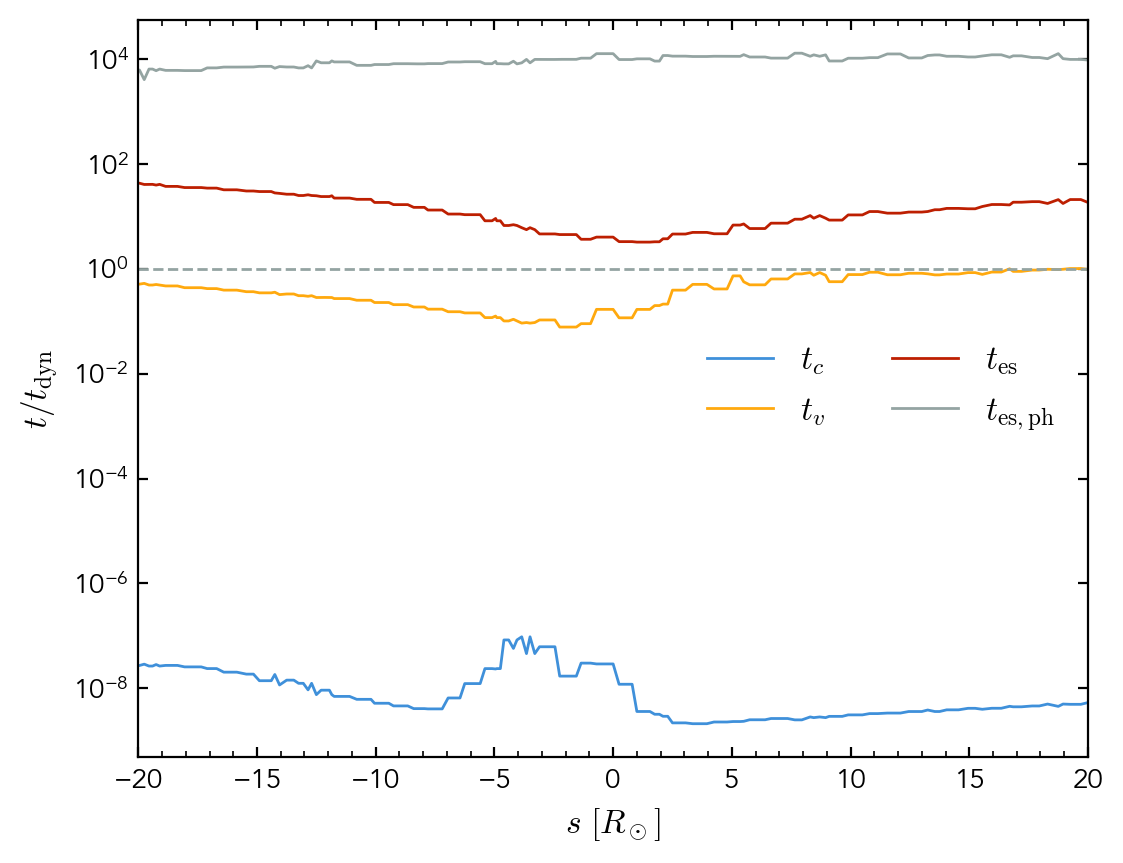

Single-cell column diagnostic: 1e5, snapshot 200
  cell, s<0: p=-0.685, R^2=0.987, N=105
  cell, s>0: p=-0.537, R^2=0.870, N=75
  column, s<0: p=-0.789, R^2=0.986, N=105
  column, s>0: p=-0.326, R^2=0.846, N=75


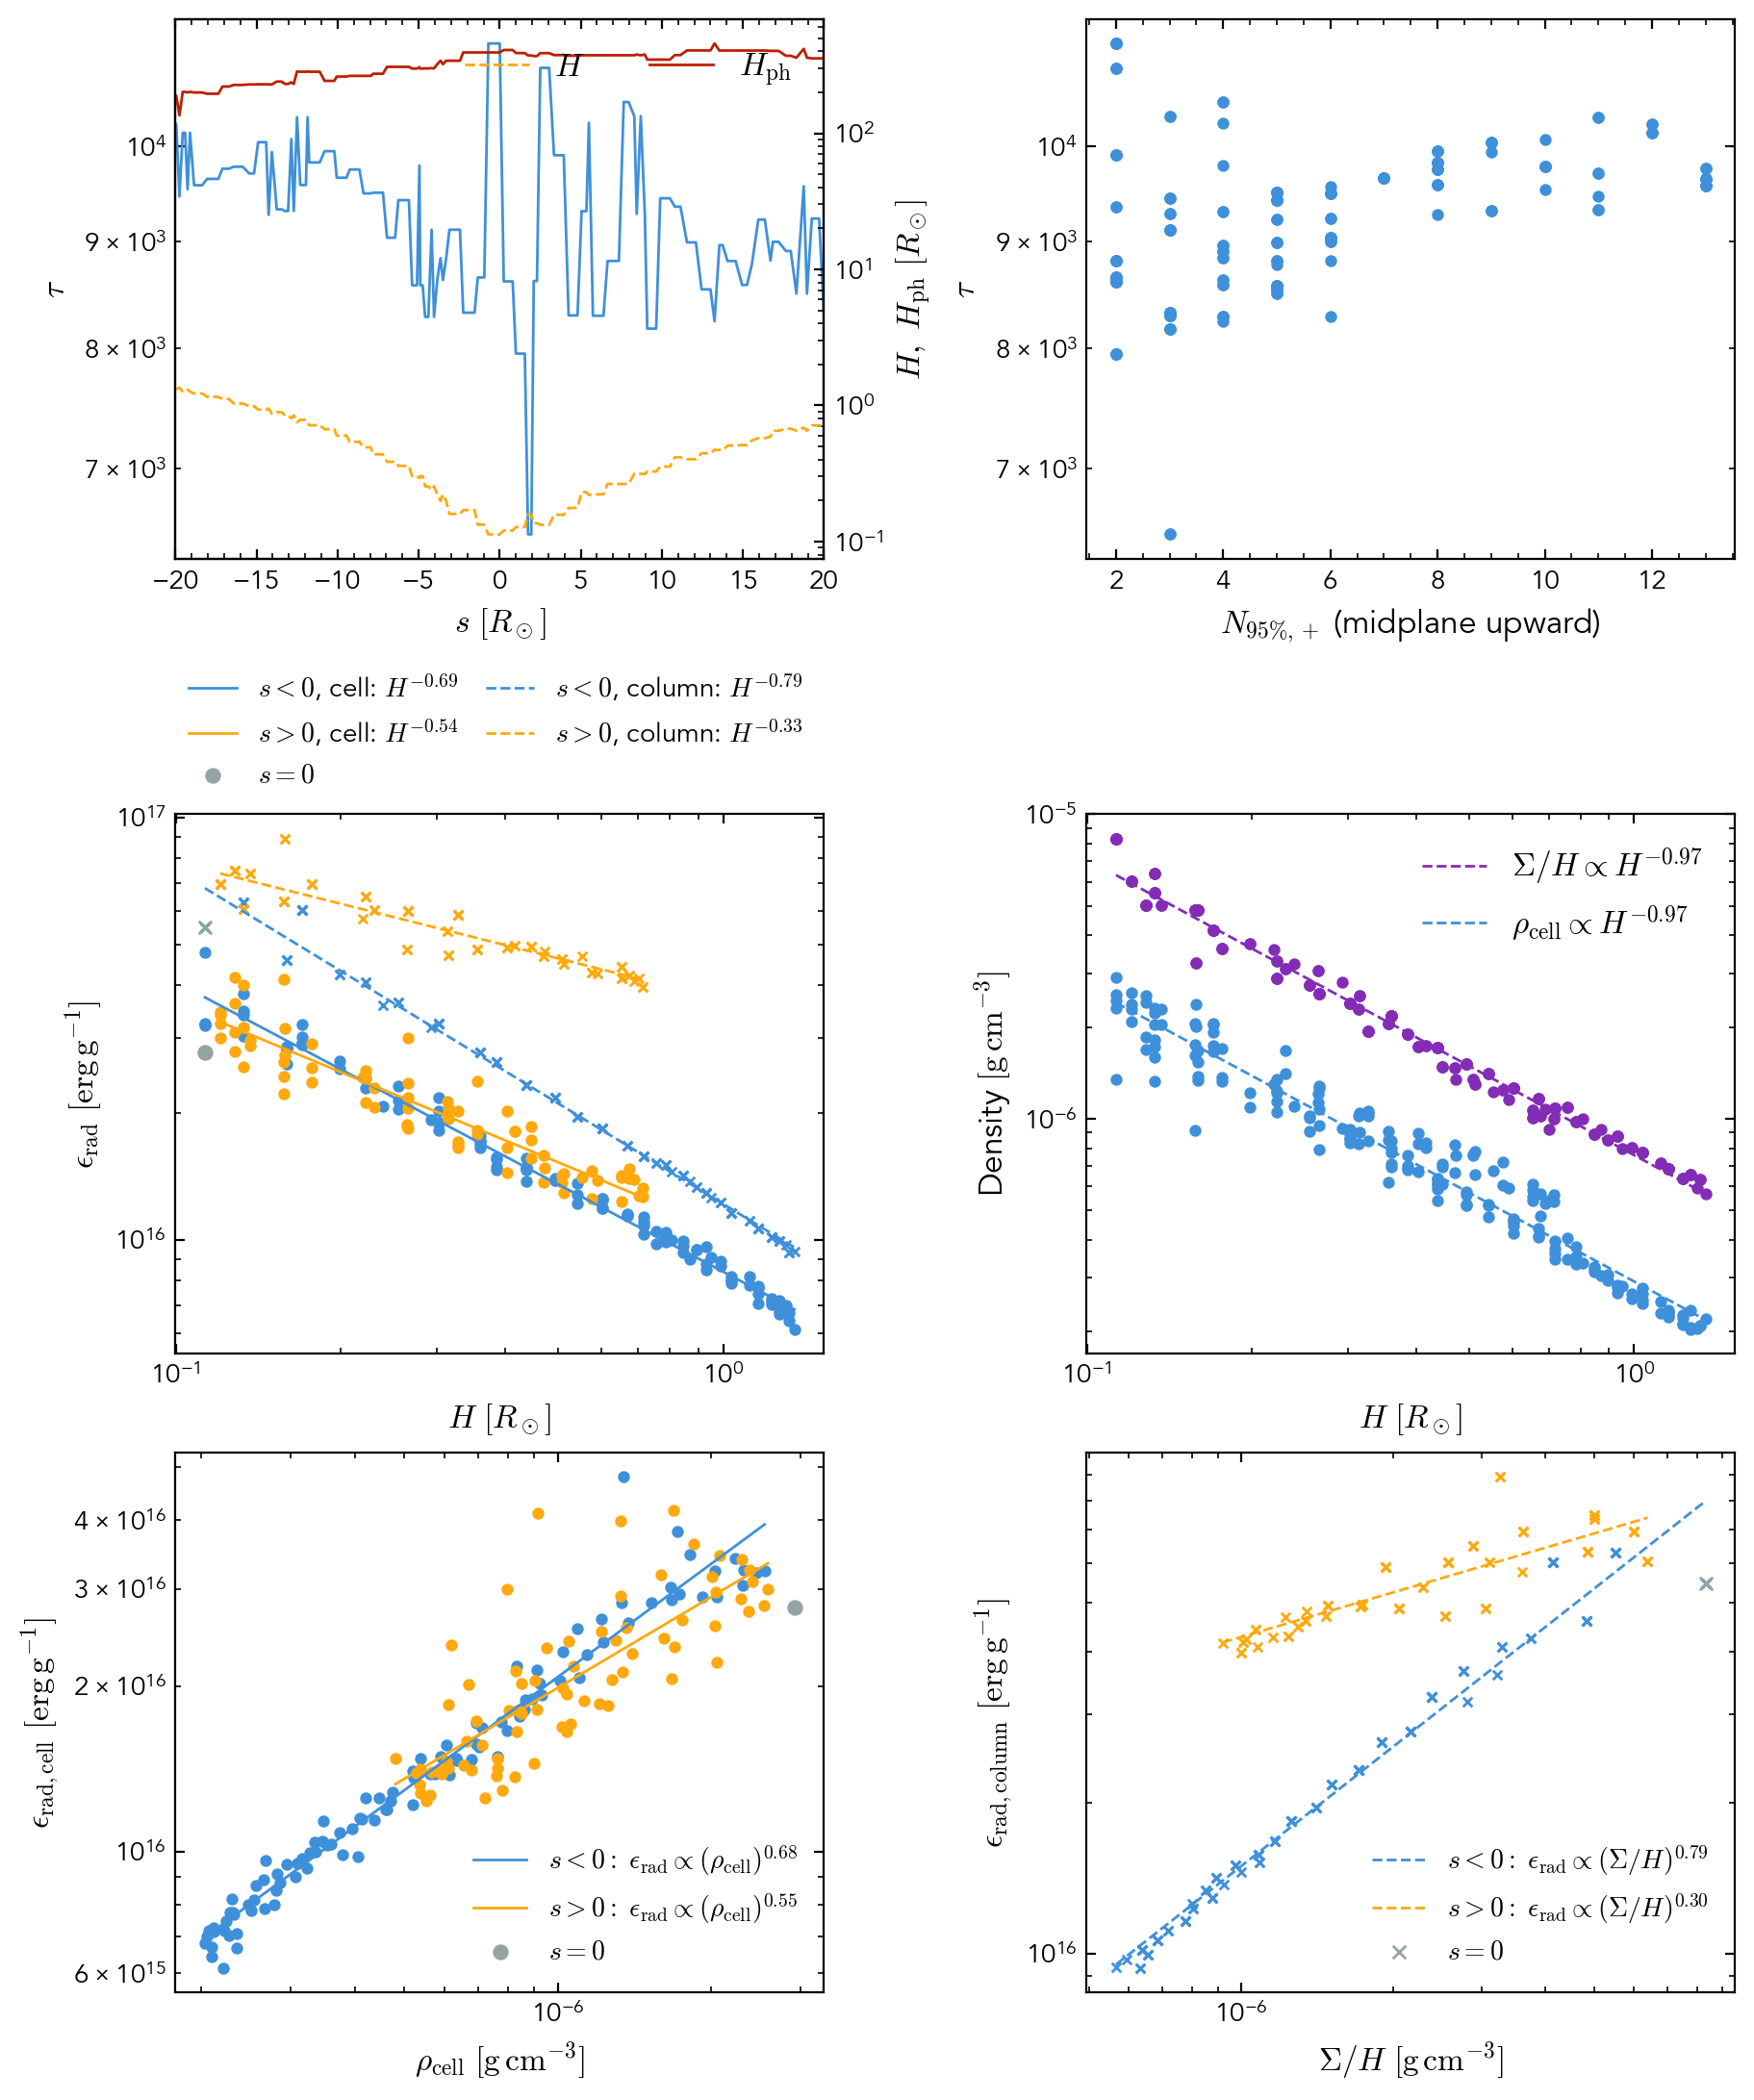

Streamline height: z range = -0.008352802280868788 Rsun to 0.018709961642610247 Rsun


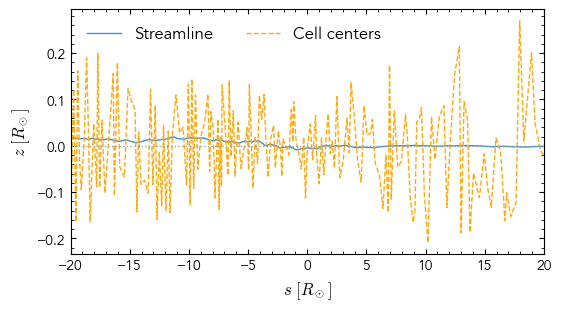

Integral of dissipation / speed over the 40 Rsun streamline: 19785241711.895157 erg/cm**3


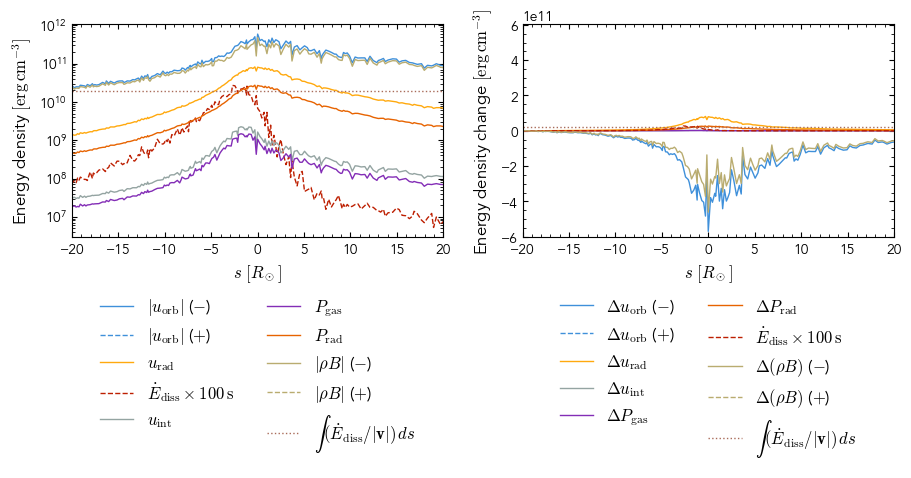

Single-cell specific energy ; integrated heating = 1.6368203847226658e+16 erg/g


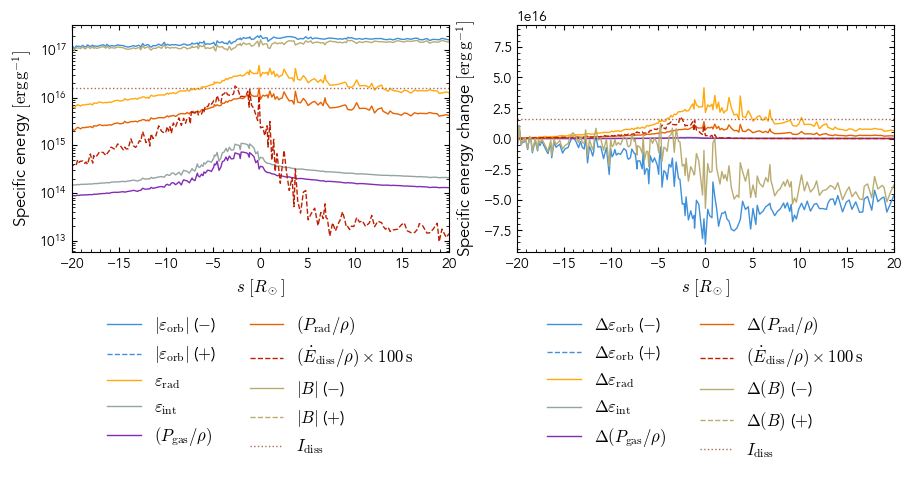

Perpendicular slices: radius = 82.99081131860575 Rsun ; rho > 2.915353099174869e-11 g/cm**3 (1e-05 times seed density); r dot r_c(s) > 0; harmonic core included; native cells per slice = 7454 to 12760
Slice-averaged specific energy ; integrated heating = 1.9409888517483532e+16 erg/g


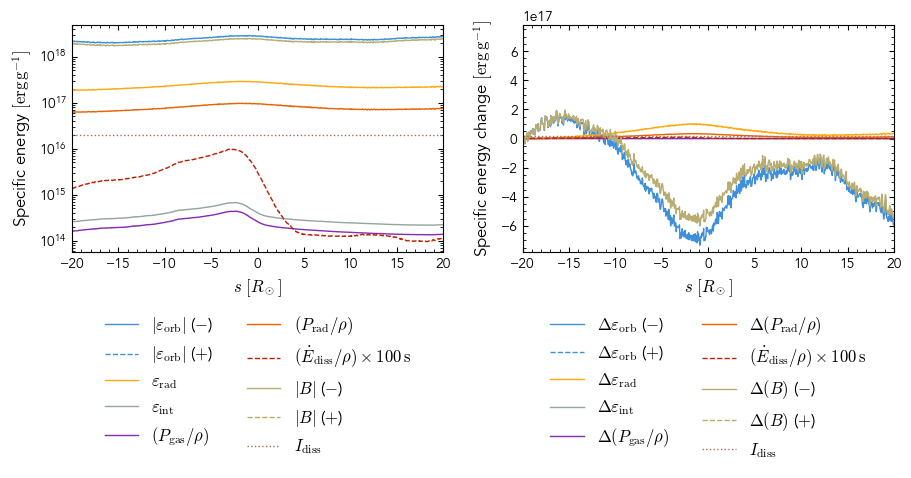

Slice-averaged energy density ; integrated heating = 7087386388.432494 erg/cm**3


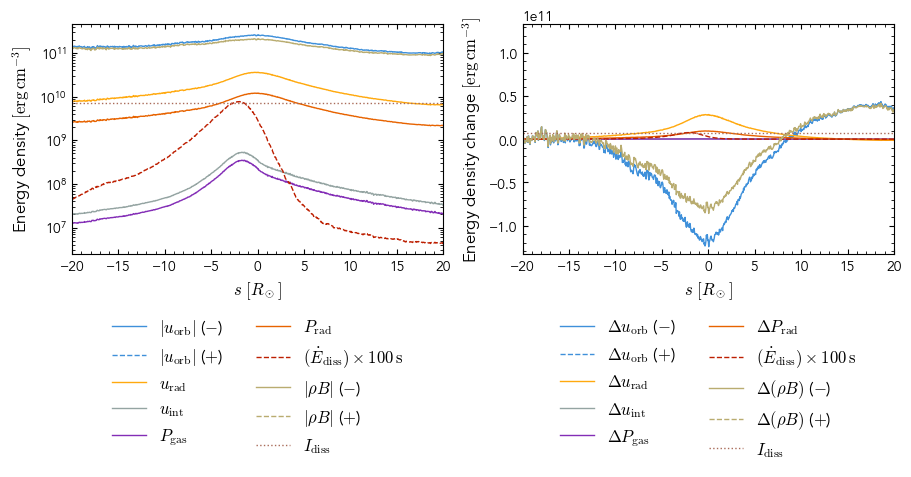

Mass-flux quadrature: 256 pixels per plane axis; max change on doubling resolution at five slices = 0.44% (relative to forward + |reverse|).
Net mass flux: upstream = 2.7913177036099532 Msun/yr ; downstream = 2.7076436891595375 Msun/yr ; range = 2.6606039177887406 Msun/yr to 2.819703233386063 Msun/yr
Mass-flux specific-energy / heating-rate convergence: 1.81%; area-integrated heating convergence: 0.48%.
Heating reference: integral(q dA ds) / upstream net Mdot; upstream net Mdot = 2.7913177036099532 Msun/yr ; max |reverse| / forward = 1.05%.
Net mass-flux-weighted specific energy ; integrated heating = 2.129975513953703e+16 erg/g


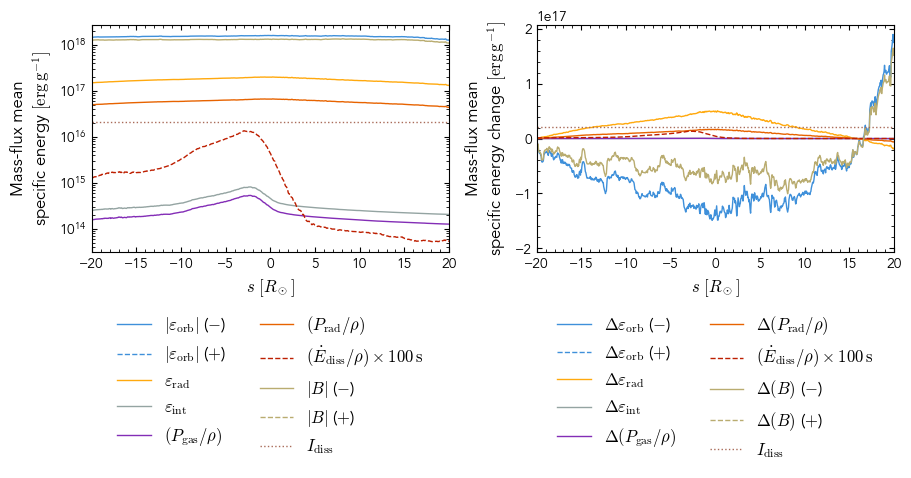

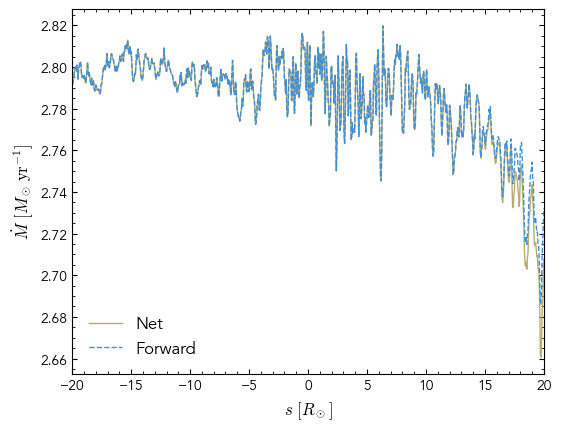

Snapshot 173, time = 5.890262161576989 day (0.701 t_fb)


Streamline seed cell: 28229003 at [ 2.58920714e+01 -8.91937442e+00 -1.19296671e-02] Rsun ; density = 1.8876279440393509e-07 g/cm**3 ; r_seed / r_p = 0.9899397729369024 dimensionless ; positive s follows the 3D velocity


Native particle visits: 183 from 801 tracing samples


Projected time scales along the flow: nearest grid columns; max XY offset = 0.5414727318146412 Rsun
Photospheres: full snapshot z bounds = [-9827.3084802  10128.78715629] Rsun ; 64 unique XY columns; found 128 of 128 observer surfaces; search steps per ray = (np.int64(135), np.int64(205))
Mean photosphere height range = (unyt_quantity(0.76034392, 'Rsun'), unyt_quantity(48.39541302, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(549.53965907, 'dimensionless'), unyt_quantity(770.30557993, 'dimensionless')) ; native-nearest trapezoids, no density cut


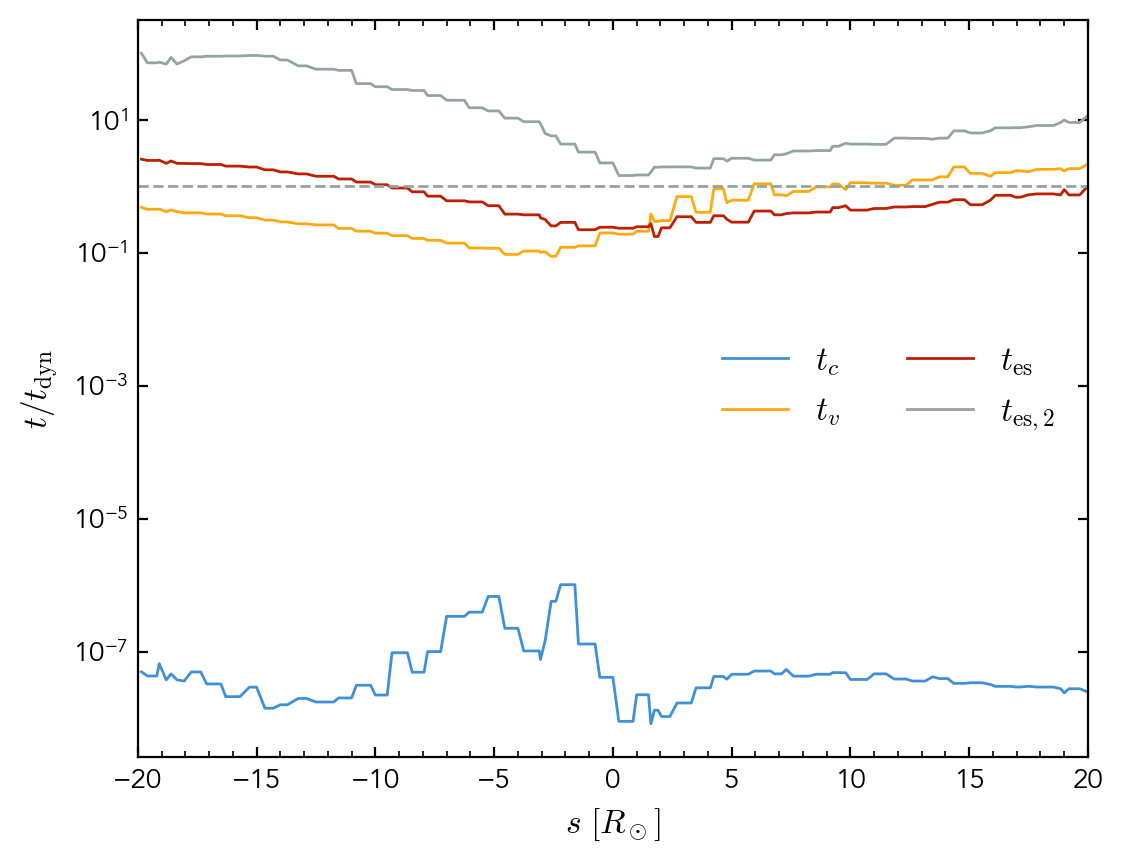

Single-cell column diagnostic: 1e5, snapshot 173
  cell, s<0: p=-0.708, R^2=0.953, N=89
  cell, s>0: p=-1.536, R^2=0.828, N=93
  column, s<0: p=-0.646, R^2=0.916, N=89
  column, s>0: p=-1.070, R^2=0.861, N=93


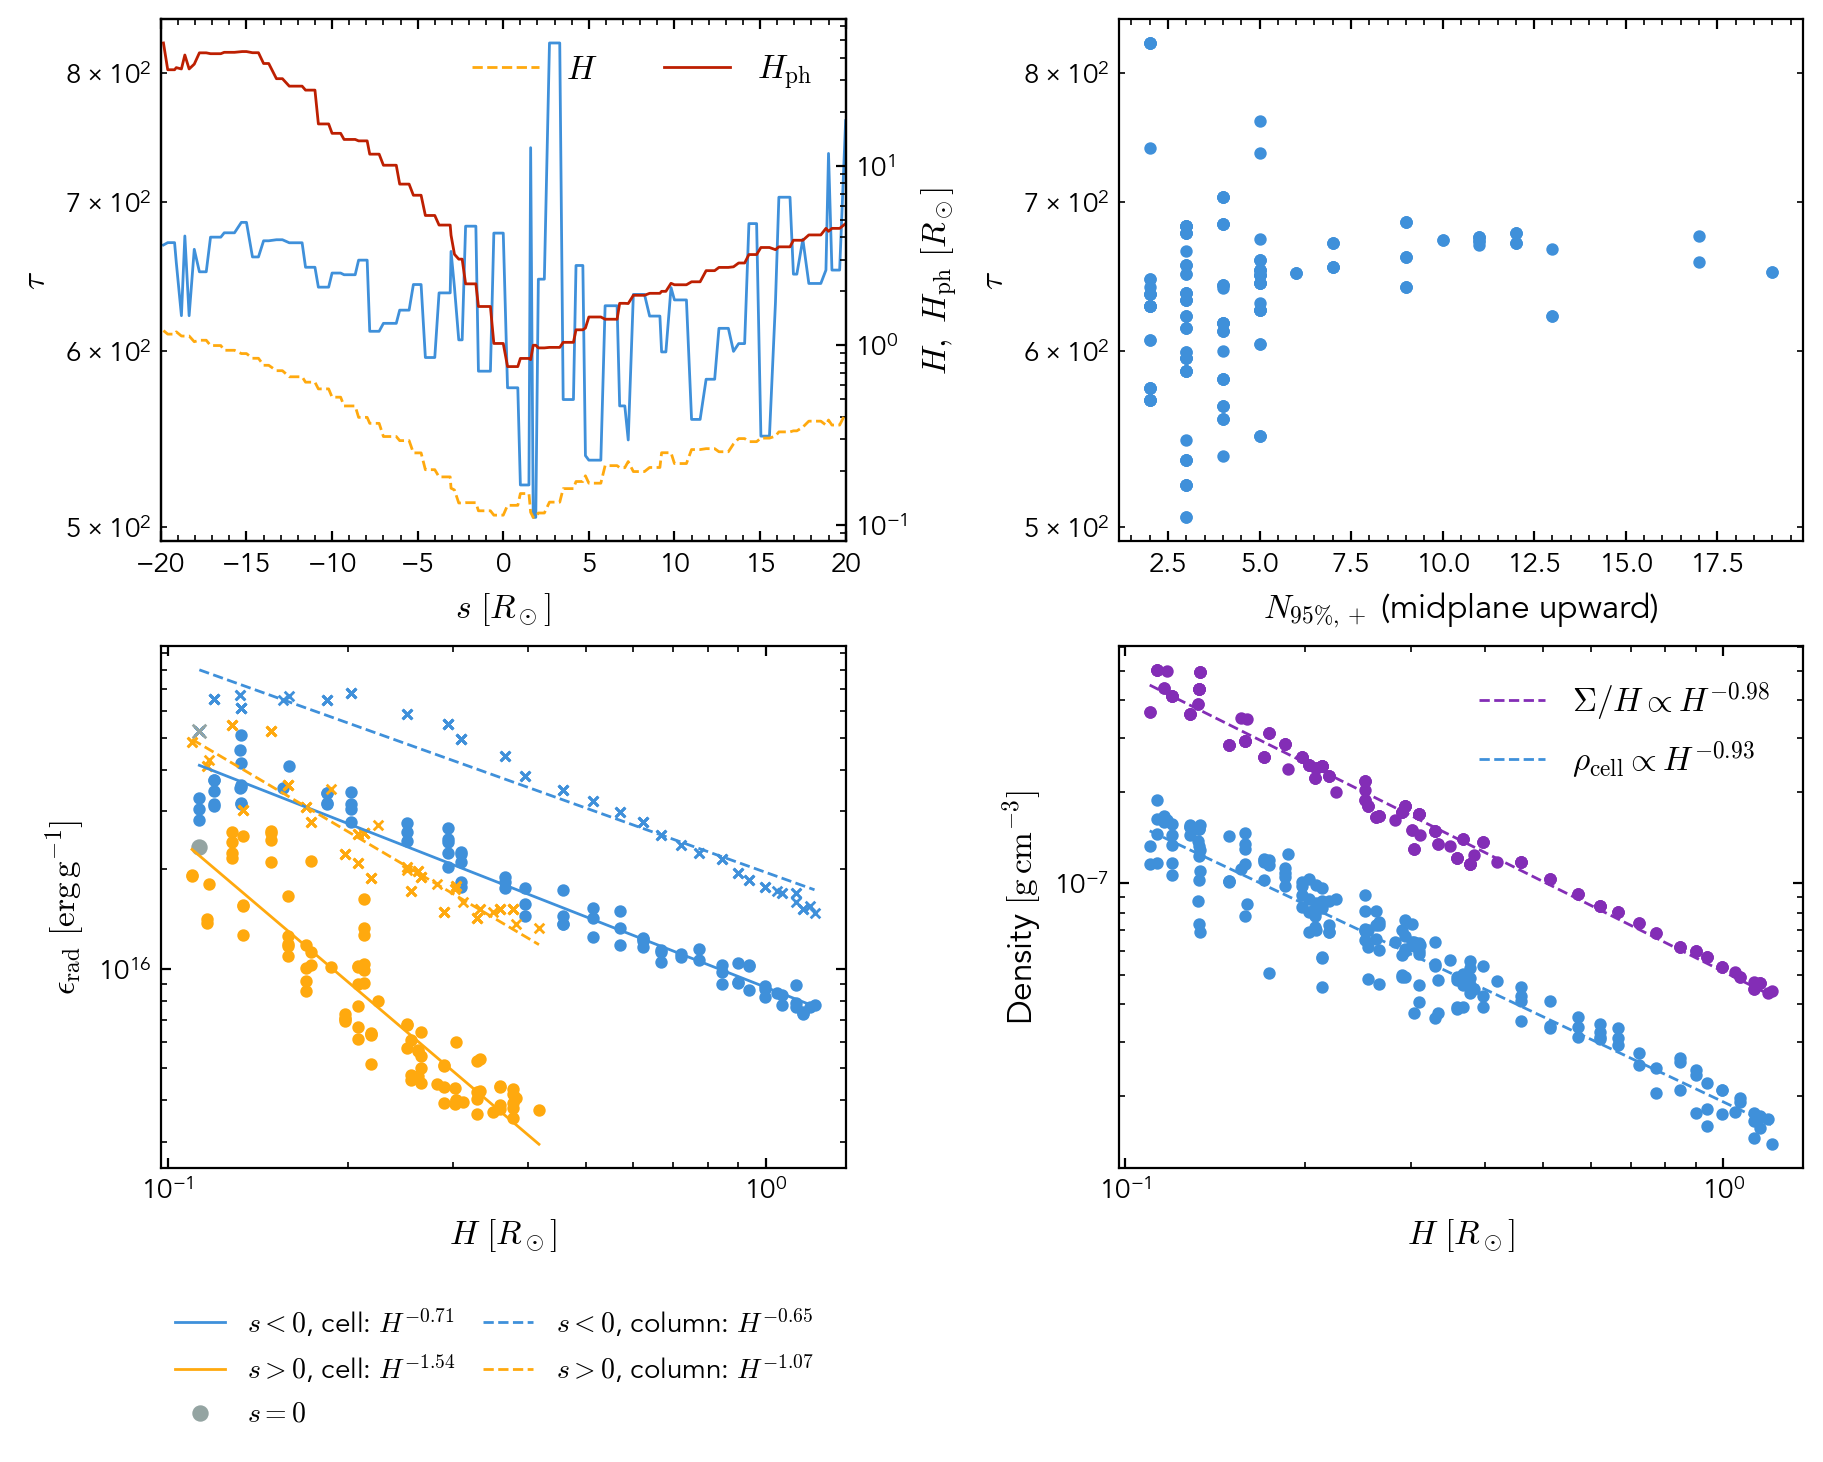

Streamline height: z range = -0.5519742017498463 Rsun to 0.0008381028207581588 Rsun


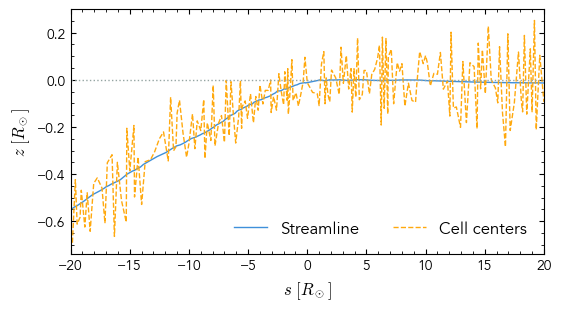

Integral of dissipation / speed over the 40 Rsun streamline: 1369724833.8476322 erg/cm**3


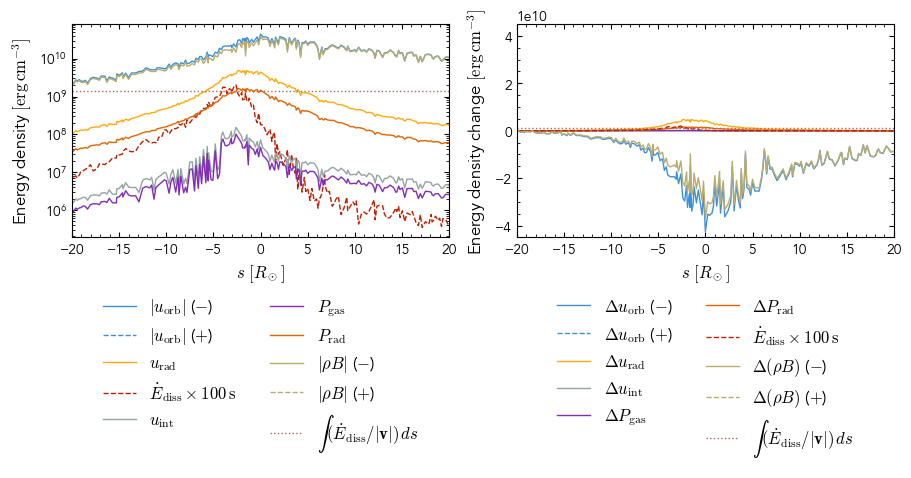

Single-cell specific energy ; integrated heating = 1.7847580397536392e+16 erg/g


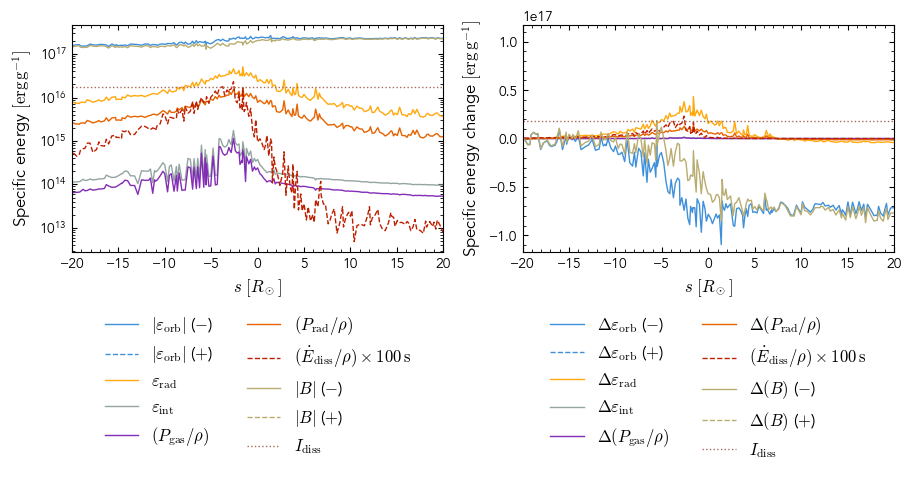

Perpendicular slices: radius = 82.99081131860575 Rsun ; rho > 1.8876279440393508e-12 g/cm**3 (1e-05 times seed density); r dot r_c(s) > 0; harmonic core included; native cells per slice = 3492 to 11023
Slice-averaged specific energy ; integrated heating = 5.815293805035625e+16 erg/g


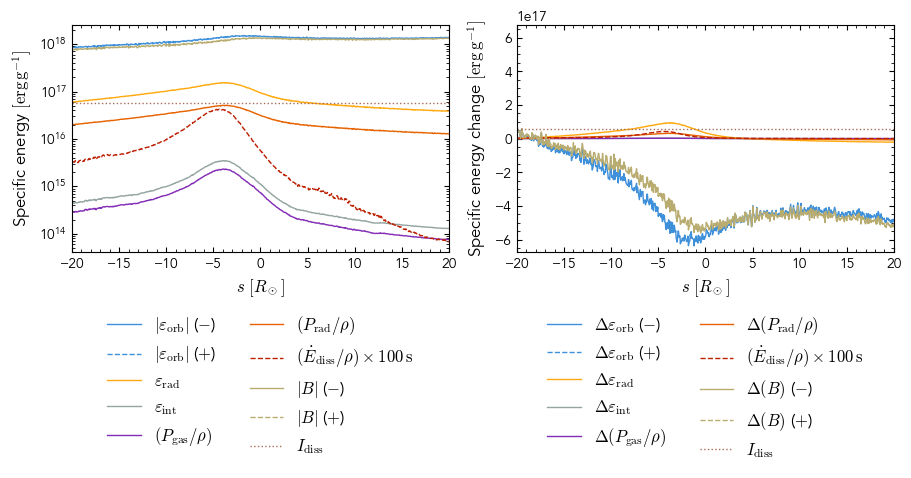

Slice-averaged energy density ; integrated heating = 651888592.4113768 erg/cm**3


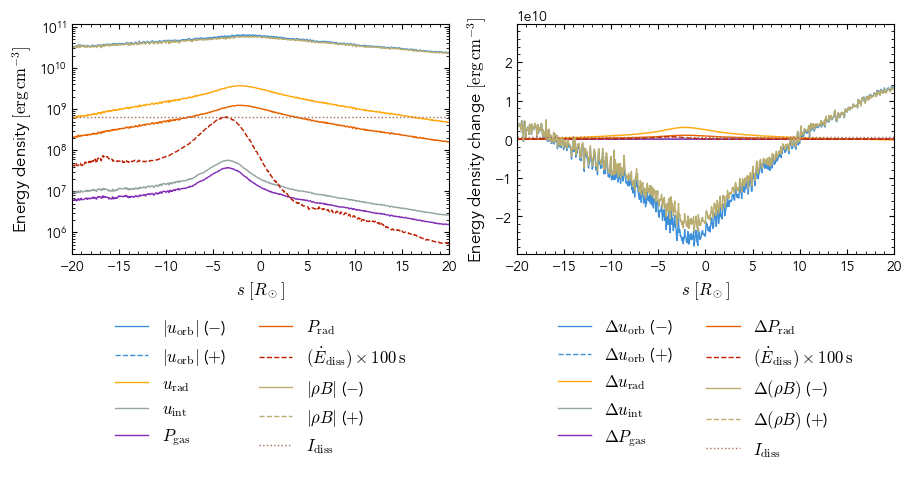

Mass-flux quadrature: 256 pixels per plane axis; max change on doubling resolution at five slices = 0.98% (relative to forward + |reverse|).
Net mass flux: upstream = 0.25033918483581086 Msun/yr ; downstream = 0.24862362289363388 Msun/yr ; range = 0.24552549579115274 Msun/yr to 0.2551038480095158 Msun/yr
Mass-flux specific-energy / heating-rate convergence: 1.70%; area-integrated heating convergence: 0.84%.
Heating reference: integral(q dA ds) / upstream net Mdot; upstream net Mdot = 0.25033918483581086 Msun/yr ; max |reverse| / forward = 0.01%.
Net mass-flux-weighted specific energy ; integrated heating = 5.383234928029775e+16 erg/g


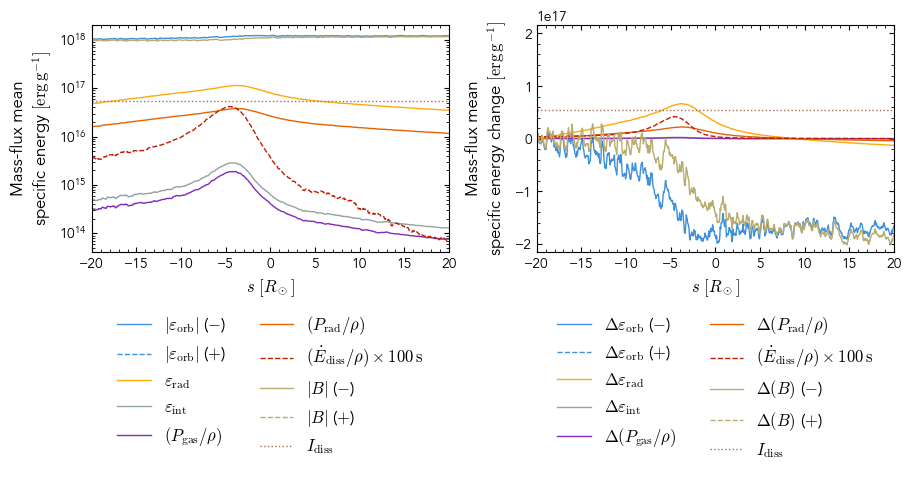

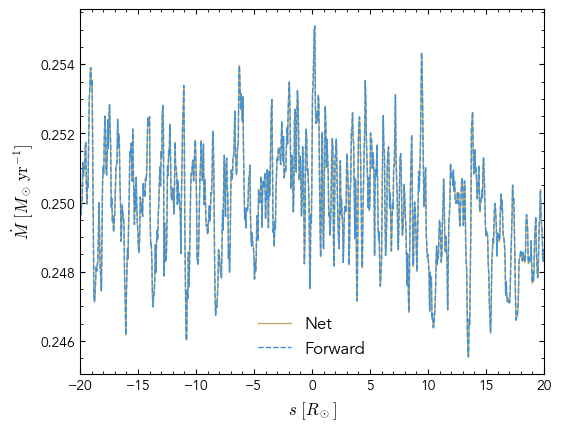

In [12]:
RUN = "1e5"
RSTAR, MSTAR, MBH = (
    0.47 * richio.units.lscale,
    0.5 * richio.units.mscale,
    1e5 * richio.units.mscale,
)
r_p = float((RSTAR * (MBH / MSTAR) ** (1 / 3)).in_units("code_length"))

XY = 100

TFBS = [0.7, 1.0]
SNAPSHOTS = dev.SNAPSHOT_TFB(RUN, TFBS)

t_dyn = np.sqrt(RSTAR**3 / (u.G * MSTAR))
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
print(
    "Run:",
    RUN,
    "\nStellar dynamical time:",
    t_dyn.in_units("s"),
    "\nFallback time:",
    t_fb.in_units("day"),
)

for SNAPDIR in list(reversed(SNAPSHOTS))[:SNAPSHOT_LIMIT]:
    snapnum = int(os.path.splitext(os.path.basename(SNAPDIR))[0].rsplit("_", 1)[1])
    snap = richio.load(SNAPDIR)
    time_in_tfb = np.asarray((snap.time / t_fb).to_value("dimensionless")).item()
    print(
        f"Snapshot {snapnum}, time = {snap.time.in_units('day')} "
        f"({time_in_tfb:.3f} t_fb)"
    )

    native = load_native_fields(snap)
    seed_cell = get_max_density_cell(native, r_p)
    streamline = get_streamline(native, seed_cell)

    # Calculate, plot, then release each diagnostic group before starting the next.
    tree = cKDTree(
        np.column_stack([axis.to_value("Rsun") for axis in native["position"]])
    )
    columns = compute_column_profiles(snap, native, streamline, r_p, XY, tree)
    plot_timescales(streamline, columns, t_dyn)
    plot_column_diagnostics(streamline, columns, RUN, snapnum)
    del columns, tree
    plot_streamline_height(streamline)

    energy_fields = compute_energy_fields(native, MBH, r_p)
    single = compute_single_cell_profiles(native, streamline, energy_fields)
    plot_single_cell_energy_density(streamline, single)
    plot_single_cell_specific_energy(streamline, single)
    del single

    slices = compute_slice_profiles(native, streamline, energy_fields, r_p, seed_cell)
    plot_slice_specific_energy(streamline, slices)
    plot_slice_energy_density(streamline, slices)
    del slices

    flux = compute_mass_flux_profiles(native, streamline, energy_fields, r_p, seed_cell)
    plot_flux_specific_energy(streamline, flux)
    plot_mass_flux(streamline, flux)
    del flux, energy_fields, streamline, native, snap

## $10^4$


Run: 1e4 
Stellar dynamical time: 730.4628659211085 s 
Fallback time: 2.656037932057755 day
Snapshot 151, time = [5.77629162] day (2.175 t_fb)


Streamline seed cell: 45467225 at [ 1.23072202e+01 -2.92261252e+00 -9.70176407e-03] Rsun ; density = 0.00026443568505437335 g/cm**3 ; r_seed / r_p = 0.9851386630838429 dimensionless ; positive s follows the 3D velocity


Native particle visits: 452 from 801 tracing samples


Projected time scales along the flow: nearest grid columns; max XY offset = 0.1610887999590061 Rsun
Photospheres: full snapshot z bounds = [-18636.51624661  16107.06366542] Rsun ; 211 unique XY columns; found 422 of 422 observer surfaces; search steps per ray = (np.int64(121), np.int64(134))
Mean photosphere height range = (unyt_quantity(1706.28433407, 'Rsun'), unyt_quantity(1746.40096242, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(405368.57460374, 'dimensionless'), unyt_quantity(693480.88976929, 'dimensionless')) ; native-nearest trapezoids, no density cut


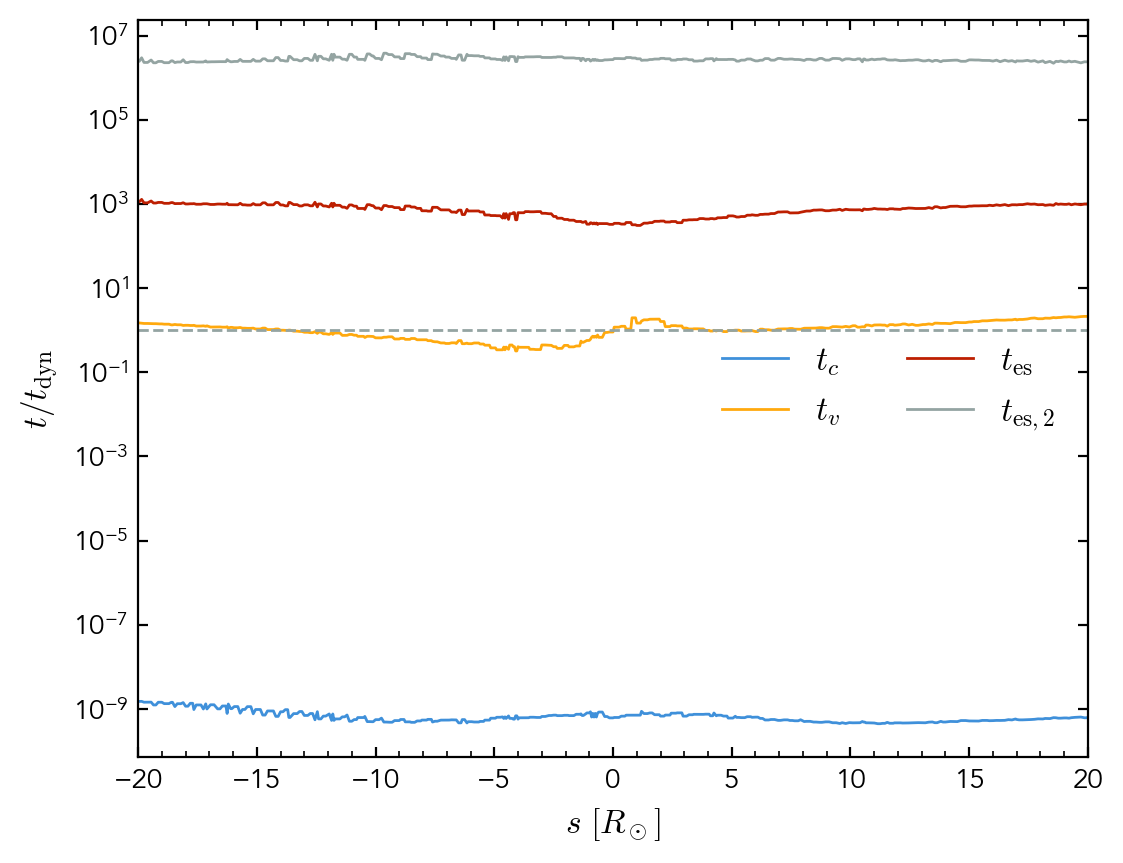

Single-cell column diagnostic: 1e4, snapshot 151


  cell, s<0: p=-2.271, R^2=0.829, N=258
  cell, s>0: p=-0.993, R^2=0.927, N=193
  column, s<0: p=-1.301, R^2=0.924, N=258
  column, s>0: p=-0.619, R^2=0.783, N=193


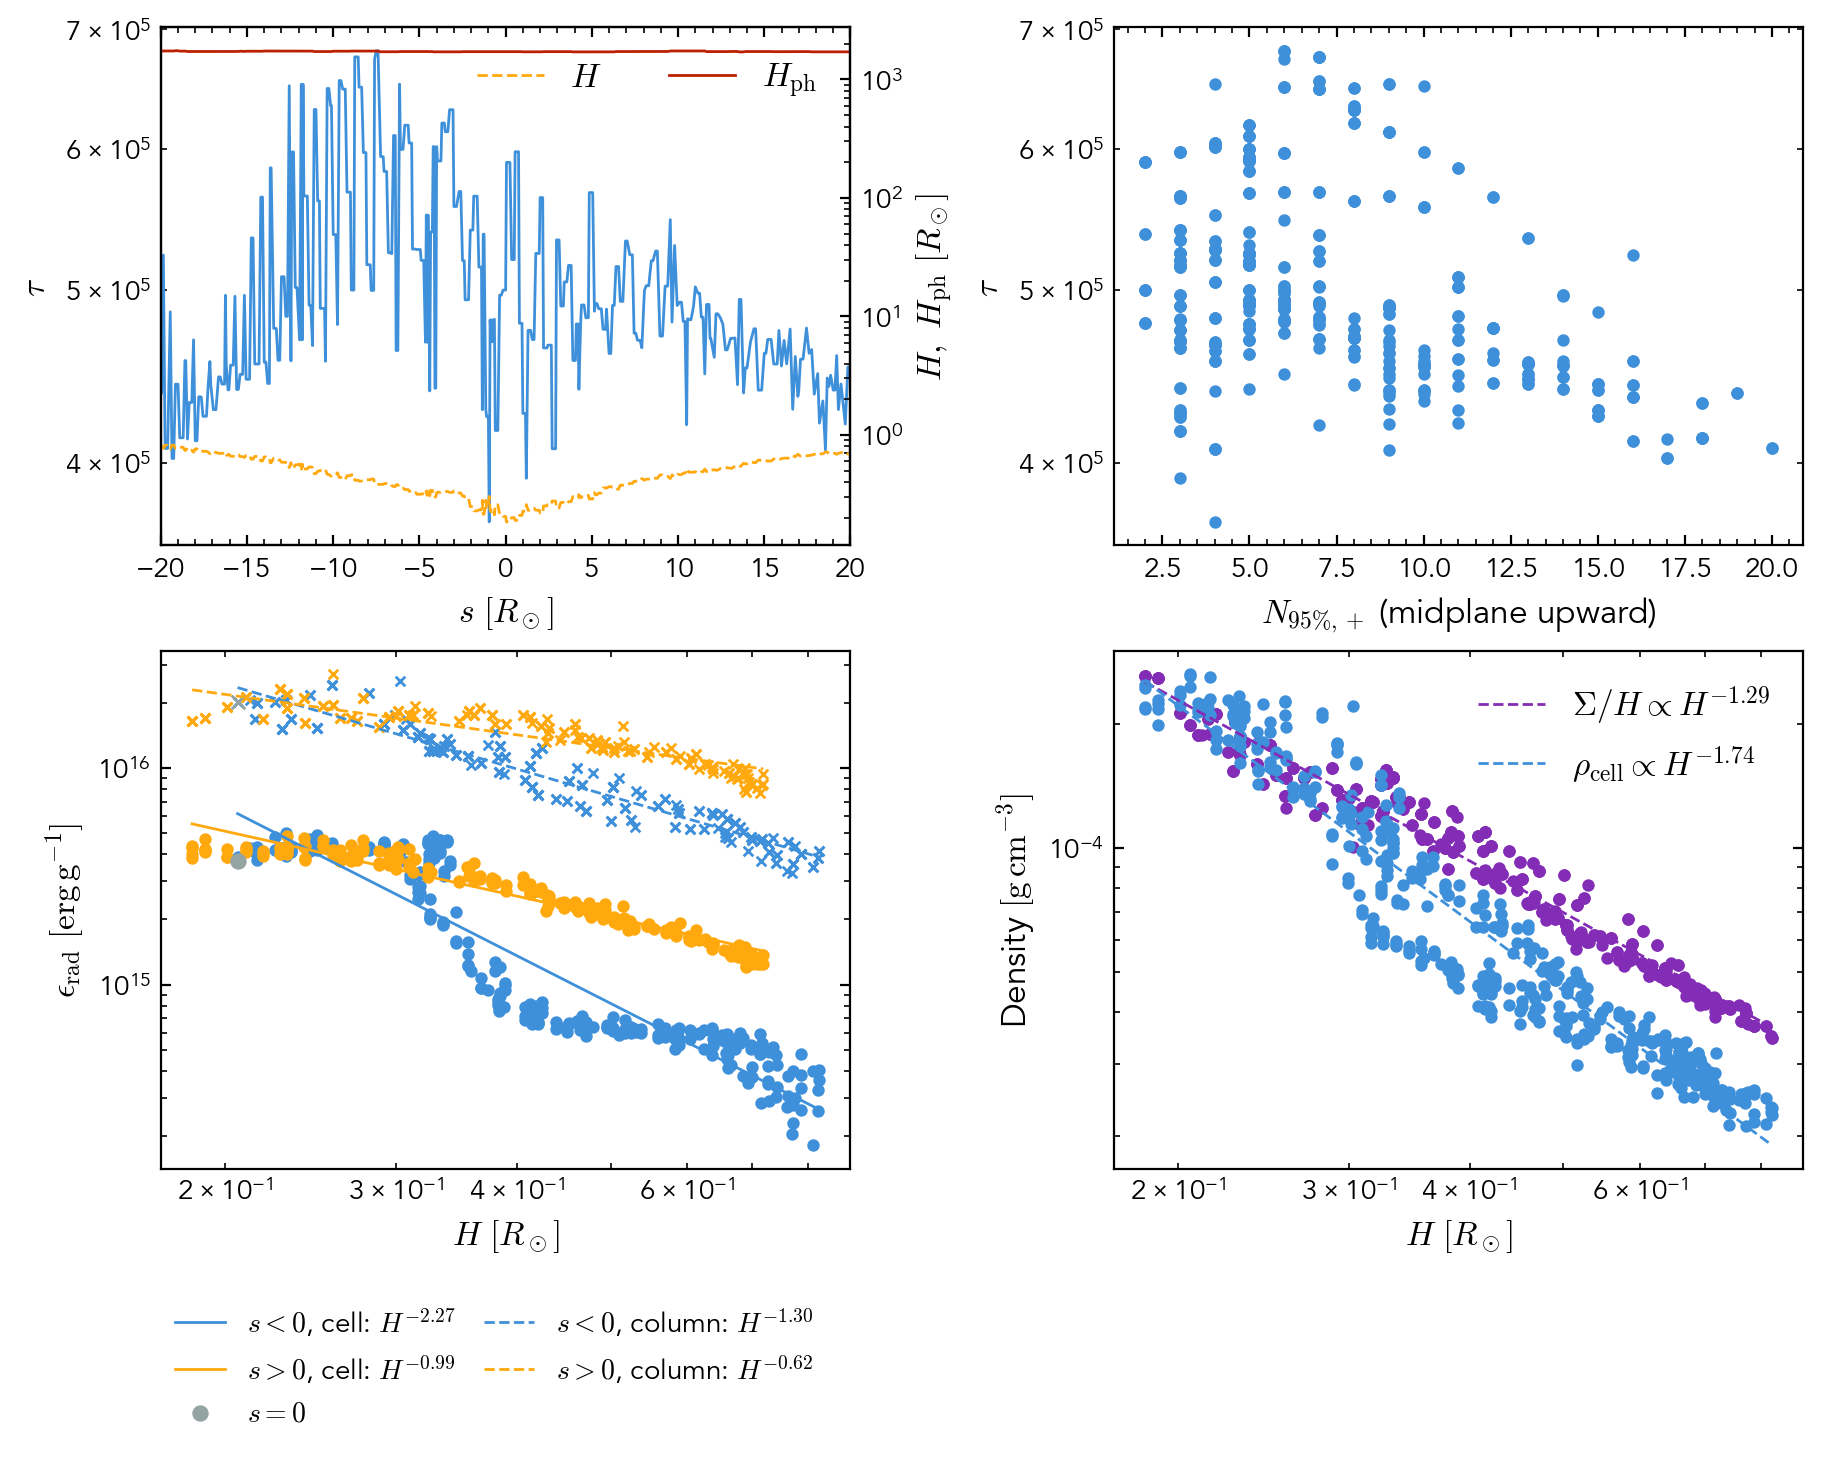

Streamline height: z range = -0.10065088597382878 Rsun to 0.08051173556334103 Rsun


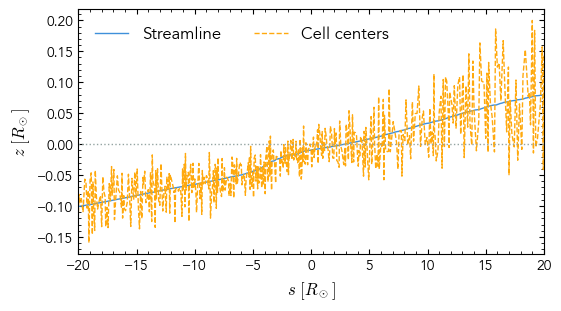

Integral of dissipation / speed over the 40 Rsun streamline: 151252451243.4295 erg/cm**3


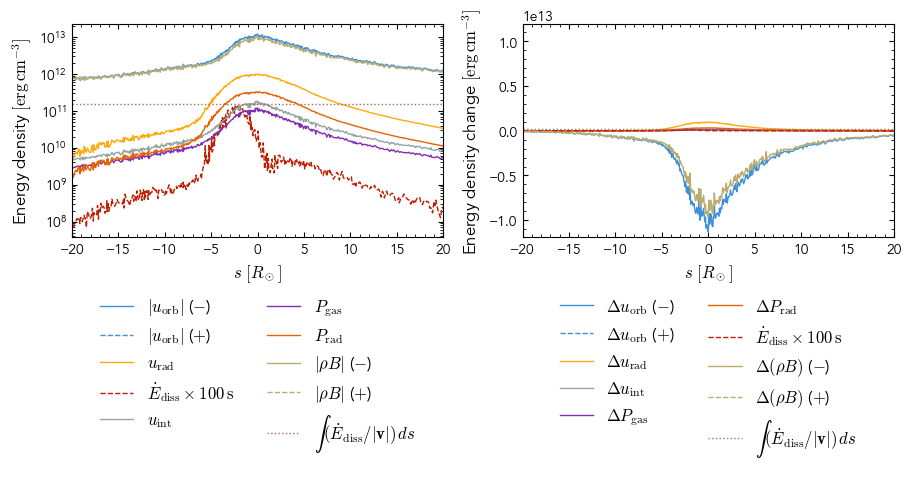

Single-cell specific energy ; integrated heating = 1208927340128676.5 erg/g


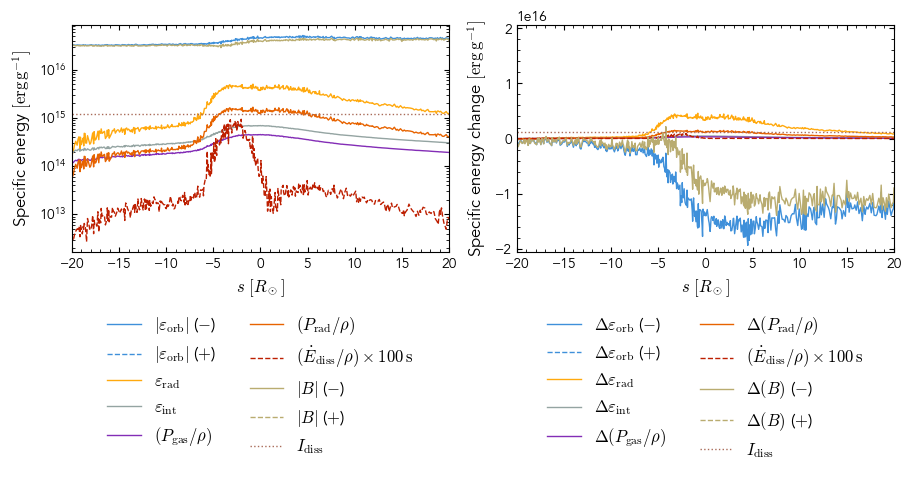

Perpendicular slices: radius = 38.52092231089054 Rsun ; rho > 2.644356850543734e-09 g/cm**3 (1e-05 times seed density); r dot r_c(s) > 0; harmonic core included; native cells per slice = 41014 to 54109
Slice-averaged specific energy ; integrated heating = 2.656515114271746e+16 erg/g


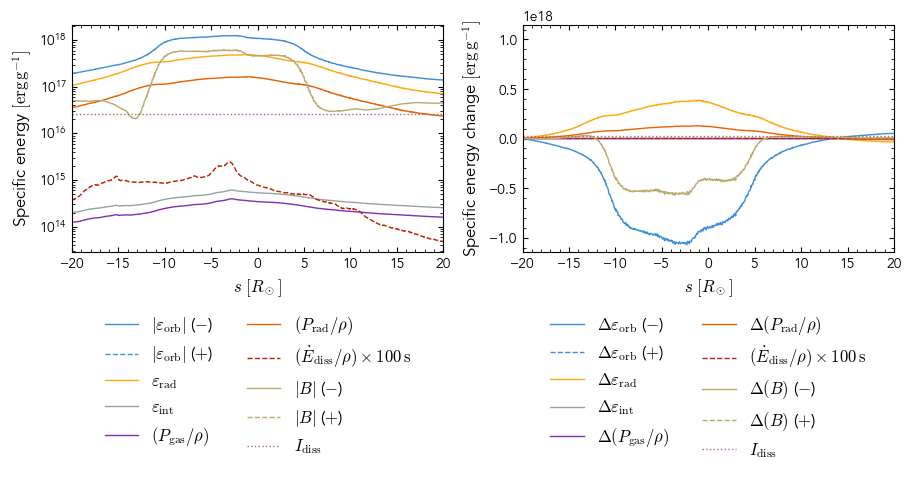

Slice-averaged energy density ; integrated heating = 64113761072.17207 erg/cm**3


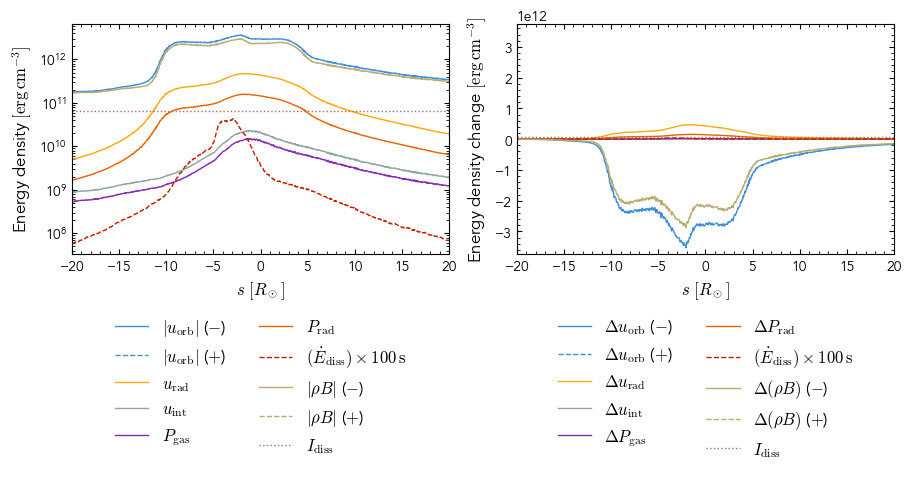

Mass-flux quadrature: 256 pixels per plane axis; max change on doubling resolution at five slices = 0.39% (relative to forward + |reverse|).
Net mass flux: upstream = 11.830112380603307 Msun/yr ; downstream = 11.67599354812995 Msun/yr ; range = 11.609230462350139 Msun/yr to 13.025233557681982 Msun/yr
Mass-flux specific-energy / heating-rate convergence: 1.70%; area-integrated heating convergence: 1.57%.
Heating reference: integral(q dA ds) / upstream net Mdot; upstream net Mdot = 11.830112380603307 Msun/yr ; max |reverse| / forward = 1.80%.
Net mass-flux-weighted specific energy ; integrated heating = 1.3925161190139608e+16 erg/g


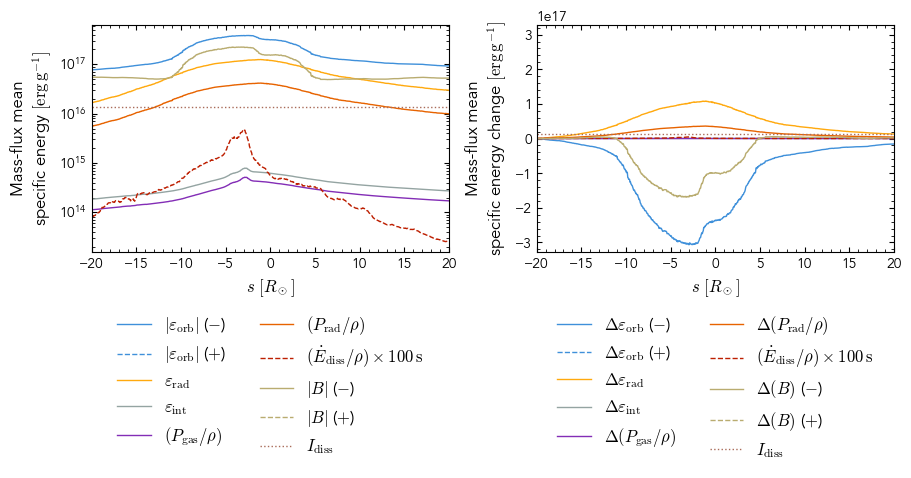

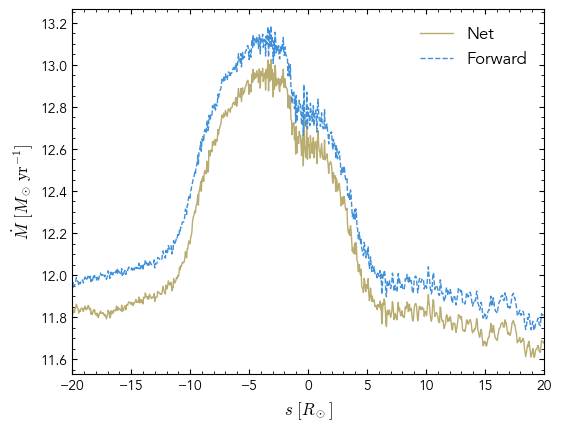

Snapshot 108, time = [3.96398148] day (1.492 t_fb)


Streamline seed cell: 34963870 at [ 1.15882792e+01 -3.32631488e+00  6.67555505e-04] Rsun ; density = 0.000261305904144604 g/cm**3 ; r_seed / r_p = 0.9389359298506142 dimensionless ; positive s follows the 3D velocity


Native particle visits: 415 from 801 tracing samples


Projected time scales along the flow: nearest grid columns; max XY offset = 0.1525843539828382 Rsun
Photospheres: full snapshot z bounds = [-8290.84467883  7424.00634756] Rsun ; 210 unique XY columns; found 420 of 420 observer surfaces; search steps per ray = (np.int64(157), np.int64(206))
Mean photosphere height range = (unyt_quantity(234.76086981, 'Rsun'), unyt_quantity(307.33190184, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(483922.69269018, 'dimensionless'), unyt_quantity(5023353.45401547, 'dimensionless')) ; native-nearest trapezoids, no density cut


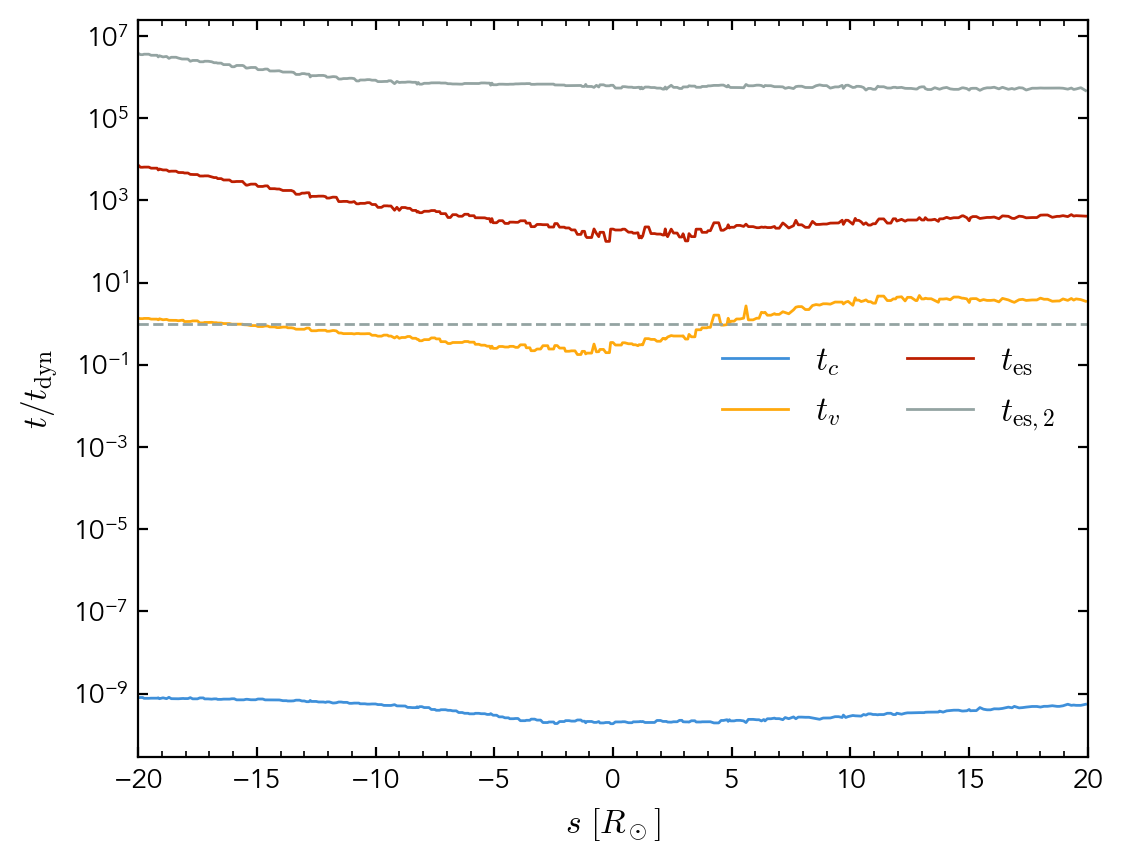

Single-cell column diagnostic: 1e4, snapshot 108
  cell, s<0: p=-1.558, R^2=0.988, N=240
  cell, s>0: p=-0.506, R^2=0.879, N=174
  column, s<0: p=-1.777, R^2=0.984, N=240
  column, s>0: p=-0.197, R^2=0.481, N=174


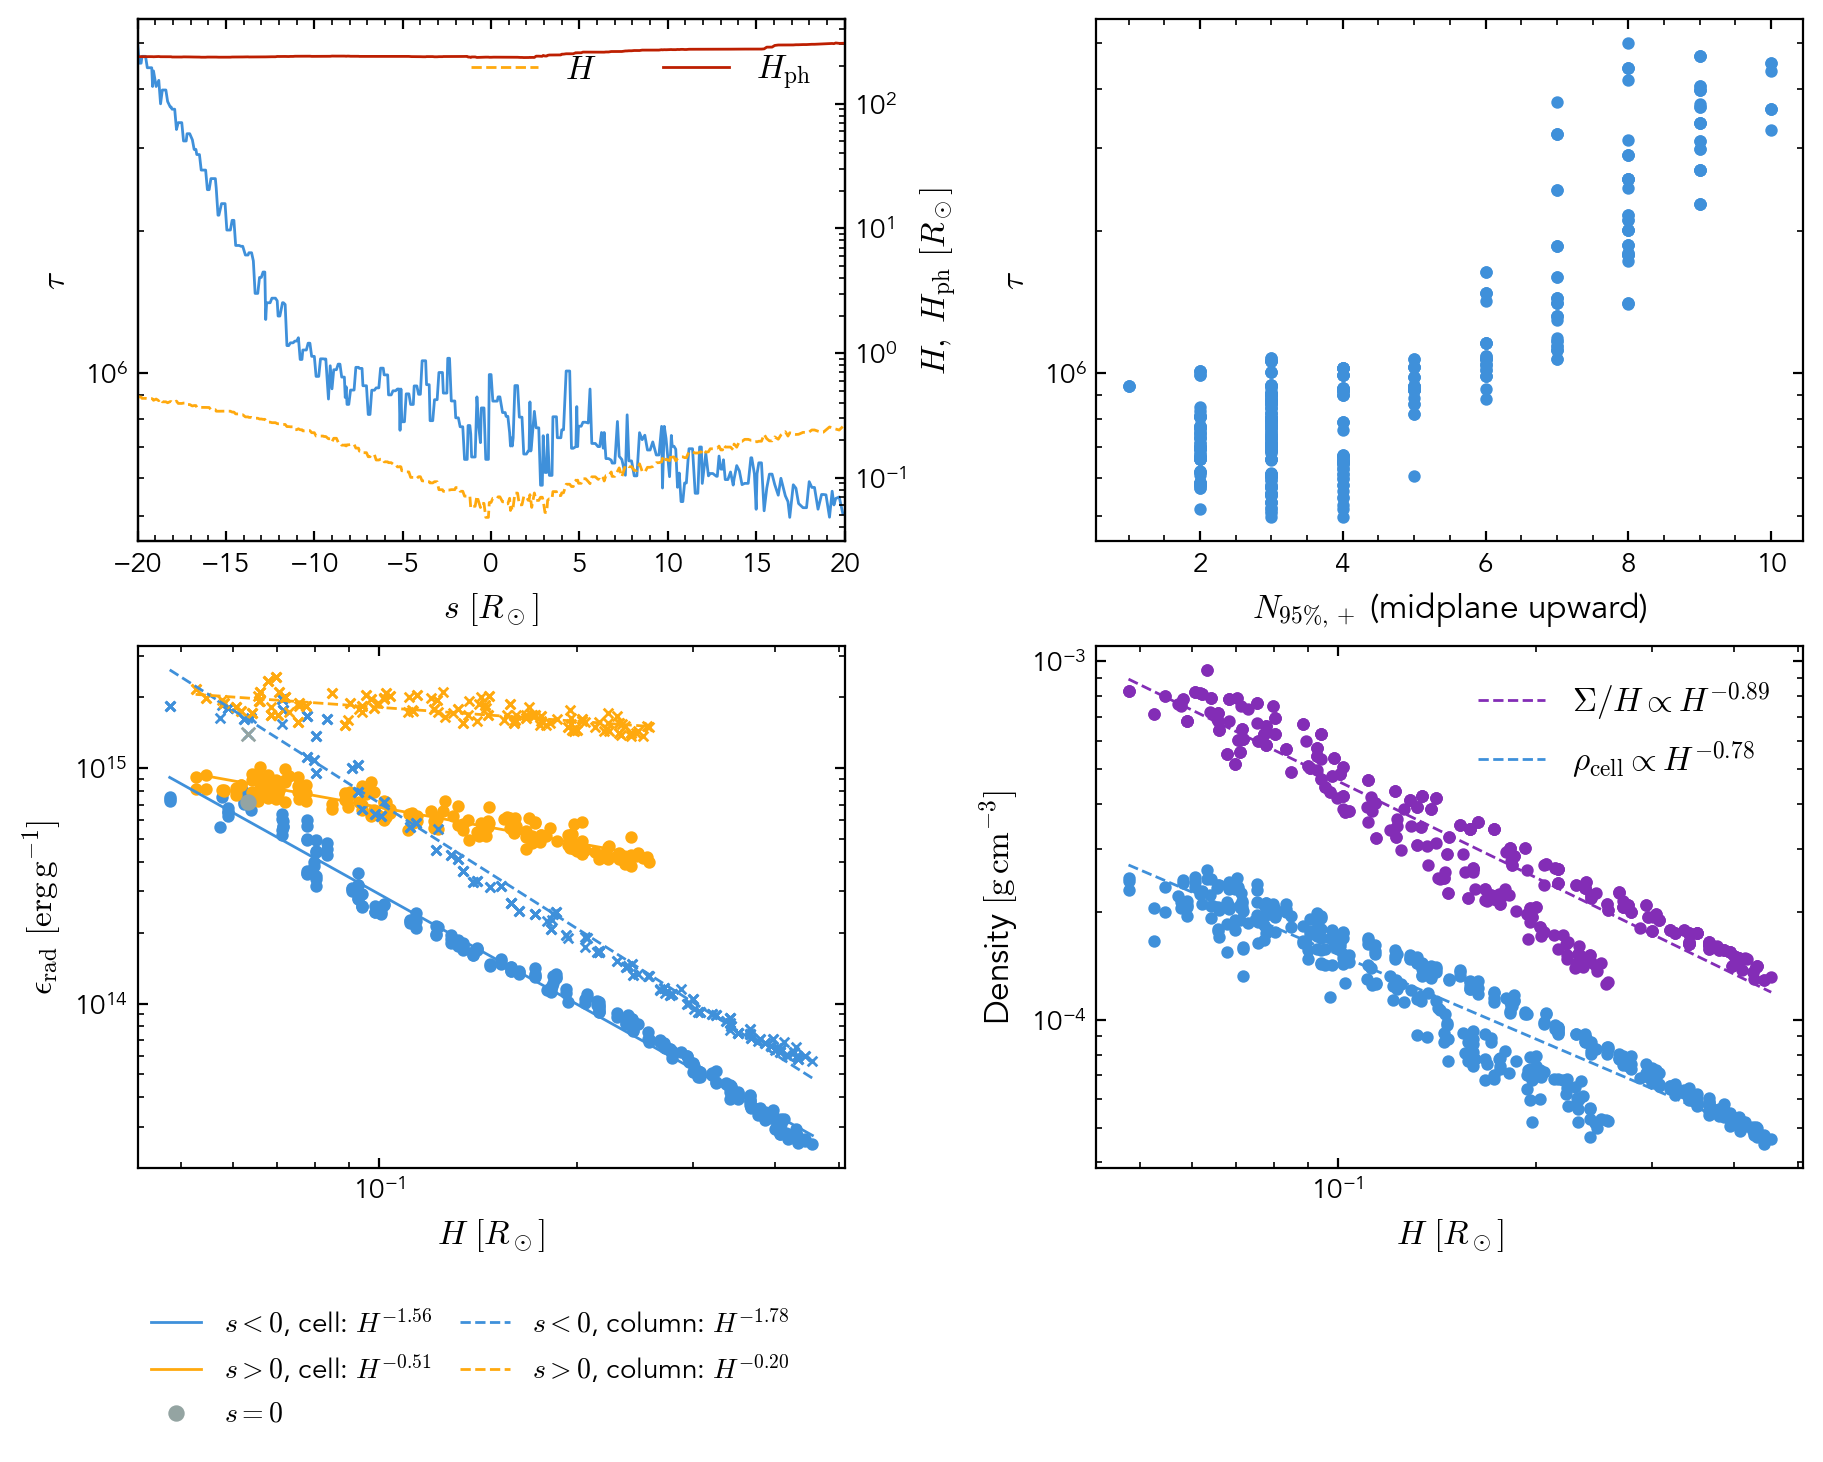

Streamline height: z range = -0.0018474711242951933 Rsun to 0.03959681101166788 Rsun


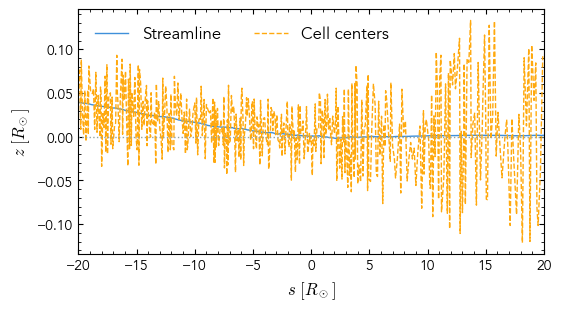

Integral of dissipation / speed over the 40 Rsun streamline: 74830876713.8987 erg/cm**3


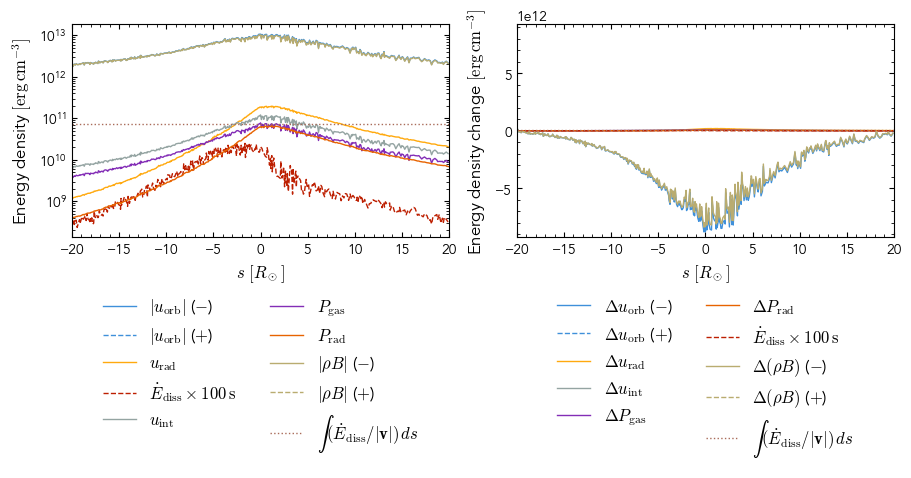

Single-cell specific energy ; integrated heating = 502526400634090.94 erg/g


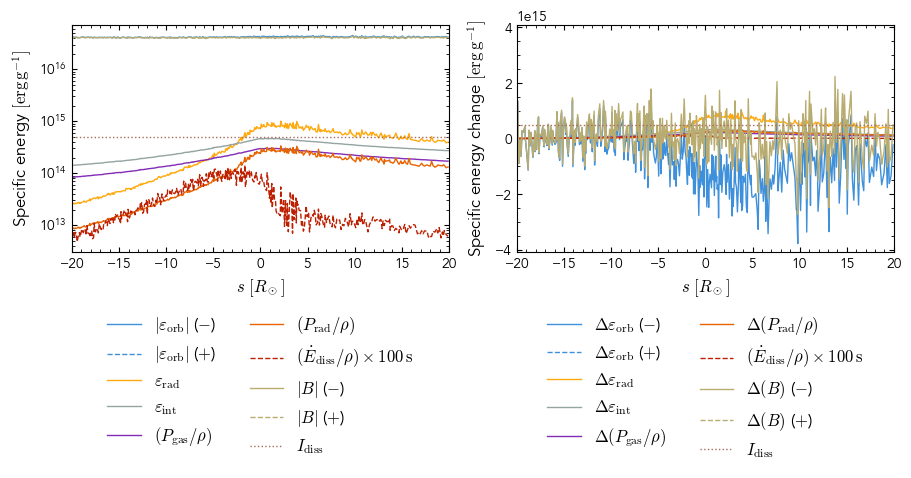

Perpendicular slices: radius = 38.52092231089054 Rsun ; rho > 2.6130590414460403e-09 g/cm**3 (1e-05 times seed density); r dot r_c(s) > 0; harmonic core included; native cells per slice = 8538 to 22889
Slice-averaged specific energy ; integrated heating = 3184487615756253.0 erg/g


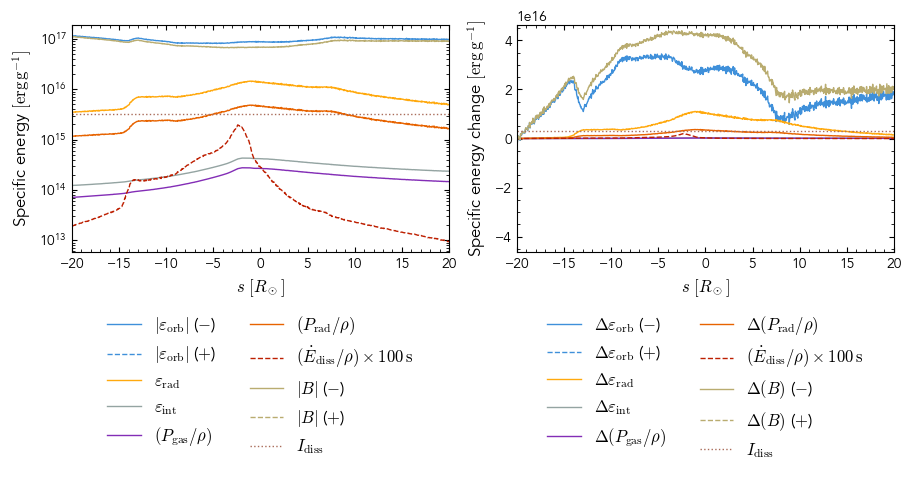

Slice-averaged energy density ; integrated heating = 54330663193.23364 erg/cm**3


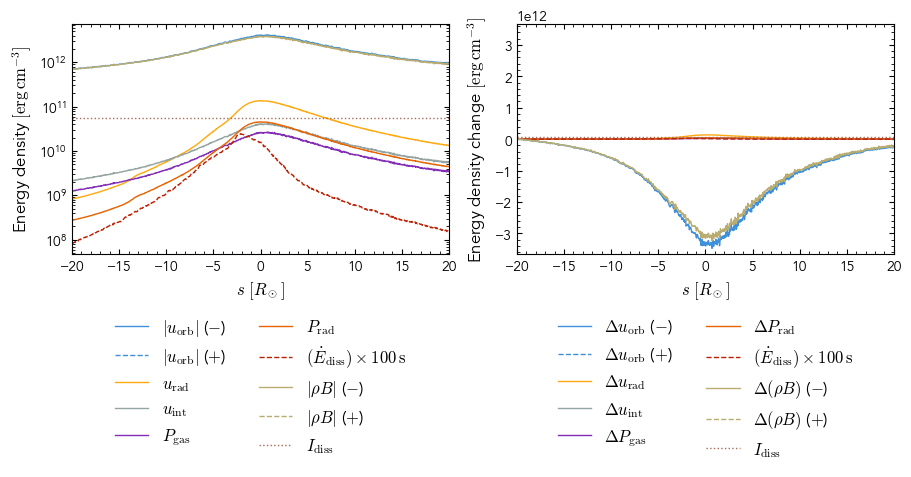

Mass-flux quadrature: 256 pixels per plane axis; max change on doubling resolution at five slices = 0.19% (relative to forward + |reverse|).
Net mass flux: upstream = 13.086201949175196 Msun/yr ; downstream = 12.917946829403814 Msun/yr ; range = 12.820543108100535 Msun/yr to 13.397010711398854 Msun/yr
Mass-flux specific-energy / heating-rate convergence: 0.42%; area-integrated heating convergence: 0.45%.
Heating reference: integral(q dA ds) / upstream net Mdot; upstream net Mdot = 13.086201949175196 Msun/yr ; max |reverse| / forward = 0.19%.
Net mass-flux-weighted specific energy ; integrated heating = 3450578914134675.5 erg/g


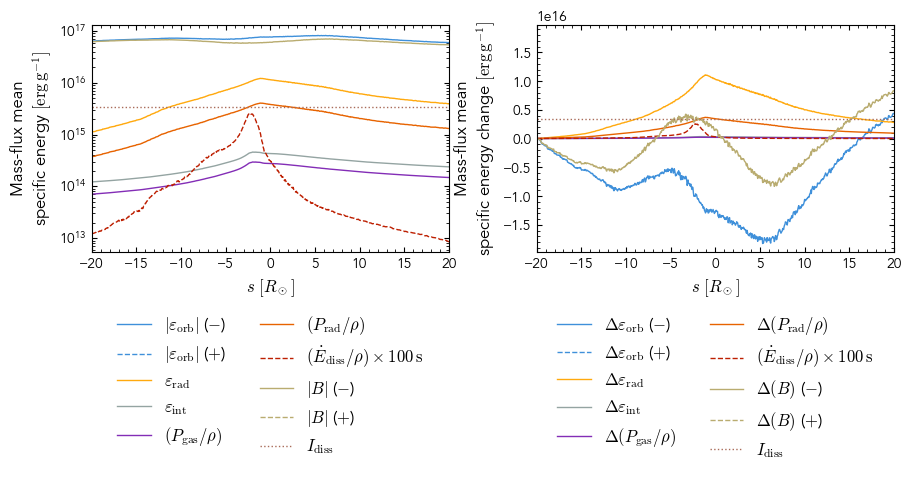

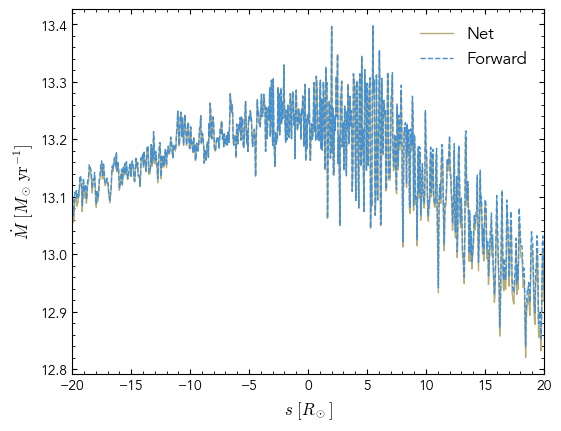

Snapshot 77, time = [2.65338265] day (0.999 t_fb)


Streamline seed cell: 21640730 at [ 1.14450763e+01 -4.89275355e+00  4.36986917e-03] Rsun ; density = 0.00015594935750312919 g/cm**3 ; r_seed / r_p = 0.9693725000079253 dimensionless ; positive s follows the 3D velocity


Native particle visits: 409 from 801 tracing samples


Projected time scales along the flow: nearest grid columns; max XY offset = 0.16295748848575878 Rsun
Photospheres: full snapshot z bounds = [-3537.06607603  3070.91925725] Rsun ; 210 unique XY columns; found 420 of 420 observer surfaces; search steps per ray = (np.int64(245), np.int64(450))
Mean photosphere height range = (unyt_quantity(4.29662707, 'Rsun'), unyt_quantity(34.09640779, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(303038.85799922, 'dimensionless'), unyt_quantity(4211643.34997116, 'dimensionless')) ; native-nearest trapezoids, no density cut


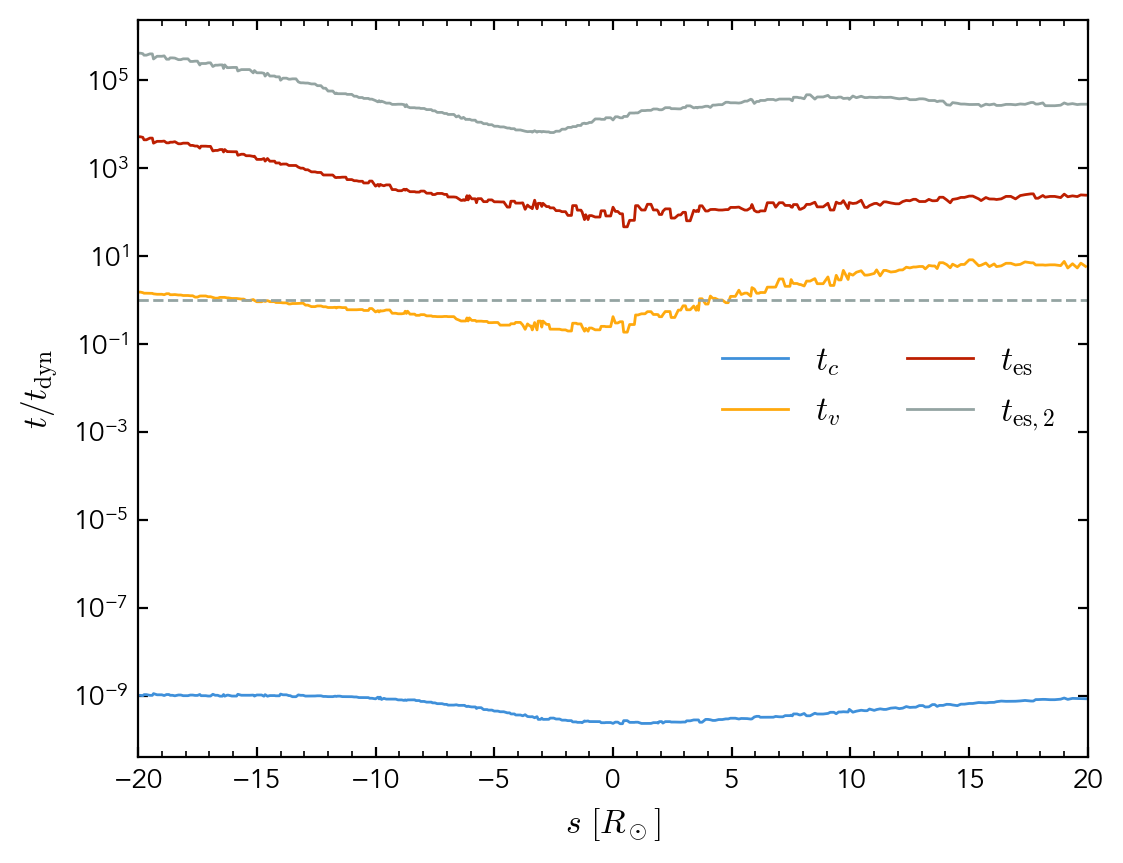

Single-cell column diagnostic: 1e4, snapshot 77
  cell, s<0: p=-2.214, R^2=0.985, N=246
  cell, s>0: p=-0.507, R^2=0.828, N=162
  column, s<0: p=-1.708, R^2=0.988, N=246
  column, s>0: p=-0.285, R^2=0.600, N=162


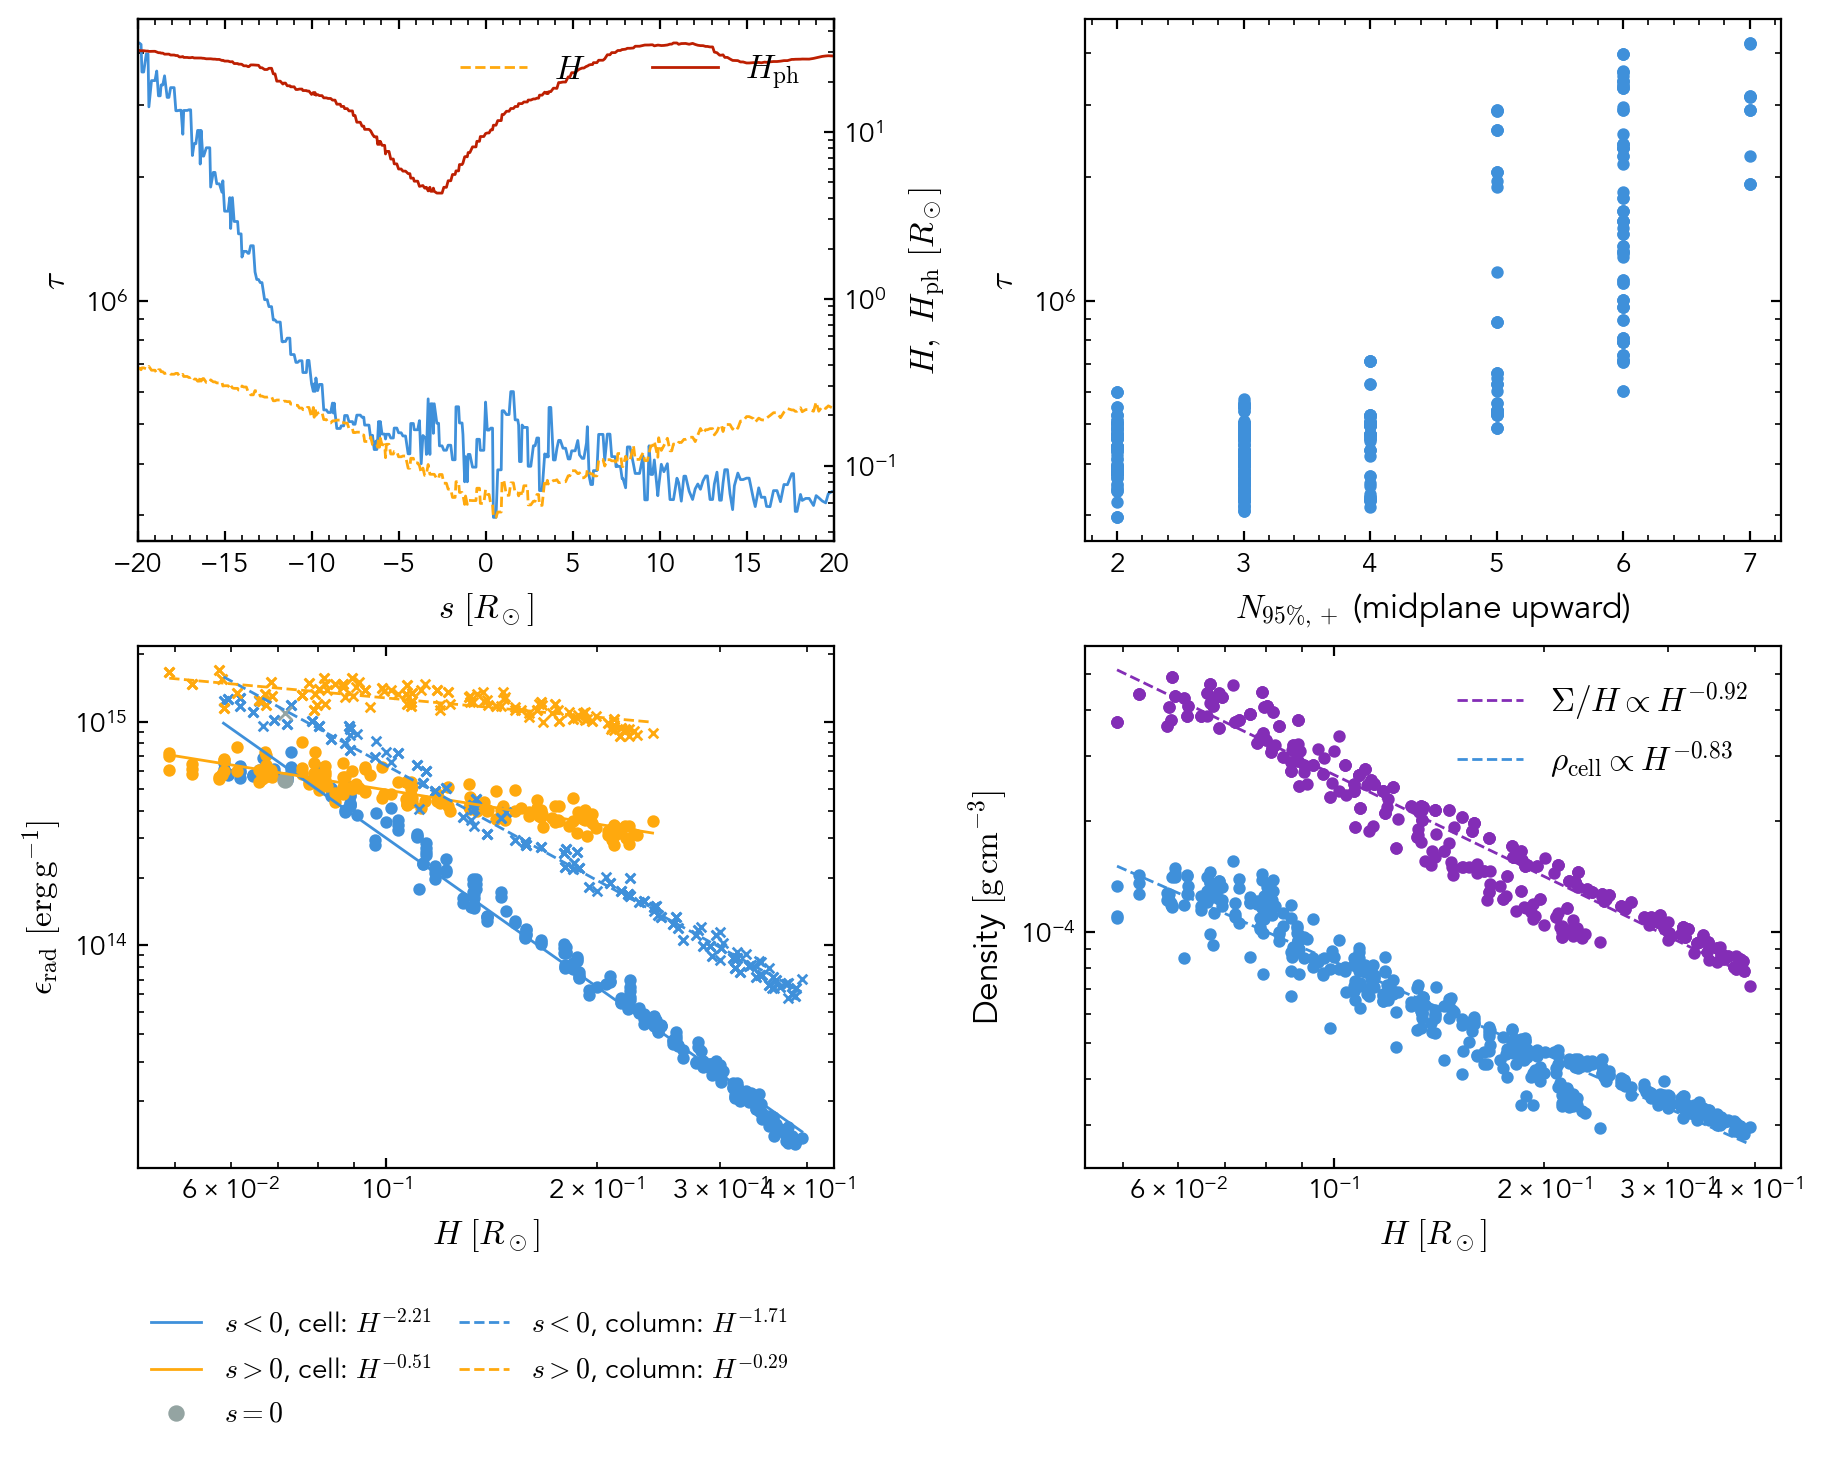

Streamline height: z range = 0.0016776707538442449 Rsun to 0.05724902905286437 Rsun


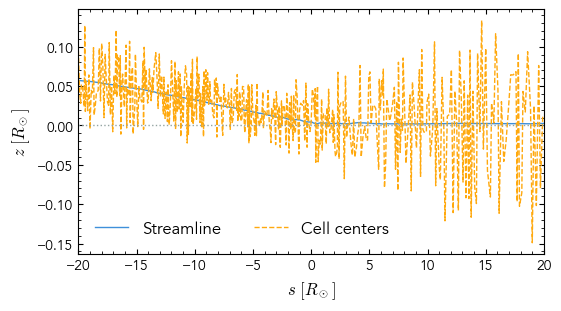

Integral of dissipation / speed over the 40 Rsun streamline: 37777594008.41851 erg/cm**3


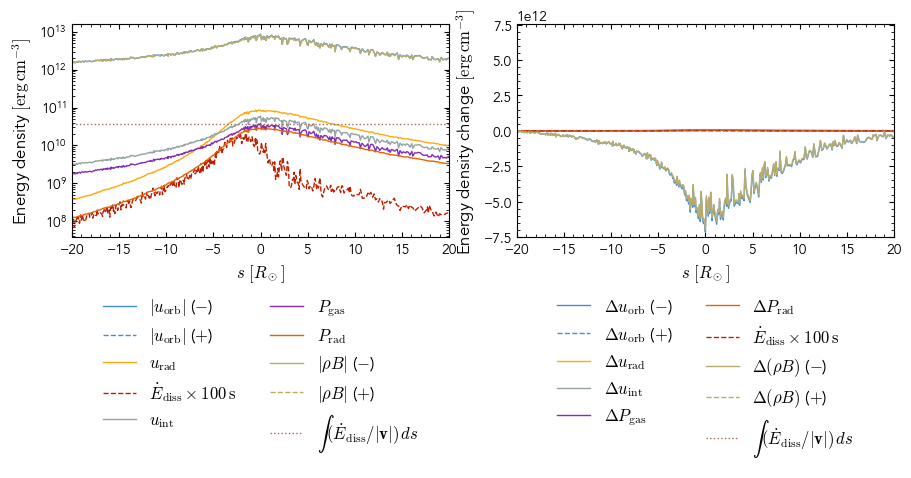

Single-cell specific energy ; integrated heating = 425786257210252.0 erg/g


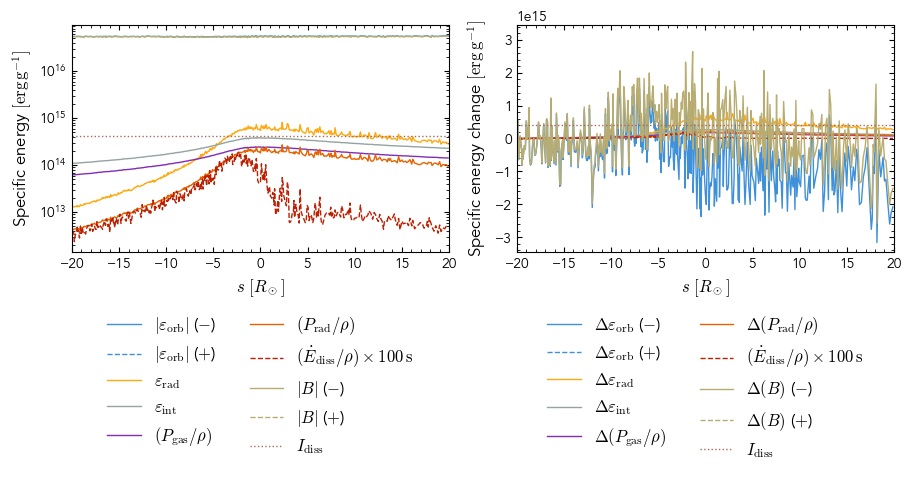

Perpendicular slices: radius = 38.52092231089054 Rsun ; rho > 1.5594935750312919e-09 g/cm**3 (1e-05 times seed density); r dot r_c(s) > 0; harmonic core included; native cells per slice = 3407 to 9535
Slice-averaged specific energy ; integrated heating = 1698184060237424.0 erg/g


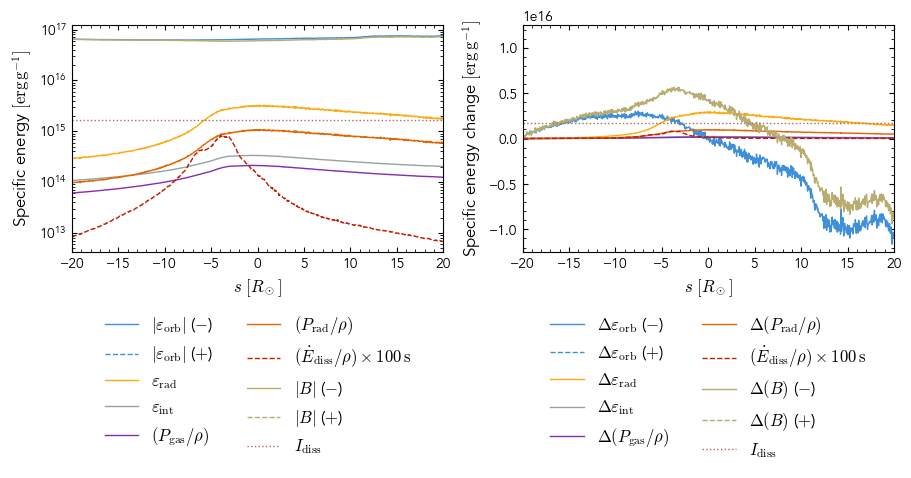

Slice-averaged energy density ; integrated heating = 27950549610.740417 erg/cm**3


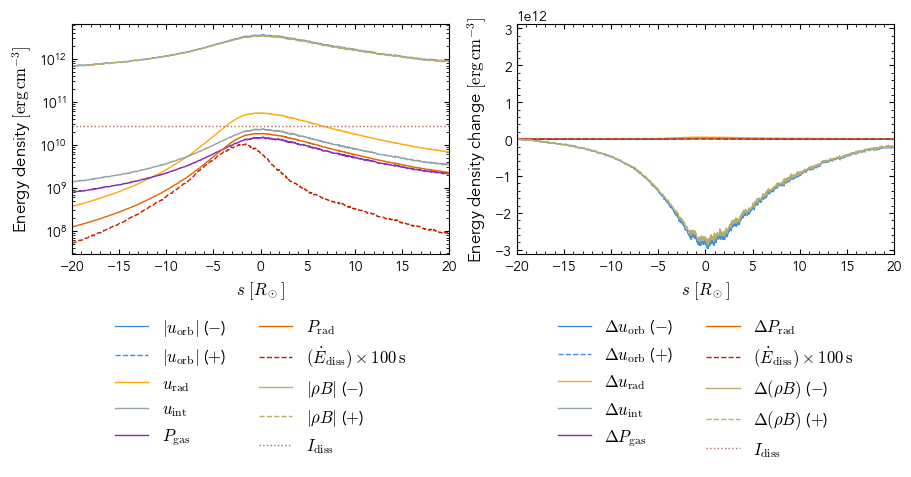

Mass-flux quadrature: 256 pixels per plane axis; max change on doubling resolution at five slices = 0.15% (relative to forward + |reverse|).
Net mass flux: upstream = 6.00224224404534 Msun/yr ; downstream = 5.797543497057224 Msun/yr ; range = 5.724598703272517 Msun/yr to 6.00224224404534 Msun/yr
Mass-flux specific-energy / heating-rate convergence: 0.22%; area-integrated heating convergence: 0.05%.
Heating reference: integral(q dA ds) / upstream net Mdot; upstream net Mdot = 6.00224224404534 Msun/yr ; max |reverse| / forward = 0.03%.
Net mass-flux-weighted specific energy ; integrated heating = 1593672007695113.5 erg/g


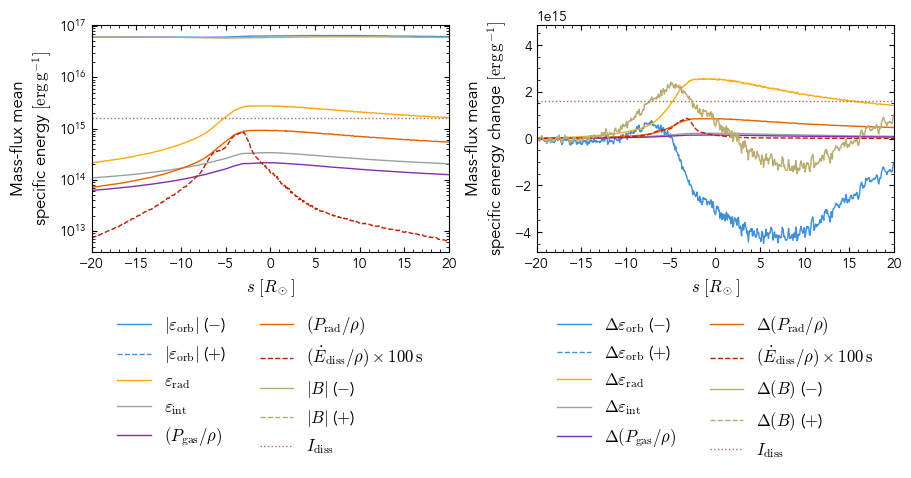

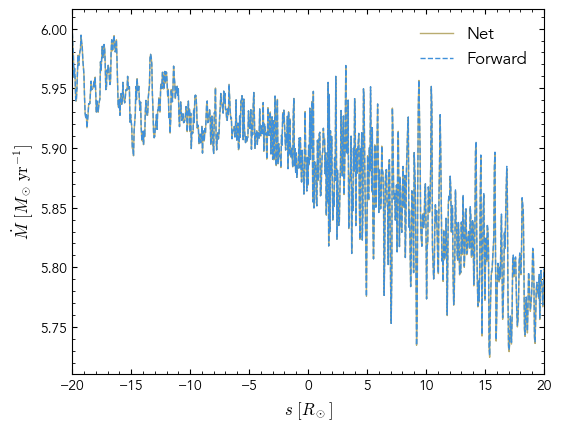

Snapshot 62, time = [1.86088432] day (0.701 t_fb)


Streamline seed cell: 40481769 at [ 1.19412606e+01 -3.47065047e+00  1.05657472e-02] Rsun ; density = 2.438843796092837e-05 g/cm**3 ; r_seed / r_p = 0.968466087307658 dimensionless ; positive s follows the 3D velocity


Native particle visits: 393 from 801 tracing samples


Projected time scales along the flow: nearest grid columns; max XY offset = 0.15716621811071813 Rsun
Photospheres: full snapshot z bounds = [-1916.7182177   2209.48716538] Rsun ; 212 unique XY columns; found 424 of 424 observer surfaces; search steps per ray = (np.int64(125), np.int64(400))
Mean photosphere height range = (unyt_quantity(0.45859549, 'Rsun'), unyt_quantity(30.89770249, 'Rsun')) ; mean midplane-to-photosphere tau range = (unyt_quantity(41277.8218426, 'dimensionless'), unyt_quantity(301689.61115898, 'dimensionless')) ; native-nearest trapezoids, no density cut


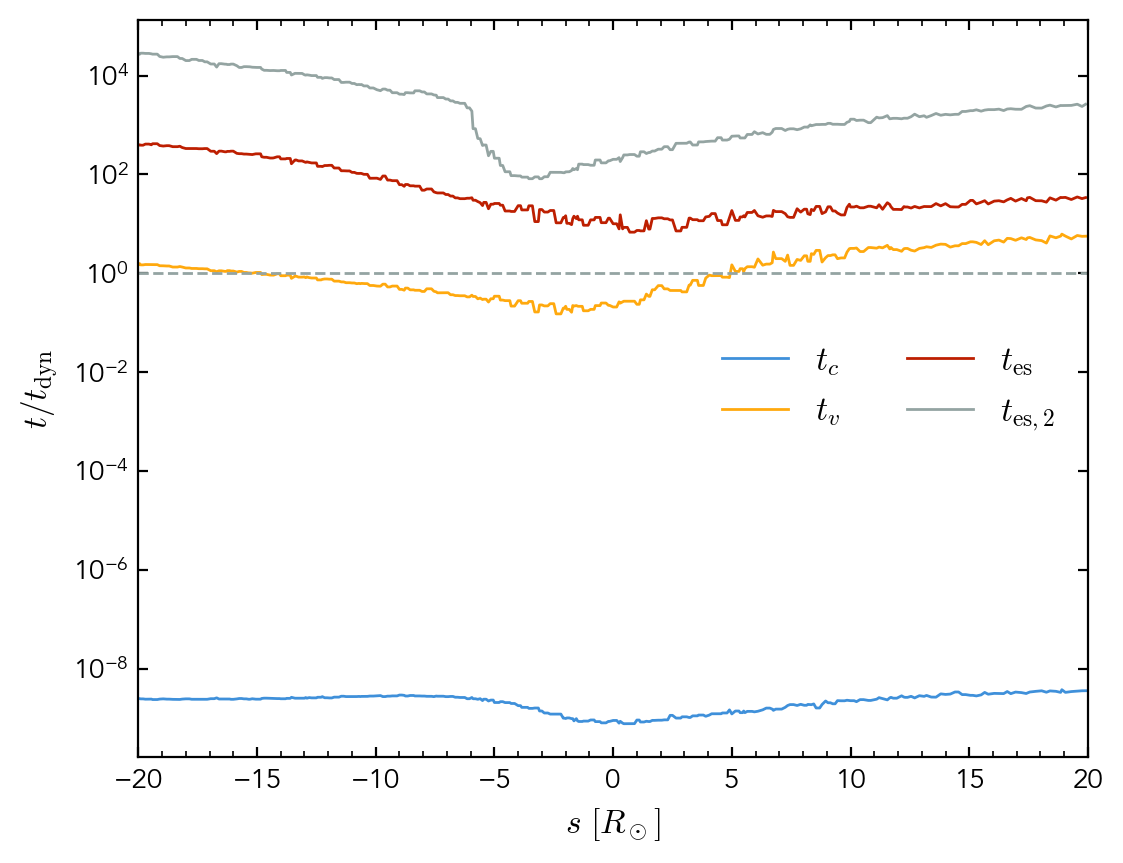

Single-cell column diagnostic: 1e4, snapshot 62
  cell, s<0: p=-1.693, R^2=0.985, N=231
  cell, s>0: p=-0.620, R^2=0.870, N=161
  column, s<0: p=-1.410, R^2=0.983, N=231
  column, s>0: p=-0.373, R^2=0.739, N=161


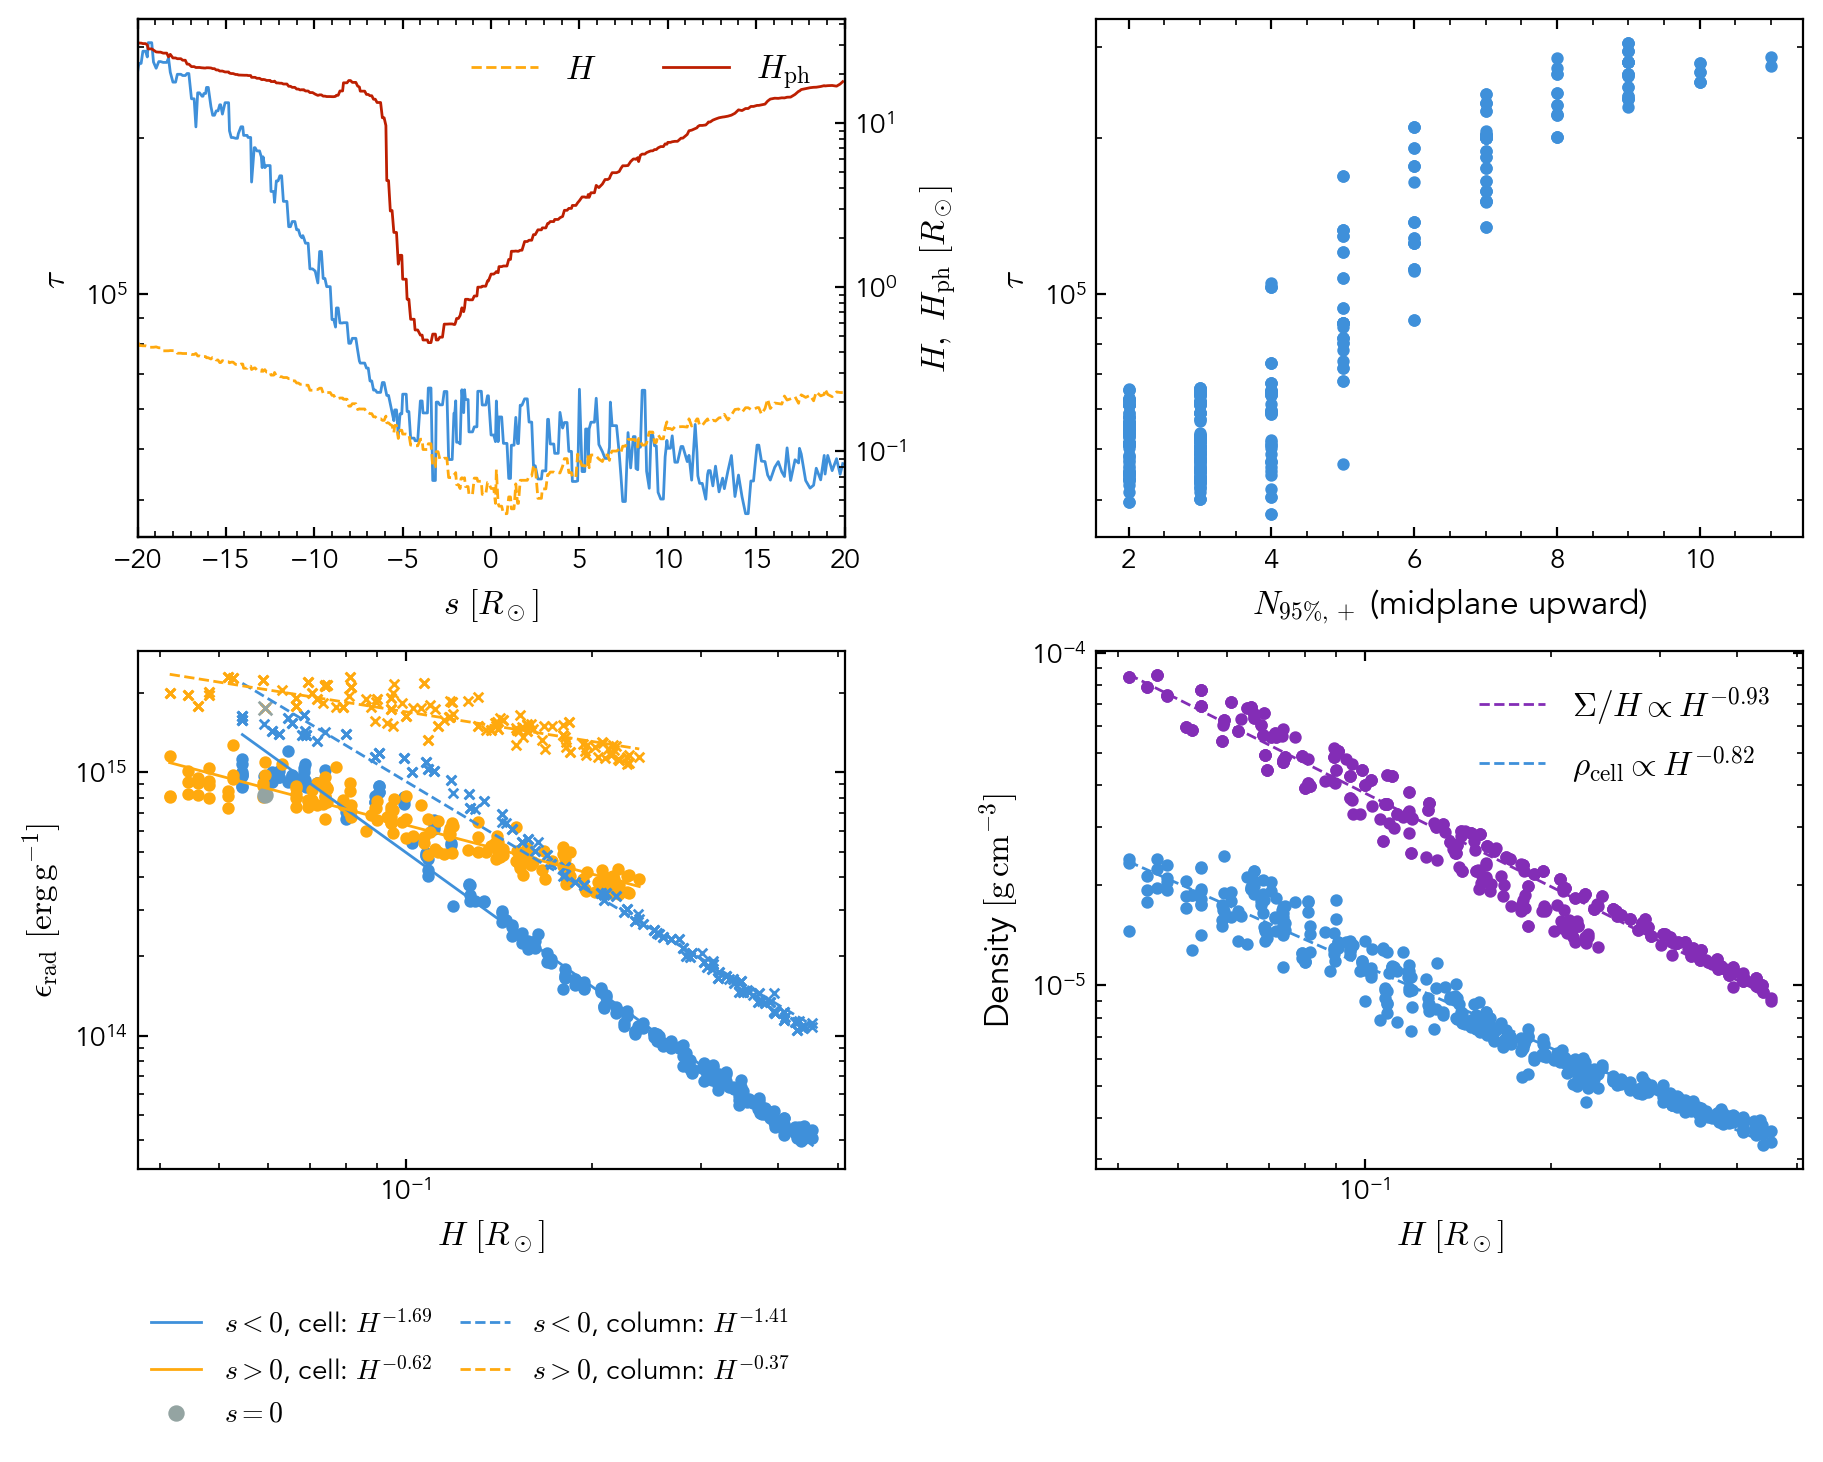

Streamline height: z range = 0.006268297477376902 Rsun to 0.08620484517132582 Rsun


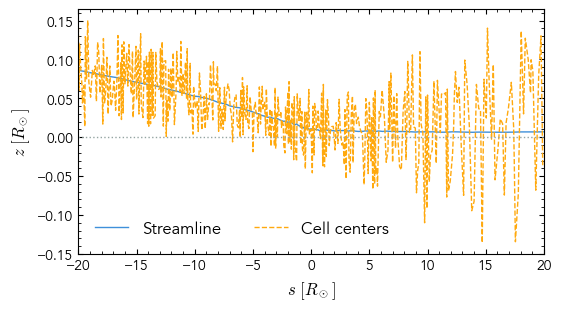

Integral of dissipation / speed over the 40 Rsun streamline: 7334663962.18349 erg/cm**3


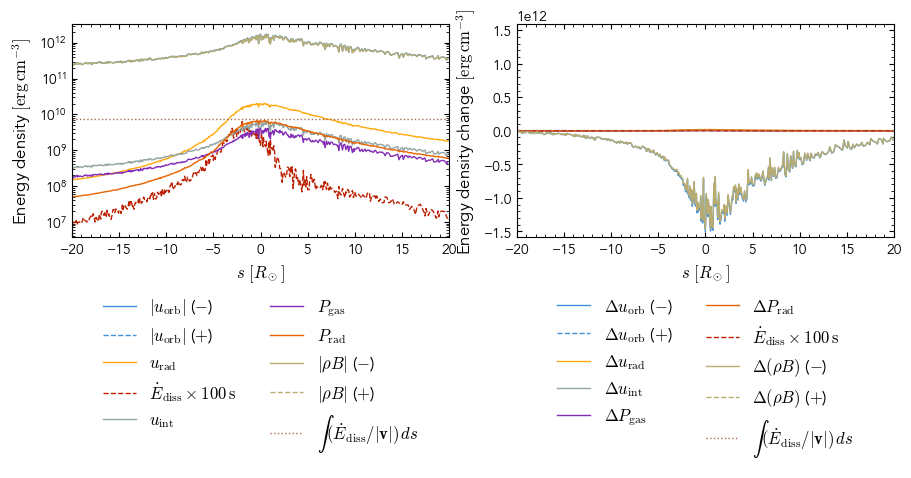

Single-cell specific energy ; integrated heating = 560413682004431.06 erg/g


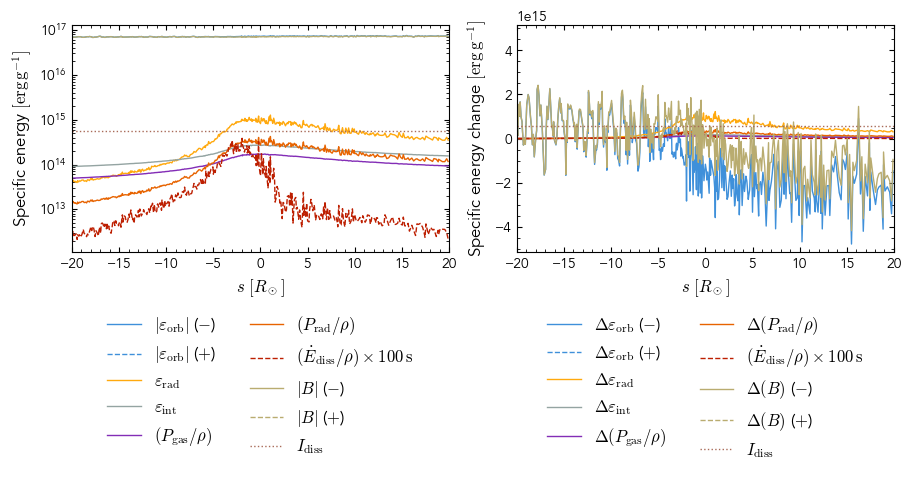

Perpendicular slices: radius = 38.52092231089054 Rsun ; rho > 2.4388437960928373e-10 g/cm**3 (1e-05 times seed density); r dot r_c(s) > 0; harmonic core included; native cells per slice = 2610 to 8521
Slice-averaged specific energy ; integrated heating = 2426514487505201.5 erg/g


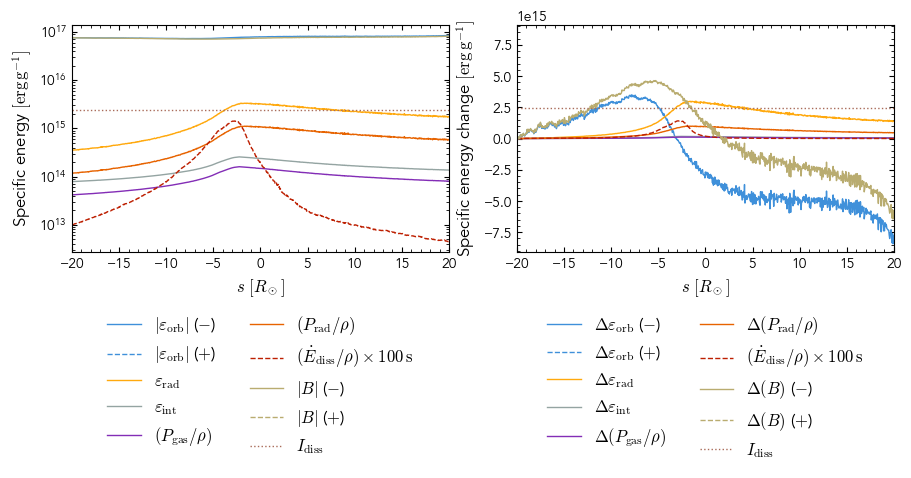

Slice-averaged energy density ; integrated heating = 5674448918.421303 erg/cm**3


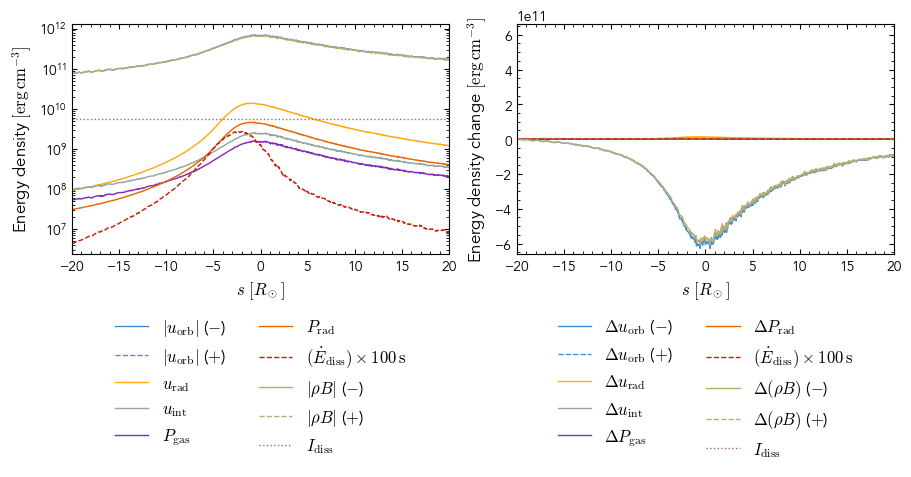

Mass-flux quadrature: 256 pixels per plane axis; max change on doubling resolution at five slices = 0.07% (relative to forward + |reverse|).
Net mass flux: upstream = 0.9949973342522 Msun/yr ; downstream = 0.9436065788149303 Msun/yr ; range = 0.9285738305370783 Msun/yr to 1.0026174221513615 Msun/yr
Mass-flux specific-energy / heating-rate convergence: 1.81%; area-integrated heating convergence: 1.53%.
Heating reference: integral(q dA ds) / upstream net Mdot; upstream net Mdot = 0.9949973342522 Msun/yr ; max |reverse| / forward = 0.02%.
Net mass-flux-weighted specific energy ; integrated heating = 2293731330309218.5 erg/g


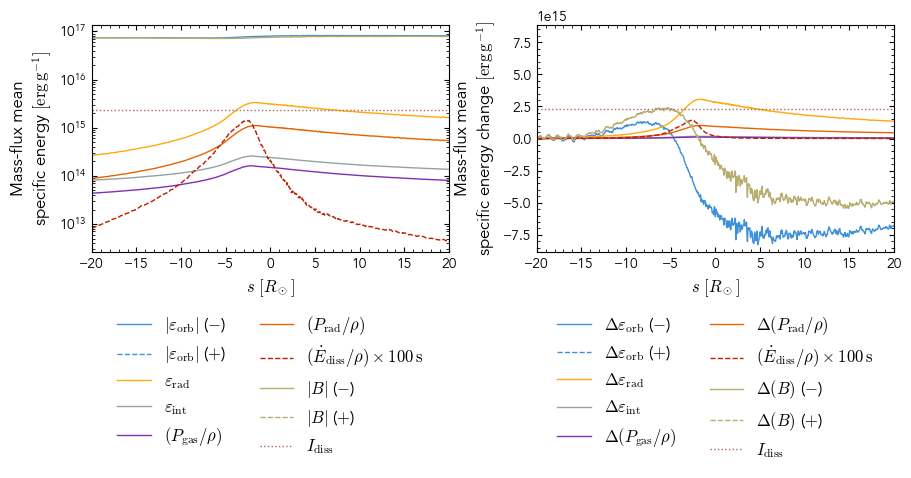

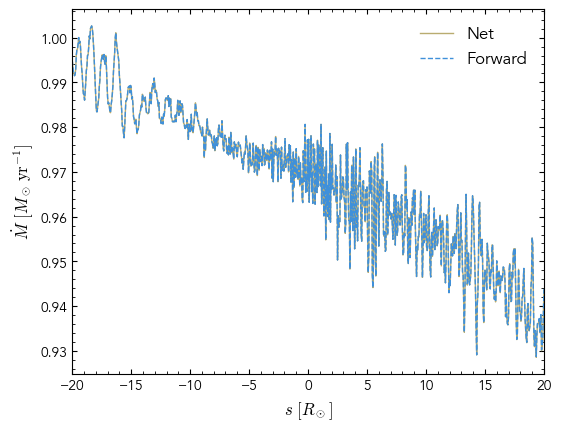

In [13]:
RUN = "1e4"
RSTAR, MSTAR, MBH = (
    0.47 * richio.units.lscale,
    0.5 * richio.units.mscale,
    1e4 * richio.units.mscale,
)
r_p = float((RSTAR * (MBH / MSTAR) ** (1 / 3)).in_units("code_length"))

XY = 30

TFBS = [0.7, 1.0, 1.5, 2.2]
SNAPSHOTS = dev.SNAPSHOT_TFB(RUN, TFBS)

t_dyn = np.sqrt(RSTAR**3 / (u.G * MSTAR))
t_fb = dev.TDEBasics(MBH, MSTAR, RSTAR).t_fb
print(
    "Run:",
    RUN,
    "\nStellar dynamical time:",
    t_dyn.in_units("s"),
    "\nFallback time:",
    t_fb.in_units("day"),
)

for SNAPDIR in list(reversed(SNAPSHOTS))[:SNAPSHOT_LIMIT]:
    snapnum = int(os.path.splitext(os.path.basename(SNAPDIR))[0].rsplit("_", 1)[1])
    snap = richio.load(SNAPDIR)
    time_in_tfb = np.asarray((snap.time / t_fb).to_value("dimensionless")).item()
    print(
        f"Snapshot {snapnum}, time = {snap.time.in_units('day')} "
        f"({time_in_tfb:.3f} t_fb)"
    )

    native = load_native_fields(snap)
    seed_cell = get_max_density_cell(native, r_p)
    streamline = get_streamline(native, seed_cell)

    # Calculate, plot, then release each diagnostic group before starting the next.
    tree = cKDTree(
        np.column_stack([axis.to_value("Rsun") for axis in native["position"]])
    )
    columns = compute_column_profiles(snap, native, streamline, r_p, XY, tree)
    plot_timescales(streamline, columns, t_dyn)
    plot_column_diagnostics(streamline, columns, RUN, snapnum)
    del columns, tree
    plot_streamline_height(streamline)

    energy_fields = compute_energy_fields(native, MBH, r_p)
    single = compute_single_cell_profiles(native, streamline, energy_fields)
    plot_single_cell_energy_density(streamline, single)
    plot_single_cell_specific_energy(streamline, single)
    del single

    slices = compute_slice_profiles(native, streamline, energy_fields, r_p, seed_cell)
    plot_slice_specific_energy(streamline, slices)
    plot_slice_energy_density(streamline, slices)
    del slices

    flux = compute_mass_flux_profiles(native, streamline, energy_fields, r_p, seed_cell)
    plot_flux_specific_energy(streamline, flux)
    plot_mass_flux(streamline, flux)
    del flux, energy_fields, streamline, native, snap